# Configuration

## Experiment

In [1]:
CLASS_SCHEME = "minimized"
USE_SMOTE = True
USE_PCA = True
RANDOM_STATE = 42

## Hardware

In [2]:
USE_CUDA = True
CONVERSION_N_JOBS = -1
EDA_N_JOBS = 8
CLEANING_N_JOBS = 8
DEDUPLICATION_N_JOBS = 8
GRID_SEARCH_N_JOBS = 1

## Sizes

In [3]:
CHUNK_SIZE = 100_000  # rows read at a time from a CSV file
BATCH_SIZE = 500_000  # rows read at a time from a parquet split
PREDICTION_BATCH_SIZE = 250_000

TRAIN_SAMPLE_SIZES = {
    "knn": None,
    "svm": 1_000_000,
    "rf": 1_000_000,
    "xgb": None,
    "logreg": None,
}

GRID_SEARCH_SAMPLE_SIZES = {
    "knn": 250_000,
    "svm": 200_000,
    "rf": 800_000,
    "xgb": 1_000_000,
    "logreg": 1_000_000,
}

MIN_ROWS_PER_CLASS = 20

## Experiment Design

In [4]:
TEST_SIZE = 0.2
N_SPLITS = 5
VALIDATION_SIZE = 0.2
PCA_VARIANCE_THRESHOLD = 0.95
SMOTE_K_NEIGHBORS_GRID = [3, 5, 7]
# the classes ranked below this rank by row count, Benign included, are oversampled to its row count
SMOTE_TARGET_RANK = 3

NOISE_MAGNITUDES = {
    "gaussian": 1.0,
    "uniform": 1.0,
    "multiplicative": 0.5,
    "missing": 0.5,  # the share of the features of a noisy row that go missing
}

NOISE_INTENSITIES = [0.1, 0.2, 0.3]

## Class Schemes

In [5]:
CLASS_SCHEMES = {
    "original": None,
    "minimized": {
        "Benign": "Benign",
        "Bot": "Bot",
        "FTP-BruteForce": "Brute Force",
        "SSH-Bruteforce": "Brute Force",
        "Brute Force -Web": "Brute Force",
        "Brute Force -XSS": "Brute Force",
        "DDOS attack-HOIC": "DoS",
        "DDOS attack-LOIC-UDP": "DoS",
        "DDoS attacks-LOIC-HTTP": "DoS",
        "DoS attacks-GoldenEye": "DoS",
        "DoS attacks-Hulk": "DoS",
        "DoS attacks-SlowHTTPTest": "DoS",
        "DoS attacks-Slowloris": "DoS",
        "Infilteration": "Infiltration",
        "SQL Injection": "SQL Injection",
    },
}

## Run Flags

In [6]:
RUN_EDA = True
OVERWRITE_DATA_PIPELINE = False
OVERWRITE_PREDICTIONS = False
SAVE_CONFIDENCE = True
SAVE_MATRIX_PLOTS = True
SHOW_NOISY_MATRICES = False

## Experiment Name

In [7]:
if CLASS_SCHEME not in CLASS_SCHEMES:
    raise ValueError(f"CLASS_SCHEMES has no class scheme {CLASS_SCHEME!r}")
CLASS_MAPPING = CLASS_SCHEMES[CLASS_SCHEME]

if USE_SMOTE:
    SMOTE_SETTING = "with-smote"
    SMOTE_LABEL = "With SMOTE"
else:
    SMOTE_SETTING = "wout-smote"
    SMOTE_LABEL = "Without SMOTE"

if USE_PCA:
    PCA_SETTING = "with-pca"
    PCA_LABEL = "With PCA"
    MODEL_INPUTS_LABEL = "principal components"
else:
    PCA_SETTING = "wout-pca"
    PCA_LABEL = "Without PCA"
    MODEL_INPUTS_LABEL = "scaled features"

EXPERIMENT_DIMENSIONS = {
    "classes": CLASS_SCHEME,
    "smote": SMOTE_SETTING,
    "pca": PCA_SETTING,
}
EXPERIMENT = "_".join(EXPERIMENT_DIMENSIONS.values())
EXPERIMENT_LABEL = f"{CLASS_SCHEME.capitalize()} Classes, {SMOTE_LABEL}, {PCA_LABEL}"

# Dependencies

## Code

In [8]:
import time
import queue
import threading
import warnings
import multiprocessing
from functools import partial
from typing import Any, Callable, Iterator, Literal, cast
from IPython.display import Markdown

## Status

In [9]:
def print_status(message: str) -> None:
    print(f"\r{message:<80}", end="", flush=True)


def end_status(message: str = "") -> None:
    print(f"\r{message:<80}", flush=True)

In [10]:
def format_duration(seconds: float) -> str:
    minutes, remaining_seconds = divmod(int(seconds), 60)
    hours, remaining_minutes = divmod(minutes, 60)
    return f"{hours:02d}:{remaining_minutes:02d}:{remaining_seconds:02d}"

In [11]:
def print_progress(
    current: int,
    total: int,
    prefix: str = "",
    width: int = 30,
    started: float | None = None,
    suffix: str = "",
) -> None:
    fraction = current / total if total else 0
    filled = int(width * fraction)
    bar = "█" * filled + "-" * (width - filled)
    message = f"{prefix} |{bar}| {current}/{total} ({fraction:.0%})"
    if started is not None:
        elapsed = time.time() - started
        message += f" | {format_duration(elapsed)} elapsed"
        if 0 < current < total:
            message += f", ~{format_duration(elapsed / current * (total - current))} left"
    if suffix:
        message += f" | {suffix}"
    print_status(message)

In [12]:
class GridSearchProgress:
    def __init__(self, total: int, prefix: str, refresh_seconds: float = 10) -> None:
        self.total = total
        self.prefix = prefix
        self.refresh_seconds = refresh_seconds
        self.fitted = 0
        self.scored = 0
        self.failed = 0
        self.started = time.time()
        self.manager = multiprocessing.get_context("spawn").Manager()
        self.events = self.manager.Queue()
        self.listener = threading.Thread(target=self.listen, daemon=True)
        self.listener.start()

    def show(self) -> None:
        suffix = f"{self.fitted} fitted, {self.failed} failed"
        print_progress(self.scored + self.failed, self.total, self.prefix, started=self.started, suffix=suffix)

    def listen(self) -> None:
        while True:
            self.show()
            try:
                event = self.events.get(timeout=self.refresh_seconds)
            except queue.Empty:
                continue
            if event is None:
                return
            if event == "fitted":
                self.fitted += 1
            elif event == "scored":
                self.scored += 1
            else:
                self.failed += 1

    def close(self) -> None:
        self.events.put(None)
        self.listener.join()
        self.manager.shutdown()

## OS, Systems, and File's Manager

In [13]:
import os
import sys
import gc
import ctypes
import shutil
import hashlib
import joblib
import json

### Dump and Load

In [14]:
def load(object_path: str) -> Any:
    return joblib.load(object_path)

In [15]:
def dump(obj: Any, dump_path: str) -> None:
    os.makedirs(os.path.dirname(dump_path) or ".", exist_ok=True)
    joblib.dump(obj, dump_path)

### Data Stages

In [16]:
STAGE_MARKER_FILE_NAME = "_DONE.json"


def get_stage_marker_path(output_path: str, marker_file_name: str = STAGE_MARKER_FILE_NAME) -> str:
    # a folder keeps its marker inside, a file gets one beside it
    root, extension = os.path.splitext(output_path)
    if extension:
        return f"{root}{marker_file_name}"
    return os.path.join(output_path, marker_file_name)

In [17]:
def load_stage_settings(output_path: str) -> dict | None:
    marker_path = get_stage_marker_path(output_path)
    if not os.path.exists(output_path) or not os.path.exists(marker_path):
        return None
    with open(marker_path, "r", encoding="utf-8") as file:
        return json.load(file)

In [18]:
def dump_stage_settings(output_path: str, settings: dict) -> None:
    marker_path = get_stage_marker_path(output_path)
    os.makedirs(os.path.dirname(marker_path) or ".", exist_ok=True)
    with open(marker_path, "w", encoding="utf-8") as file:
        json.dump(settings, file, indent=4)

In [19]:
def reset_stage(output_path: str) -> None:
    # a rebuilt stage starts empty, so no file of an earlier build is read along with the new ones
    if os.path.isdir(output_path):
        shutil.rmtree(output_path)
    elif os.path.exists(output_path):
        os.remove(output_path)
    marker_path = get_stage_marker_path(output_path)
    if os.path.exists(marker_path):
        os.remove(marker_path)

In [20]:
def run_stage(
    output_path: str,
    settings: dict,
    build: Callable[[], Any],
    overwrite: bool = OVERWRITE_DATA_PIPELINE,
) -> Any:
    # a stage built with the same settings is skipped, any other settings (another RANDOM_STATE, too) rebuild it
    if not overwrite and load_stage_settings(output_path) == settings:
        end_status(f"{output_path} is already built with the same settings, skipped")
        return None
    reset_stage(output_path)
    result = build()
    dump_stage_settings(output_path, settings)
    return result

### Configurations

In [21]:
ROW_INDEX_COLUMN = "row_index"

### Loading Data

In [22]:
def get_file_paths_in_folder(folder_path: str, file_extension: str) -> list[str]:
    file_paths = []
    for file_name in os.listdir(folder_path):
        if file_name.endswith(f".{file_extension}"):
            file_paths.append(os.path.join(folder_path, file_name))
    return sorted(file_paths)

### File's Path

In [23]:
# shared by every experiment
PATH_FOLDER_ORIGINAL_DATASET = "cse-cic-ids2018"
PATH_FOLDER_DATA_PIPELINE = "data-pipeline"
PATH_FOLDER_PARQUET_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "01-raw-parquet")
PATH_FOLDER_CLEANED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "02-cleaned-parquet")

In [24]:
# shared by the experiments of the class scheme, with and without SMOTE
PATH_FOLDER_DEDUPLICATED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "03-deduplicated-parquet", CLASS_SCHEME)
PATH_FOLDER_SPLITTED_DATASET = os.path.join(PATH_FOLDER_DATA_PIPELINE, "04-splitted-parquet", CLASS_SCHEME)
PATH_FOLDER_SPLITTED_DATASET_TRAIN = os.path.join(PATH_FOLDER_SPLITTED_DATASET, "train")
PATH_FOLDER_SPLITTED_DATASET_TEST = os.path.join(PATH_FOLDER_SPLITTED_DATASET, "test")
PATH_FOLDER_NOISY_DATASET_TEST = os.path.join(PATH_FOLDER_DATA_PIPELINE, "06-noisy-parquet", CLASS_SCHEME)
PATH_FOLDER_NOISE_EVALUATION = os.path.join("noise-evaluation", CLASS_SCHEME)

In [25]:
# one folder per experiment in each of them
PATH_FOLDER_CACHE = "cache"
PATH_FOLDER_GRID_SEARCH = "grid-search-results"
PATH_FOLDER_TRAINED_MODEL = "trained-models"
PATH_FOLDER_PREDICTIONS = "predictions"
PATH_FOLDER_PREDICTION_CONFUSION_MATRICES = "prediction-cm"
PATH_FOLDER_EVALUATION = "evaluation"
PATH_FOLDER_EXPERIMENT_CACHE = os.path.join(PATH_FOLDER_CACHE, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_GRID_SEARCH = os.path.join(PATH_FOLDER_GRID_SEARCH, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_TRAINED_MODEL = os.path.join(PATH_FOLDER_TRAINED_MODEL, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_PREDICTIONS = os.path.join(PATH_FOLDER_PREDICTIONS, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_PREDICTION_CONFUSION_MATRICES = os.path.join(PATH_FOLDER_PREDICTION_CONFUSION_MATRICES, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_EVALUATION = os.path.join(PATH_FOLDER_EVALUATION, EXPERIMENT)
PATH_FOLDER_EXPERIMENT_EVALUATION_MATRICES = os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, "matrices")

PATH_JSON_CLASSES_LIST = os.path.join(PATH_FOLDER_EXPERIMENT_CACHE, "classes.json")
PATH_LABEL_ENCODER_TRANSFORMER = os.path.join(PATH_FOLDER_EXPERIMENT_CACHE, "label-encoder-transformer.pkl")
PATH_PREPROCESSING_TRANSFORMER = os.path.join(PATH_FOLDER_EXPERIMENT_CACHE, "preprocessing-transformer.pkl")

### File's Name

In [26]:
FEATURES_FILE_NAME = "features.parquet"
LABELS_FILE_NAME = "labels.parquet"
ENCODED_LABELS_FILE_NAME = "encoded-labels.parquet"

# noisy datasets
NOISE_CHECK_FILE_NAME = "noise-check.csv"

# predictions
PREDICTIONS_FILE_NAME = "predictions.parquet"

# evaluation results
OUTCOME_COUNTS_FILE_NAME = "outcome-counts.parquet"
DISPLACEMENT_BINS_FILE_NAME = "displacement-bins.csv"
METRICS_FILE_NAME = "metrics.csv"
DEGRADATION_FILE_NAME = "degradation.csv"
ROBUSTNESS_RANKING_FILE_NAME = "robustness-ranking.csv"
MIXTURE_CHECK_FILE_NAME = "mixture-check.csv"
CLASS_METRICS_FILE_NAME = "class-metrics.csv"
ERROR_COMPOSITION_FILE_NAME = "error-composition.csv"
PREDICTION_SUMMARIES_FILE_NAME = "prediction-summaries.csv"
KEY_FINDINGS_FILE_NAME = "key-findings.csv"
MODEL_COMPARISON_PLOT_FILE_NAME = "model-comparison.png"
ERROR_COMPOSITION_PLOT_FILE_NAME = "error-composition.png"
FLIP_RATE_PLOT_FILE_NAME = "flip-rate-against-displacement.png"
CONFUSION_MATRIX_PLOT_FILE_NAME = "confusion-matrix.png"
PREDICTION_TRANSITIONS_PLOT_FILE_NAME = "prediction-transitions.png"

## Data Processing

In [27]:
import re
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq

In [28]:
if USE_CUDA:
    cuda_root = os.path.join(sys.prefix, "targets", "x86_64-linux")
    if os.path.isdir(os.path.join(cuda_root, "include")):
        os.environ.setdefault("CUDA_PATH", cuda_root)
    os.environ.setdefault("CUDA_CACHE_MAXSIZE", str(4 * 1024**3))

### Configurations

In [29]:
NUMERIC_DATA_TYPE = "float32"
LABEL_COLUMN = "label"
TIMESTAMP_COLUMN = "timestamp"
CLASS_COLUMN = "class"
ROW_COUNT_COLUMN = "rows"

### Batch Processing

In [30]:
def count_rows(dataset: pl.LazyFrame) -> int:
    return dataset.select(pl.len()).collect().item()

In [31]:
def read_in_batches(
    dataset: pl.LazyFrame,
    prefix: str = "Reading batches",
    batch_size: int = BATCH_SIZE,
) -> Iterator[tuple[int, pl.DataFrame]]:
    row_offsets = range(0, count_rows(dataset), batch_size)
    started = time.time()
    print_progress(0, len(row_offsets), prefix, started=started)
    for batch_index, row_offset in enumerate(row_offsets, start=1):
        yield row_offset, dataset.slice(row_offset, batch_size).collect()
        print_progress(batch_index, len(row_offsets), prefix, started=started)

In [32]:
def load_features(
    features: pl.LazyFrame,
    prefix: str = "Loading features",
    batch_size: int = BATCH_SIZE,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    columns = features.collect_schema().names()
    values = np.empty((count_rows(features), len(columns)), dtype=numeric_data_type)
    for row_offset, batch in read_in_batches(features, prefix, batch_size):
        values[row_offset:row_offset + len(batch)] = batch.to_numpy()
    return pd.DataFrame(values, columns=columns)

### Load All Files

In [33]:
def load_all_files(folder_path: str, row_index_column: str = ROW_INDEX_COLUMN) -> pl.LazyFrame:
    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    return pl.scan_parquet(file_paths).with_row_index(row_index_column)

### Classes List

In [34]:
def load_classes_list(file_path: str = PATH_JSON_CLASSES_LIST) -> list[str]:
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

In [35]:
def get_classes_list_from_a_folder(
    folder_path: str,
    file_extension: Literal["csv", "parquet"],
    label_column: str = LABEL_COLUMN,
) -> list[str]:
    if file_extension not in ("csv", "parquet"):
        raise ValueError("file_extension must be 'csv' or 'parquet'")

    classes = set()
    file_paths = get_file_paths_in_folder(folder_path, file_extension)
    started = time.time()
    for file_index, file_path in enumerate(file_paths, start=1):
        if file_extension == "csv":
            dataframe = pd.read_csv(
                file_path,
                usecols=lambda column: normalize_column_name(column) == label_column,
            )
            labels = dataframe.iloc[:, 0]
            labels = labels[labels != labels.name]
        else:
            labels = pd.read_parquet(file_path, columns=[label_column])[label_column]
        classes.update(labels.dropna().unique())
        print_progress(file_index, len(file_paths), "Reading classes", started=started)

    end_status(f"Found {len(classes)} classes in {len(file_paths)} files")
    return sorted(classes)

In [36]:
def create_classes_list_from_a_folder(
    folder_path: str,
    output_path: str = PATH_JSON_CLASSES_LIST,
    label_column: str = LABEL_COLUMN,
) -> list[str]:
    if get_file_paths_in_folder(folder_path, "parquet"):
        file_extension = "parquet"
    elif get_file_paths_in_folder(folder_path, "csv"):
        file_extension = "csv"
    else:
        raise FileNotFoundError(f"No csv or parquet files found in {folder_path}")

    classes = get_classes_list_from_a_folder(folder_path, file_extension, label_column)

    os.makedirs(os.path.dirname(output_path) or ".", exist_ok=True)
    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(classes, file, indent=4)

    return classes

In [37]:
def count_classes_in_split(
    split_folder_path: str,
    labels_file_name: str = LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> pd.Series:
    labels_file_path = os.path.join(split_folder_path, labels_file_name)
    class_counts = pl.scan_parquet(labels_file_path).group_by(label_column).len().collect()
    return class_counts.to_pandas().set_index(label_column)["len"]

### Cast to `float32`

In [38]:
def _to_float32(x:pd.DataFrame):
    return x.astype(np.float32)

### Feature Columns

In [39]:
# the raw timestamp is text, the cleaning turns it into numeric date and time columns
def get_feature_columns(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    non_feature_columns: tuple[str, ...] = (LABEL_COLUMN, TIMESTAMP_COLUMN),
) -> list[str]:
    first_file_path = get_file_paths_in_folder(folder_path, "parquet")[0]
    feature_columns = []
    for column in pq.read_schema(first_file_path).names:
        if column not in non_feature_columns:
            feature_columns.append(column)
    return feature_columns

## Parallel Processing

In [40]:
def create_tasks_list(function: Callable, per_task_arguments: list, *shared_arguments: Any) -> list:
    tasks = []
    for per_task_argument in per_task_arguments:
        task = joblib.delayed(function)(per_task_argument, *shared_arguments)
        tasks.append(task)
    return tasks

In [41]:
def run_tasks_in_parallel(tasks: list, n_jobs: int = -1, prefix: str = "Running tasks"):
    started = time.time()
    print_progress(0, len(tasks), prefix, started=started)
    results = []
    with joblib.parallel_config(backend="loky", inner_max_num_threads=1):
        for result in joblib.Parallel(n_jobs=n_jobs, return_as="generator")(tasks):
            results.append(result)
            print_progress(len(results), len(tasks), prefix, started=started)
    return results

## Segregate Data

In [42]:
def extract_column(
    dataframe: pd.DataFrame,
    source_column: str,
    target_column: str,
    regex: str,
) -> pd.DataFrame:
    dataframe = dataframe.copy()
    dataframe[target_column] = dataframe[source_column].str.extract(regex)[0]
    return dataframe

In [43]:
def group_and_sum(
    dataframe: pd.DataFrame,
    source_column: str,
    group_column: str,
    regex: str,
    value_columns: str | list[str] | None = None,
) -> pd.DataFrame:
    dataframe = extract_column(dataframe, source_column, group_column, regex)

    if value_columns is None:
        value_columns = dataframe.select_dtypes("number").columns.tolist()
    elif isinstance(value_columns, str):
        value_columns = [value_columns]

    return dataframe.groupby(group_column, as_index=False)[value_columns].sum()

## Plotting

In [44]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

### Colors

In [45]:
BAR_COLOR = "#2a78d6"
GRID_COLOR = "#e1e0d9"
TEXT_COLOR = "#0b0b0b"
TEXT_ON_DARK_COLOR = "#ffffff"
EMPTY_CELL_COLOR = "#fcfcfb"
# categorical colors, given to the series in this fixed order
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SERIES_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

SEQUENTIAL_COLORMAP = mcolors.LinearSegmentedColormap.from_list(
    "sequential_blue",
    ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"],
).with_extremes(bad=EMPTY_CELL_COLOR)

DIVERGING_COLORMAP = mcolors.LinearSegmentedColormap.from_list(
    "diverging_blue_red",
    ["#2a78d6", "#f0efec", "#e34948"],
).with_extremes(bad=EMPTY_CELL_COLOR)

FIGURE_DPI = 300  # resolution of the saved figures

### Plot Function

In [46]:
def plot_bar(
    dataframe: pd.DataFrame,
    x: str,
    y: str,
    title: str | None = None,
    xlabel: str | None = None,
    ylabel: str | None = None,
    figsize: tuple[int, int] = (10, 5),
    rotation: int = 45,
    log_scale: bool = False,
) -> None:
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(dataframe[x].astype(str), dataframe[y], color=BAR_COLOR, zorder=3)
    ax.set_title(title or f"{y} per {x}")
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel or y)
    if log_scale:
        ax.set_yscale("log")
    else:
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)
    plt.xticks(rotation=rotation, ha="right")
    plt.tight_layout()
    plt.show()

In [47]:
def plot_heatmap(
    matrix: pd.DataFrame,
    title: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (None, None),
    log_scale: bool = False,
    annotate: bool = False,
    annotation_format: str = ",.0f",
    xlabel: str = "",
    ylabel: str = "",
    colorbar_label: str = "",
    figsize: tuple[int, int] = (12, 10),
    font_size: int = 8,
    save_path: str | None = None,
    show: bool = True,
) -> None:
    values = matrix.to_numpy(dtype=float)
    if log_scale:
        values = np.ma.masked_less_equal(values, 0)
        normalization = mcolors.LogNorm(*value_range)
    else:
        normalization = mcolors.Normalize(*value_range)

    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(values, cmap=colormap, norm=normalization, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(matrix.columns, rotation=90, fontsize=font_size)
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels(matrix.index, fontsize=font_size)
    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label(colorbar_label)

    if annotate:
        for row_index in range(matrix.shape[0]):
            for column_index in range(matrix.shape[1]):
                value = values[row_index, column_index]
                if value is np.ma.masked or np.isnan(value):
                    continue
                if normalization(value) > 0.6:
                    text_color = TEXT_ON_DARK_COLOR
                else:
                    text_color = TEXT_COLOR
                ax.text(
                    column_index,
                    row_index,
                    f"{value:{annotation_format}}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=font_size,
                )

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

## Encode Classes' Label

In [48]:
from sklearn.preprocessing import LabelEncoder, FunctionTransformer

## Pipelines

In [49]:
from imblearn.pipeline import Pipeline
from sklearn.base import clone

### Splitting Datasets

In [50]:
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, GridSearchCV, ParameterGrid

### Features Scaling

In [51]:
from sklearn.preprocessing import StandardScaler

### Principal Component Analysis

In [52]:
from sklearn.decomposition import PCA

### Synthetic Minority Oversampling Technique (SMOTE)

In [53]:
from imblearn.over_sampling import SMOTE

### Models

In [54]:
from cuml import KNeighborsClassifier, SVC, LinearSVC, RandomForestClassifier, LogisticRegression
from xgboost import XGBClassifier

### Metrics

In [55]:
from sklearn.metrics import make_scorer, get_scorer, f1_score, precision_score, recall_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score, confusion_matrix

## Implementation

In [56]:
end_status(f"Experiment {EXPERIMENT} ({EXPERIMENT_LABEL}) writes to:")
for folder_path in [
    PATH_FOLDER_EXPERIMENT_CACHE,
    PATH_FOLDER_EXPERIMENT_GRID_SEARCH,
    PATH_FOLDER_EXPERIMENT_TRAINED_MODEL,
    PATH_FOLDER_EXPERIMENT_PREDICTIONS,
    PATH_FOLDER_EXPERIMENT_PREDICTION_CONFUSION_MATRICES,
    PATH_FOLDER_EXPERIMENT_EVALUATION,
]:
    end_status(f"    {folder_path}")

Experiment minimized_with-smote_with-pca (Minimized Classes, With SMOTE, With PCA) writes to:
    cache/minimized_with-smote_with-pca                                         
    grid-search-results/minimized_with-smote_with-pca                           
    trained-models/minimized_with-smote_with-pca                                
    predictions/minimized_with-smote_with-pca                                   
    prediction-cm/minimized_with-smote_with-pca                                 
    evaluation/minimized_with-smote_with-pca                                    


# CSV To Parquet

## Configurations

In [57]:
# the timestamp is kept as text, the cleaning turns it into numeric date and time columns
COLUMNS_TO_DROP = {
    "flow id",
    "src ip",
    "source ip",
    "src port",
    "source port",
    "dst ip",
    "destination ip",
}

CONVERSION_SETTINGS = {
    "dataset": PATH_FOLDER_ORIGINAL_DATASET,
    "columns_to_drop": sorted(COLUMNS_TO_DROP),
    "numeric_data_type": NUMERIC_DATA_TYPE,
}

## Normalize Columns

In [58]:
def normalize_column_name(column_name: Any) -> str:
    column_name = str(column_name).strip().lower()
    column_name = re.sub(r"[^0-9a-z]+", "_", column_name)
    return column_name.strip("_")

In [59]:
def normalize_column_names(column_names: list) -> list[str]:
    normalized_column_names = []
    for column_name in column_names:
        normalized_column_names.append(normalize_column_name(column_name))
    return normalized_column_names

## Create Schema

In [60]:
def create_schema_columns(folder_path: str, columns_to_drop: set[str] = COLUMNS_TO_DROP) -> list[str]:
    columns = set()
    for file_path in get_file_paths_in_folder(folder_path, "csv"):
        raw_columns = pd.read_csv(file_path, nrows=0).columns.tolist()
        columns.update(normalize_column_names(raw_columns))
    columns -= set(normalize_column_names(list(columns_to_drop)))
    return sorted(columns)

In [61]:
def create_schema(folder_path: str) -> pd.DataFrame:
    columns = create_schema_columns(folder_path)

    dtypes = []
    for column in columns:
        if column in (LABEL_COLUMN, TIMESTAMP_COLUMN):
            dtypes.append("str")
        else:
            dtypes.append(NUMERIC_DATA_TYPE)

    return pd.DataFrame({"column": columns, "dtype": dtypes})

## Cast Numeric Column to `float32`

In [62]:
def cast_numeric_columns(
    dataframe: pd.DataFrame,
    numeric_data_type: Any = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    dataframe = dataframe.copy()

    for column in dataframe.columns:
        if pd.api.types.is_numeric_dtype(dataframe[column]):
            dataframe[column] = dataframe[column].astype(numeric_data_type)

    return dataframe

## Apply Schema Template

In [63]:
def apply_schema_to_dataframe(
    dataframe: pd.DataFrame,
    schema: pd.DataFrame,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    dataframe = dataframe.rename(columns=normalize_column_name)
    dataframe = dataframe.reindex(columns=schema["column"].tolist())

    for column, dtype in zip(schema["column"], schema["dtype"]):
        if not isinstance(dtype, str) or dtype == "":
            continue

        if dtype.startswith(("int", "float")):
            numeric_values = pd.to_numeric(dataframe[column], errors="coerce")
            dataframe[column] = numeric_values.astype(numeric_data_type)
        else:
            try:
                dataframe[column] = dataframe[column].astype(dtype)
            except (ValueError, TypeError) as error:
                warnings.warn(f"Could not cast column '{column}' to {dtype}: {error}")

    return dataframe

## Remove Duplicate Header

In [64]:
def remove_duplicate_header(dataframe: pd.DataFrame) -> pd.DataFrame:
    is_header_row = dataframe.eq(dataframe.columns.tolist(), axis=1).all(axis=1)
    return dataframe[~is_header_row].reset_index(drop=True)

## Clean A Single Chunk

In [65]:
def clean_chunk(dataframe: pd.DataFrame, schema: pd.DataFrame) -> pd.DataFrame:
    dataframe = remove_duplicate_header(dataframe)
    dataframe = apply_schema_to_dataframe(dataframe, schema)
    return dataframe

## Write Chunk to Parquet

In [66]:
def write_chunk_to_parquet(
    chunk: pd.DataFrame,
    chunk_index: int,
    csv_file_path: str,
    output_folder_path: str,
) -> str:
    os.makedirs(output_folder_path, exist_ok=True)
    base_name = os.path.splitext(os.path.basename(csv_file_path))[0]
    output_path = os.path.join(output_folder_path, f"{base_name}_part{chunk_index:04d}.parquet")
    chunk.to_parquet(output_path, index=False)
    return output_path

## Convert A Single CSV

In [67]:
def convert_csv_to_parquet(
    csv_file_path: str,
    schema: pd.DataFrame,
    output_folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    chunk_size: int = CHUNK_SIZE,
) -> list[str]:
    file_name = os.path.basename(csv_file_path)
    parquet_file_paths = []

    with pd.read_csv(csv_file_path, chunksize=chunk_size, low_memory=False) as chunks:
        for chunk_index, chunk in enumerate(chunks):
            chunk_index_interface = chunk_index + 1
            print_status(f"{file_name}: writing chunk {chunk_index_interface}")
            chunk = clean_chunk(chunk, schema)
            parquet_file_path = write_chunk_to_parquet(chunk, chunk_index_interface, csv_file_path, output_folder_path)
            parquet_file_paths.append(parquet_file_path)

    end_status(f"{file_name}: {len(parquet_file_paths)} chunks written")
    return parquet_file_paths

## Convert All CSV Files to Parquet

In [68]:
def convert_all_csv_to_parquet(
    csv_folder_path: str = PATH_FOLDER_ORIGINAL_DATASET,
    n_jobs: int = CONVERSION_N_JOBS,
) -> None:
    csv_file_paths = get_file_paths_in_folder(csv_folder_path, "csv")
    schema = create_schema(csv_folder_path)

    tasks = create_tasks_list(convert_csv_to_parquet, csv_file_paths, schema)
    results = run_tasks_in_parallel(tasks, n_jobs, "Converting CSV files to parquet")

    parquet_file_paths = []
    for result in results:
        parquet_file_paths.extend(result)

    end_status(f"Finished converting {len(csv_file_paths)} CSV files into {len(parquet_file_paths)} parquet files")

## Implementation

In [69]:
run_stage(PATH_FOLDER_PARQUET_DATASET, CONVERSION_SETTINGS, convert_all_csv_to_parquet)

2018-03-01-Thursday_TrafficForML_CICFlowMeter.csv: 4 chunks written             00:00 elapsed
2018-02-21-Wednesday_TrafficForML_CICFlowMeter.csv: 11 chunks written           
2018-03-02-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              
2018-02-14-Wednesday_TrafficForML_CICFlowMeter.csv: 11 chunks written           
2018-02-23-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              :00:17 elapsed, ~00:02:33 left
2018-02-15-Thursday_TrafficForML_CICFlowMeter.csv: 11 chunks written            
2018-02-22-Thursday_TrafficForML_CICFlowMeter.csv: 11 chunks written            :00:17 elapsed, ~00:01:09 left
2018-02-16-Friday_TrafficForML_CICFlowMeter.csv: 11 chunks written              
2018-02-28-Wednesday_TrafficForML_CICFlowMeter.csv: 7 chunks written            :00:18 elapsed, ~00:00:42 left
2018-02-20-Tuesday_TrafficForML_CICFlowMeter.csv: 80 chunks written             
Finished converting 10 CSV files into 168 parquet files                         00:01:2

# Exploratory Data Analysis (EDA)

## Configurations

In [70]:
FILE_COLUMN = "file"
DAY_COLUMN = "day"
FEATURE_COLUMN = "feature"
PERCENTAGE_COLUMN = "percentage"
MISSING_COUNT_COLUMN = "missing"
NAN_COUNT_COLUMN = "nan"
INFINITE_COUNT_COLUMN = "infinite"
UNIQUE_COUNT_COLUMN = "unique"
CORRELATION_COLUMN = "correlation"

DAY_REGEX = r"^(\d{4}-\d{2}-\d{2})"
CORRELATION_THRESHOLD = 0.95

BEFORE_CLEANING_STAGE = "Before Cleaning"
AFTER_CLEANING_STAGE = "After Cleaning"

# what run_eda gives back for the before and after comparison
ROWS_PER_DAY_KEY = "rows_per_day"
CLASS_TOTALS_KEY = "class_totals"
DESCRIPTIVE_STATISTICS_KEY = "descriptive_statistics"
CORRELATION_KEY = "correlation"

## Count Rows Per Day

In [71]:
def count_rows_in_a_single_file(file_path: str) -> int:
    return pq.ParquetFile(file_path).metadata.num_rows

In [72]:
def count_rows_in_all_files(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    file_column: str = FILE_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
) -> pd.DataFrame:
    records = []
    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    started = time.time()
    for file_index, file_path in enumerate(file_paths, start=1):
        record = {
            file_column: os.path.basename(file_path),
            row_count_column: count_rows_in_a_single_file(file_path),
        }
        records.append(record)
        print_progress(file_index, len(file_paths), "Counting rows", started=started)
    end_status(f"Counted the rows of {len(file_paths)} files")
    return pd.DataFrame(records)

## Count Class Distribution

In [73]:
def count_classes_in_a_single_file(
    file_path: str,
    label_column: str = LABEL_COLUMN,
    classes_list: list[str] | None = None,
    file_column: str = FILE_COLUMN,
) -> pd.DataFrame:
    if classes_list is None:
        classes_list = load_classes_list()

    labels = pd.read_parquet(file_path, columns=[label_column])[label_column]
    counts = labels.value_counts().reindex(classes_list, fill_value=0)

    record = {file_column: os.path.basename(file_path), **counts.to_dict()}
    return pd.DataFrame([record])

In [74]:
def count_classes_in_all_files(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    label_column: str = LABEL_COLUMN,
    classes_list: list[str] | None = None,
    n_jobs: int = EDA_N_JOBS,
) -> pd.DataFrame:
    if classes_list is None:
        classes_list = load_classes_list()

    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    tasks = create_tasks_list(count_classes_in_a_single_file, file_paths, label_column, classes_list)

    results = run_tasks_in_parallel(tasks, n_jobs, "Counting classes")
    end_status(f"Counted classes in {len(tasks)} files")

    return pd.concat(results, ignore_index=True)

In [75]:
def count_total_classes(
    class_counts_per_day: pd.DataFrame,
    day_column: str = DAY_COLUMN,
    class_column: str = CLASS_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
    percentage_column: str = PERCENTAGE_COLUMN,
) -> pd.DataFrame:
    totals = class_counts_per_day.drop(columns=day_column).sum()
    totals = totals.rename_axis(class_column).reset_index(name=row_count_column)
    totals[percentage_column] = totals[row_count_column] / totals[row_count_column].sum() * 100
    return totals.sort_values(row_count_column, ascending=False, ignore_index=True)

## Descriptive Statistics

In [76]:
def describe_a_single_feature(
    feature: str,
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    feature_column: str = FEATURE_COLUMN,
) -> dict:
    values = pl.col(feature).cast(pl.Float64)
    finite_values = values.filter(values.is_finite())

    statistics = pl.scan_parquet(os.path.join(folder_path, "*.parquet")).select(
        pl.len().alias(ROW_COUNT_COLUMN),
        values.null_count().alias(MISSING_COUNT_COLUMN),
        values.is_nan().sum().alias(NAN_COUNT_COLUMN),
        values.is_infinite().sum().alias(INFINITE_COUNT_COLUMN),
        finite_values.min().alias("min"),
        finite_values.max().alias("max"),
        finite_values.mean().alias("mean"),
        finite_values.median().alias("median"),
        finite_values.std().alias("std"),
        (values < 0).sum().alias("negative"),
        (values == 0).sum().alias("zero"),
        values.drop_nulls().n_unique().alias(UNIQUE_COUNT_COLUMN),
    )
    return {feature_column: feature, **statistics.collect().row(0, named=True)}

In [77]:
def describe_all_features(folder_path: str = PATH_FOLDER_PARQUET_DATASET) -> pd.DataFrame:
    feature_columns = get_feature_columns(folder_path)

    records = []
    started = time.time()
    for feature_index, feature in enumerate(feature_columns, start=1):
        records.append(describe_a_single_feature(feature, folder_path))
        print_progress(feature_index, len(feature_columns), prefix="Describing features", started=started)

    end_status(f"Described {len(feature_columns)} features")
    return pd.DataFrame(records)

## Affected Features

In [78]:
def find_affected_features(
    descriptive_statistics: pd.DataFrame,
    count_column: str,
    feature_column: str = FEATURE_COLUMN,
    row_count_column: str = ROW_COUNT_COLUMN,
    percentage_column: str = PERCENTAGE_COLUMN,
) -> pd.DataFrame:
    is_affected = descriptive_statistics[count_column] > 0
    columns = [feature_column, count_column, row_count_column]
    affected = descriptive_statistics.loc[is_affected, columns].copy()
    affected[percentage_column] = affected[count_column] / affected[row_count_column] * 100
    affected = affected.drop(columns=row_count_column)
    return affected.sort_values(count_column, ascending=False, ignore_index=True)

## Constant Features

In [79]:
def find_constant_features(
    descriptive_statistics: pd.DataFrame,
    feature_column: str = FEATURE_COLUMN,
    unique_count_column: str = UNIQUE_COUNT_COLUMN,
) -> pd.DataFrame:
    is_constant = descriptive_statistics[unique_count_column] <= 1
    columns = [feature_column, "min", unique_count_column]
    return descriptive_statistics.loc[is_constant, columns].reset_index(drop=True)

## Correlation Heatmaps

In [80]:
def get_varying_features(
    descriptive_statistics: pd.DataFrame,
    feature_column: str = FEATURE_COLUMN,
    unique_count_column: str = UNIQUE_COUNT_COLUMN,
) -> list[str]:
    is_varying = descriptive_statistics[unique_count_column] > 1
    return descriptive_statistics.loc[is_varying, feature_column].tolist()

In [81]:
def compute_covariance_in_a_single_file(
    file_path: str,
    feature_columns: list[str],
) -> tuple[int, np.ndarray, np.ndarray]:
    features = pd.read_parquet(file_path, columns=feature_columns).to_numpy(dtype=np.float64)
    features = features[np.isfinite(features).all(axis=1)]

    row_count = len(features)
    if row_count == 0:
        feature_count = len(feature_columns)
        return 0, np.zeros(feature_count), np.zeros((feature_count, feature_count))

    mean = features.mean(axis=0)
    features -= mean
    return row_count, mean, features.T @ features

In [82]:
def merge_covariance_statistics(first: tuple, second: tuple) -> tuple:
    first_row_count, first_mean, first_cross_products = first
    second_row_count, second_mean, second_cross_products = second

    row_count = first_row_count + second_row_count
    if row_count == 0:
        return first

    delta = second_mean - first_mean
    mean = first_mean + delta * second_row_count / row_count
    correction = np.outer(delta, delta) * first_row_count * second_row_count / row_count
    cross_products = first_cross_products + second_cross_products + correction
    return row_count, mean, cross_products

In [83]:
def compute_correlation_in_all_files(
    feature_columns: list[str],
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    n_jobs: int = EDA_N_JOBS,
) -> pd.DataFrame:
    file_paths = get_file_paths_in_folder(folder_path, "parquet")
    tasks = create_tasks_list(compute_covariance_in_a_single_file, file_paths, feature_columns)

    results = run_tasks_in_parallel(tasks, n_jobs, f"Correlating {len(feature_columns)} features")
    end_status(f"Correlated {len(feature_columns)} features in {len(tasks)} files")

    total = results[0]
    for result in results[1:]:
        total = merge_covariance_statistics(total, result)

    _, _, cross_products = total
    standard_deviations = np.sqrt(np.diag(cross_products))
    correlation = cross_products / np.outer(standard_deviations, standard_deviations)
    return pd.DataFrame(correlation, index=feature_columns, columns=feature_columns)

In [84]:
def find_highly_correlated_pairs(
    correlation: pd.DataFrame,
    threshold: float = CORRELATION_THRESHOLD,
    feature_column: str = FEATURE_COLUMN,
    correlation_column: str = CORRELATION_COLUMN,
) -> pd.DataFrame:
    other_feature_column = f"other_{feature_column}"
    features = correlation.columns.tolist()

    records = []
    for first_index in range(len(features)):
        for second_index in range(first_index + 1, len(features)):
            value = correlation.iat[first_index, second_index]
            if abs(value) >= threshold:
                record = {
                    feature_column: features[first_index],
                    other_feature_column: features[second_index],
                    correlation_column: value,
                }
                records.append(record)

    pairs = pd.DataFrame(records, columns=[feature_column, other_feature_column, correlation_column])
    return pairs.sort_values(correlation_column, key=abs, ascending=False, ignore_index=True)

## Run EDA

In [85]:
def show_eda_heading(title: str, stage: str) -> None:
    display(Markdown(f"### {title} ({stage})"))

In [86]:
# one EDA for the data before and after the cleaning, so both are described the same way
def run_eda(folder_path: str, stage: str) -> dict[str, pd.DataFrame]:
    show_eda_heading("Row Count Each Day", stage)
    rows_per_day = group_and_sum(count_rows_in_all_files(folder_path), FILE_COLUMN, DAY_COLUMN, DAY_REGEX, ROW_COUNT_COLUMN)
    display(rows_per_day)
    plot_bar(rows_per_day, DAY_COLUMN, ROW_COUNT_COLUMN, f"Row Count Each Day ({stage})", "Day", "Row Count")

    show_eda_heading("Class Distribution", stage)
    # the labels before the class scheme maps them, which happens at the deduplication
    classes = get_classes_list_from_a_folder(folder_path, "parquet")
    display(classes)
    class_counts_per_day = group_and_sum(
        count_classes_in_all_files(folder_path, classes_list=classes),
        FILE_COLUMN,
        DAY_COLUMN,
        DAY_REGEX,
    )
    display(class_counts_per_day)
    plot_heatmap(
        class_counts_per_day.set_index(DAY_COLUMN).T,
        f"Row Count of Each Class Each Day ({stage})",
        xlabel="Day",
        ylabel="Class",
        log_scale=True,
        annotate=True,
        colorbar_label="Row Count (log scale)",
        figsize=(14, 7),
    )
    class_totals = count_total_classes(class_counts_per_day)
    display(class_totals)
    plot_bar(
        class_totals,
        CLASS_COLUMN,
        ROW_COUNT_COLUMN,
        f"Row Count Each Class ({stage})",
        "Class",
        "Row Count (log scale)",
        log_scale=True,
    )

    show_eda_heading("Descriptive Statistics", stage)
    descriptive_statistics = describe_all_features(folder_path)
    with pd.option_context("display.max_rows", None):
        display(descriptive_statistics)

    for title, count_column in [
        ("Infinite Values", INFINITE_COUNT_COLUMN),
        ("Missing Values", MISSING_COUNT_COLUMN),
        ("NaN", NAN_COUNT_COLUMN),
    ]:
        show_eda_heading(title, stage)
        display(find_affected_features(descriptive_statistics, count_column))

    show_eda_heading("Constant Features", stage)
    display(find_constant_features(descriptive_statistics))

    show_eda_heading("Correlation Heatmaps", stage)
    correlation = compute_correlation_in_all_files(get_varying_features(descriptive_statistics), folder_path)
    plot_heatmap(
        correlation,
        f"Pearson Correlation Between Features ({stage})",
        colormap=DIVERGING_COLORMAP,
        value_range=(-1, 1),
        colorbar_label="Correlation",
        figsize=(16, 14),
        font_size=6,
    )

    show_eda_heading("Highly Correlated Features", stage)
    with pd.option_context("display.max_rows", None):
        display(find_highly_correlated_pairs(correlation))

    return {
        ROWS_PER_DAY_KEY: rows_per_day,
        CLASS_TOTALS_KEY: class_totals,
        DESCRIPTIVE_STATISTICS_KEY: descriptive_statistics,
        CORRELATION_KEY: correlation,
    }

## Implementation

### Before Cleaning

### Row Count Each Day (Before Cleaning)

Counted the rows of 168 files                                                    ~00:00:00 left


,day,rows
0,2018-02-14,1048575
1,2018-02-15,1048575
2,2018-02-16,1048574
3,2018-02-20,7948748
4,2018-02-21,1048575
5,2018-02-22,1048575
6,2018-02-23,1048575
7,2018-02-28,613071
8,2018-03-01,331100
9,2018-03-02,1048575


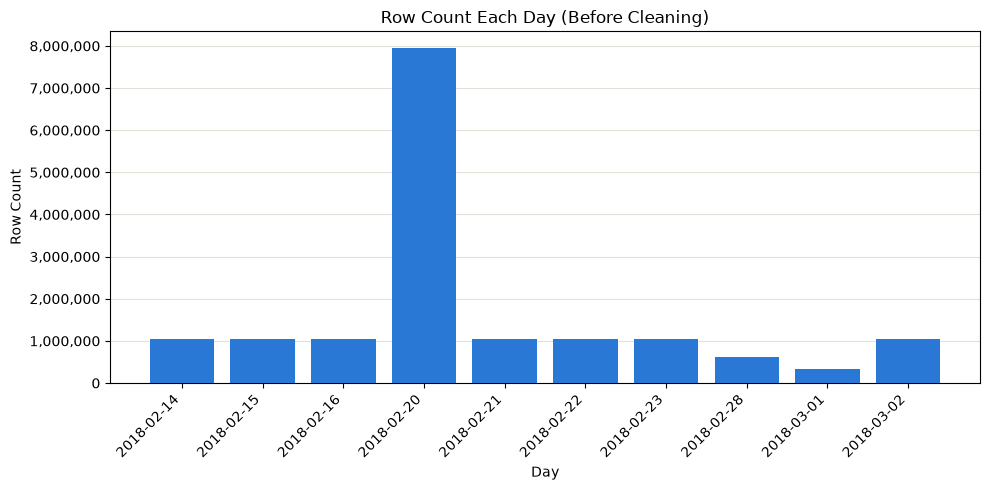

### Class Distribution (Before Cleaning)

Found 15 classes in 168 files                                                   ed ~00:00:00 left


['Benign',
 'Bot',
 'Brute Force -Web',
 'Brute Force -XSS',
 'DDOS attack-HOIC',
 'DDOS attack-LOIC-UDP',
 'DDoS attacks-LOIC-HTTP',
 'DoS attacks-GoldenEye',
 'DoS attacks-Hulk',
 'DoS attacks-SlowHTTPTest',
 'DoS attacks-Slowloris',
 'FTP-BruteForce',
 'Infilteration',
 'SQL Injection',
 'SSH-Bruteforce']

Counted classes in 168 files                                                    sed ~00:00:00 left


,day,Benign,Bot,Brute Force -Web,Brute Force -XSS,DDOS attack-HOIC,DDOS attack-LOIC-UDP,DDoS attacks-LOIC-HTTP,DoS attacks-GoldenEye,DoS attacks-Hulk,DoS attacks-SlowHTTPTest,DoS attacks-Slowloris,FTP-BruteForce,Infilteration,SQL Injection,SSH-Bruteforce
0,2018-02-14,667626,0,0,0,0,0,0,0,0,0,0,193360,0,0,187589
1,2018-02-15,996077,0,0,0,0,0,0,41508,0,0,10990,0,0,0,0
2,2018-02-16,446772,0,0,0,0,0,0,0,461912,139890,0,0,0,0,0
3,2018-02-20,7372557,0,0,0,0,0,576191,0,0,0,0,0,0,0,0
4,2018-02-21,360833,0,0,0,686012,1730,0,0,0,0,0,0,0,0,0
5,2018-02-22,1048213,0,249,79,0,0,0,0,0,0,0,0,0,34,0
6,2018-02-23,1048009,0,362,151,0,0,0,0,0,0,0,0,0,53,0
7,2018-02-28,544200,0,0,0,0,0,0,0,0,0,0,0,68871,0,0
8,2018-03-01,238037,0,0,0,0,0,0,0,0,0,0,0,93063,0,0
9,2018-03-02,762384,286191,0,0,0,0,0,0,0,0,0,0,0,0,0


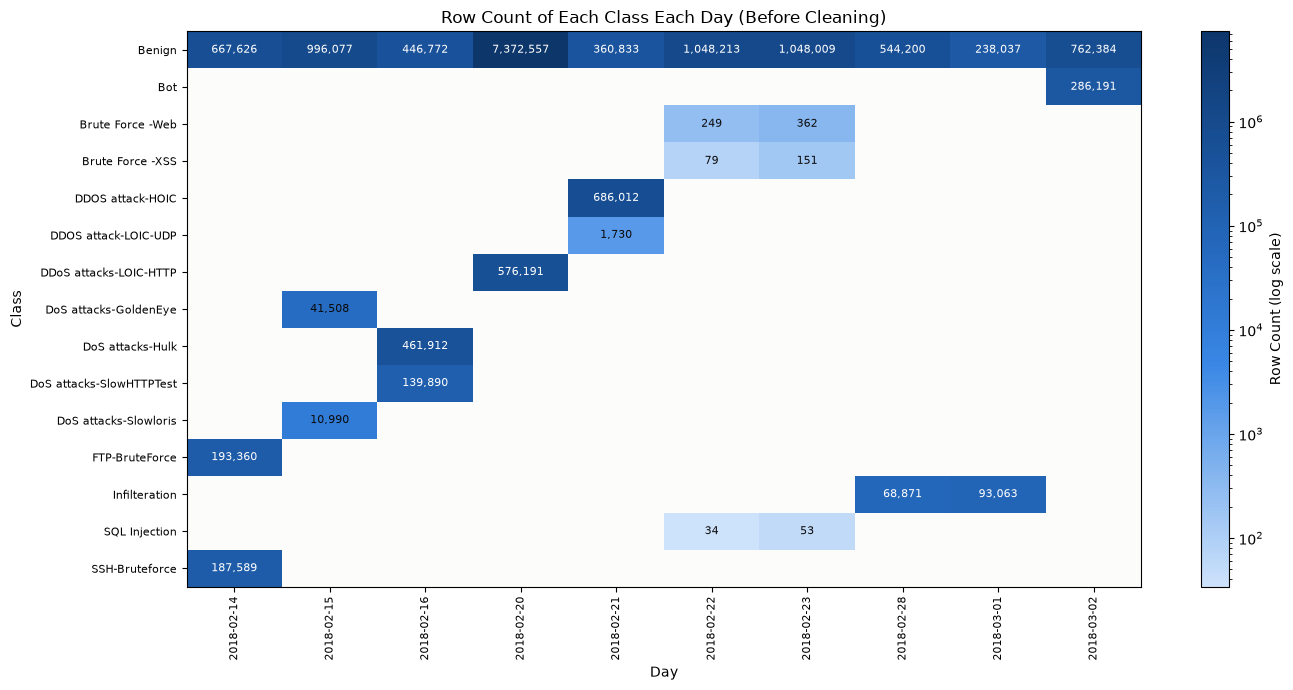

,class,rows,percentage
0,Benign,13484708,83.070014
1,DDOS attack-HOIC,686012,4.226048
2,DDoS attacks-LOIC-HTTP,576191,3.549517
3,DoS attacks-Hulk,461912,2.845522
4,Bot,286191,1.763026
5,FTP-BruteForce,193360,1.191158
6,SSH-Bruteforce,187589,1.155607
7,Infilteration,161934,0.997564
8,DoS attacks-SlowHTTPTest,139890,0.861766
9,DoS attacks-GoldenEye,41508,0.255702


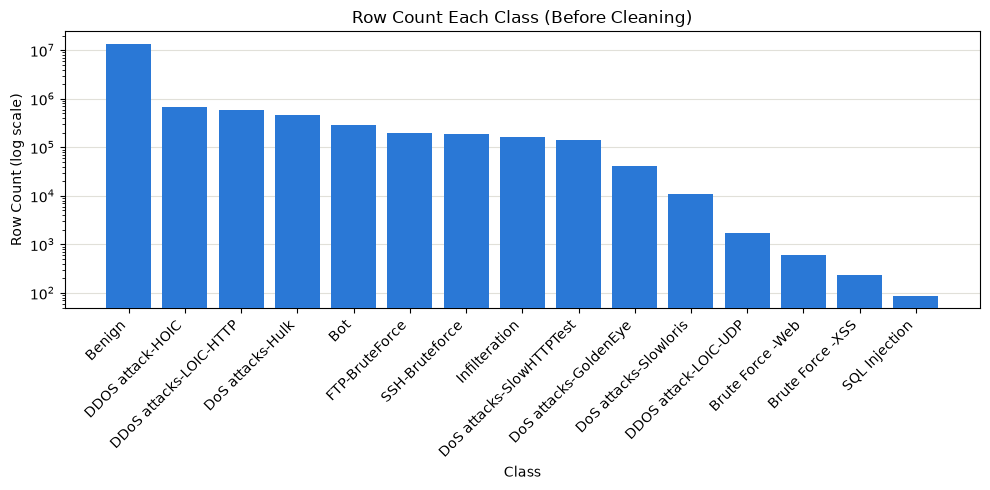

### Descriptive Statistics (Before Cleaning)

Described 78 features                                                           psed ~00:00:00 left


,feature,rows,missing,nan,infinite,min,max,mean,median,std,negative,zero,unique
0,ack_flag_cnt,16232943,0,0,0,0.000000e+00,1.000000e+00,3.316020e-01,0.000000,4.707888e-01,0,10850066,2
1,active_max,16232943,0,0,0,0.000000e+00,1.140000e+08,2.623920e+05,0.000000,3.319230e+06,0,14605586,905146
2,active_mean,16232943,0,0,0,0.000000e+00,1.140000e+08,1.728776e+05,0.000000,2.505927e+06,0,14605586,1192290
3,active_min,16232943,0,0,0,0.000000e+00,1.140000e+08,1.154657e+05,0.000000,2.114145e+06,0,14605586,427163
4,active_std,16232943,0,0,0,0.000000e+00,7.523242e+07,8.644097e+04,0.000000,1.514575e+06,0,15107385,1009594
5,bwd_blk_rate_avg,16232943,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0,16232943,1
6,bwd_byts_b_avg,16232943,0,0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0,16232943,1
7,bwd_header_len,16232943,0,0,0,0.000000e+00,2.462372e+06,1.330935e+02,16.000000,3.265496e+03,0,4148558,7366
8,bwd_iat_max,16232943,0,0,0,0.000000e+00,1.200000e+08,2.612947e+06,0.000000,1.024426e+07,0,9337704,1892963
9,bwd_iat_mean,16232943,0,0,0,0.000000e+00,1.200000e+08,8.241998e+05,0.000000,4.340497e+06,0,9337704,3875884


### Infinite Values (Before Cleaning)

,feature,infinite,percentage
0,flow_pkts_s,95760,0.589912
1,flow_byts_s,36039,0.222011


### Missing Values (Before Cleaning)

... (3 outputs left out)

### Constant Features (Before Cleaning)

,feature,min,unique
0,bwd_blk_rate_avg,0.0,1
1,bwd_byts_b_avg,0.0,1
2,bwd_pkts_b_avg,0.0,1
3,bwd_psh_flags,0.0,1
4,bwd_urg_flags,0.0,1
5,fwd_blk_rate_avg,0.0,1
6,fwd_byts_b_avg,0.0,1
7,fwd_pkts_b_avg,0.0,1


### Correlation Heatmaps (Before Cleaning)

Correlated 70 features in 168 files                                             03 elapsed ~00:00:00 left


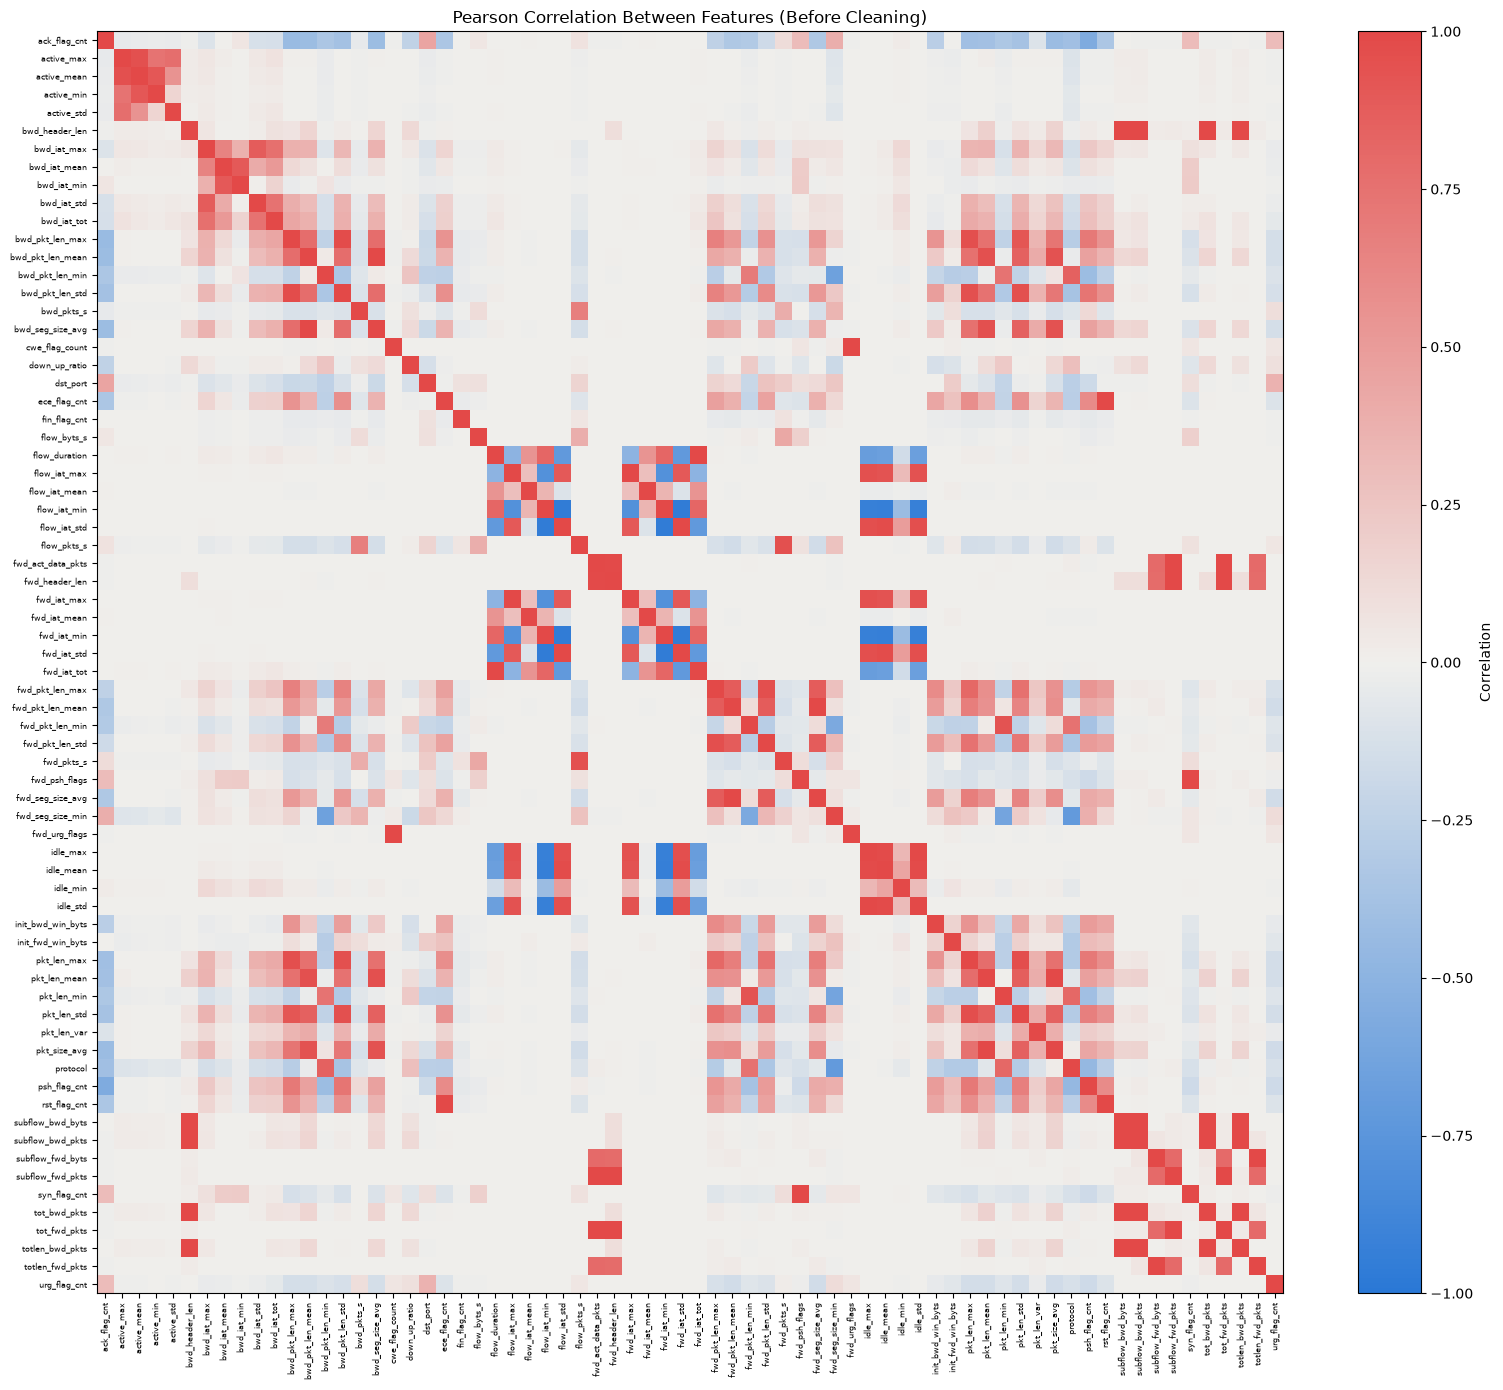

### Highly Correlated Features (Before Cleaning)

,feature,other_feature,correlation
0,subflow_bwd_pkts,tot_bwd_pkts,1.000000
1,fwd_psh_flags,syn_flag_cnt,1.000000
2,fwd_pkt_len_mean,fwd_seg_size_avg,1.000000
3,subflow_fwd_pkts,tot_fwd_pkts,1.000000
4,cwe_flag_count,fwd_urg_flags,1.000000
5,bwd_pkt_len_mean,bwd_seg_size_avg,1.000000
6,subflow_fwd_byts,totlen_fwd_pkts,1.000000
7,subflow_bwd_byts,totlen_bwd_pkts,1.000000
8,flow_iat_min,fwd_iat_min,0.999996
9,flow_iat_max,fwd_iat_max,0.999994


In [87]:
if RUN_EDA:
    eda_before_cleaning = run_eda(PATH_FOLDER_PARQUET_DATASET, BEFORE_CLEANING_STAGE)

# Data Cleaning

## Configurations

In [88]:
CONSTANT_FEATURES = [
    "bwd_blk_rate_avg",
    "bwd_byts_b_avg",
    "bwd_pkts_b_avg",
    "bwd_psh_flags",
    "bwd_urg_flags",
    "fwd_blk_rate_avg",
    "fwd_byts_b_avg",
    "fwd_pkts_b_avg",
]

NAN_REPLACEMENT = 0
INFINITY_OFFSET = 1  # an infinity becomes the column's finite maximum plus this

TIMESTAMP_FORMAT = "%d/%m/%Y %H:%M:%S"
UNIX_EPOCH = pd.Timestamp("1970-01-01")
DATE_COLUMN = "date"  # days since 1970-01-01
TIME_COLUMN = "time"  # seconds since midnight

WINDOW_BYTES_COLUMNS = ["init_fwd_win_byts", "init_bwd_win_byts"]
WINDOW_BYTES_FLAGGED_VALUE = -1
WINDOW_BYTES_FLAG_SUFFIX = "_is_minus_one"

ROWS_BEFORE_COLUMN = "rows_before"
ROWS_AFTER_COLUMN = "rows_after"
NAN_CELLS_COLUMN = "nan_cells_replaced"
INFINITE_CELLS_COLUMN = "infinite_cells_replaced"

# the settings of every stage before it too, so a rebuilt stage rebuilds the stages after it
CLEANING_SETTINGS = {
    **CONVERSION_SETTINGS,
    "constant_features": CONSTANT_FEATURES,
    "nan_replacement": NAN_REPLACEMENT,
    "infinity_offset": INFINITY_OFFSET,
    "timestamp_format": TIMESTAMP_FORMAT,
    "window_bytes_columns": WINDOW_BYTES_COLUMNS,
    "window_bytes_flagged_value": WINDOW_BYTES_FLAGGED_VALUE,
}

## Remove Constant Features

In [89]:
def remove_constant_features(
    dataframe: pd.DataFrame,
    constant_features: list[str] = CONSTANT_FEATURES,
) -> pd.DataFrame:
    return dataframe.drop(columns=constant_features)

## Convert Timestamp

In [90]:
def convert_timestamp(
    dataframe: pd.DataFrame,
    timestamp_column: str = TIMESTAMP_COLUMN,
    timestamp_format: str = TIMESTAMP_FORMAT,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    timestamps = pd.to_datetime(dataframe[timestamp_column], format=timestamp_format)
    dates = timestamps.dt.normalize()
    dataframe = dataframe.drop(columns=timestamp_column)
    dataframe[DATE_COLUMN] = (dates - UNIX_EPOCH).dt.days.astype(numeric_data_type)
    dataframe[TIME_COLUMN] = (timestamps - dates).dt.total_seconds().astype(numeric_data_type)
    return dataframe

## Flag Window Bytes

In [91]:
def get_flag_column(column: str, flag_suffix: str = WINDOW_BYTES_FLAG_SUFFIX) -> str:
    return f"{column}{flag_suffix}"

In [92]:
def flag_window_bytes(
    dataframe: pd.DataFrame,
    window_bytes_columns: list[str] = WINDOW_BYTES_COLUMNS,
    flagged_value: float = WINDOW_BYTES_FLAGGED_VALUE,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> pd.DataFrame:
    # the -1 values stay as they are, the flag lets a model tell them apart from a real window size
    dataframe = dataframe.copy()
    for column in window_bytes_columns:
        dataframe[get_flag_column(column)] = (dataframe[column] == flagged_value).astype(numeric_data_type)
    return dataframe

## Replace NaN Values

In [93]:
def replace_nan_values(dataframe: pd.DataFrame, nan_replacement: float = NAN_REPLACEMENT) -> pd.DataFrame:
    numeric_columns = dataframe.select_dtypes("number").columns
    dataframe = dataframe.copy()
    dataframe[numeric_columns] = dataframe[numeric_columns].fillna(nan_replacement)
    return dataframe

## Replace Infinite Values

In [94]:
# the maximum is taken over every file, so an infinity becomes the same value in all of them
def compute_infinity_replacements(
    folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    infinity_offset: float = INFINITY_OFFSET,
    numeric_data_type: str = NUMERIC_DATA_TYPE,
) -> dict[str, float]:
    dataset = pl.scan_parquet(os.path.join(folder_path, "*.parquet"))
    feature_columns = get_feature_columns(folder_path)
    has_infinity = dataset.select(pl.col(feature_columns).is_infinite().any()).collect().row(0, named=True)

    infinite_columns = []
    finite_maxima = []
    for column in feature_columns:
        if has_infinity[column]:
            infinite_columns.append(column)
            finite_maxima.append(pl.col(column).filter(pl.col(column).is_finite()).max())
    if not infinite_columns:
        return {}
    finite_maxima = dataset.select(finite_maxima).collect().row(0, named=True)

    replacements = {}
    for column in infinite_columns:
        maximum = np.dtype(numeric_data_type).type(finite_maxima[column])
        # past 2**24 a float32 rounds the maximum plus 1 back to the maximum, so the next float32 up stands in for it
        replacements[column] = float(max(maximum + infinity_offset, np.nextafter(maximum, np.inf)))
    return replacements

In [95]:
def replace_infinite_values(dataframe: pd.DataFrame, infinity_replacements: dict[str, float]) -> pd.DataFrame:
    dataframe = dataframe.copy()
    for column, replacement in infinity_replacements.items():
        dataframe[column] = dataframe[column].replace([np.inf, -np.inf], replacement)
    return dataframe

## Clean A Single File

In [96]:
def clean_a_single_file(
    file_path: str,
    infinity_replacements: dict[str, float],
    output_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    constant_features: list[str] = CONSTANT_FEATURES,
    window_bytes_columns: list[str] = WINDOW_BYTES_COLUMNS,
    file_column: str = FILE_COLUMN,
) -> dict:
    dataframe = pd.read_parquet(file_path)

    dataframe = remove_constant_features(dataframe, constant_features)
    dataframe = convert_timestamp(dataframe)
    dataframe = flag_window_bytes(dataframe, window_bytes_columns)
    numeric_values = dataframe.select_dtypes("number").to_numpy()
    nan_cell_count = int(np.isnan(numeric_values).sum())
    infinite_cell_count = int(np.isinf(numeric_values).sum())
    dataframe = replace_nan_values(dataframe)
    dataframe = replace_infinite_values(dataframe, infinity_replacements)

    file_name = os.path.basename(file_path)
    os.makedirs(output_folder_path, exist_ok=True)
    dataframe.to_parquet(os.path.join(output_folder_path, file_name), index=False)

    record = {
        file_column: file_name,
        ROW_COUNT_COLUMN: len(dataframe),
        NAN_CELLS_COLUMN: nan_cell_count,
        INFINITE_CELLS_COLUMN: infinite_cell_count,
    }
    for column in window_bytes_columns:
        flag_column = get_flag_column(column)
        record[flag_column] = int(dataframe[flag_column].sum())
    return record

## Clean All Files

In [97]:
def clean_all_files(
    input_folder_path: str = PATH_FOLDER_PARQUET_DATASET,
    output_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    n_jobs: int = CLEANING_N_JOBS,
) -> pd.DataFrame:
    print_status("Finding the finite maximum of the columns with infinite values")
    infinity_replacements = compute_infinity_replacements(input_folder_path)
    for column, replacement in infinity_replacements.items():
        end_status(f"{column}: infinity -> {replacement:,} (the finite maximum plus {INFINITY_OFFSET})")

    file_paths = get_file_paths_in_folder(input_folder_path, "parquet")
    tasks = create_tasks_list(clean_a_single_file, file_paths, infinity_replacements, output_folder_path)

    records = run_tasks_in_parallel(tasks, n_jobs, "Cleaning files")
    summary = pd.DataFrame(records)

    end_status(
        f"Cleaned {len(tasks)} files of {summary[ROW_COUNT_COLUMN].sum():,} rows: "
        f"{summary[NAN_CELLS_COLUMN].sum():,} NaN cells and {summary[INFINITE_CELLS_COLUMN].sum():,} infinite cells replaced"
    )
    return summary

## Implementation

In [98]:
summary = run_stage(PATH_FOLDER_CLEANED_DATASET, CLEANING_SETTINGS, clean_all_files)
if summary is not None:
    display(group_and_sum(summary, FILE_COLUMN, DAY_COLUMN, DAY_REGEX))
del summary

flow_byts_s: infinity -> 1,806,642,944.0 (the finite maximum plus 1)            
flow_pkts_s: infinity -> 6,000,001.0 (the finite maximum plus 1)                
Cleaned 168 files of 16,232,943 rows: 59,721 NaN cells and 131,799 infinite cells replaced0 left


,day,rows,nan_cells_replaced,infinite_cells_replaced,init_fwd_win_byts_is_minus_one,init_bwd_win_byts_is_minus_one
0,2018-02-14,1048575,2277,5371,219266,347370
1,2018-02-15,1048575,4921,11133,364089,587584
2,2018-02-16,1048574,0,0,177,438345
3,2018-02-20,7948748,36767,82139,2653104,4209795
4,2018-02-21,1048575,0,0,3712,525993
5,2018-02-22,1048575,3569,7651,322153,577969
6,2018-02-23,1048575,3754,7662,308468,573165
7,2018-02-28,613071,4041,8297,227355,321490
8,2018-03-01,331100,1834,4004,118201,159458
9,2018-03-02,1048575,2558,5542,216083,514380


# Before and After Cleaning

## Configurations

In [99]:
BEFORE_COLUMN = "before"
AFTER_COLUMN = "after"
DIFFERENCE_COLUMN = "difference"
CHANGE_COLUMN = "change"

COMPARED_STATISTICS = [
    MISSING_COUNT_COLUMN,
    NAN_COUNT_COLUMN,
    INFINITE_COUNT_COLUMN,
    "min",
    "max",
    "mean",
    "median",
    "std",
    "negative",
    "zero",
    UNIQUE_COUNT_COLUMN,
]

## Compare Counts

In [100]:
def compare_counts(
    before: pd.DataFrame,
    after: pd.DataFrame,
    key_column: str,
    value_column: str = ROW_COUNT_COLUMN,
) -> pd.DataFrame:
    before = before.set_index(key_column)[value_column]
    after = after.set_index(key_column)[value_column]
    keys = before.index.union(after.index, sort=False)
    comparison = pd.DataFrame({BEFORE_COLUMN: before.reindex(keys), AFTER_COLUMN: after.reindex(keys)}, index=keys)
    comparison[DIFFERENCE_COLUMN] = comparison[AFTER_COLUMN] - comparison[BEFORE_COLUMN]
    return comparison.rename_axis(key_column).reset_index()

## Compare Feature Statistics

In [101]:
def compare_feature_statistics(
    before: pd.DataFrame,
    after: pd.DataFrame,
    statistics: list[str] = COMPARED_STATISTICS,
    feature_column: str = FEATURE_COLUMN,
) -> pd.DataFrame:
    before = before.set_index(feature_column)[statistics].astype(float)
    after = after.set_index(feature_column)[statistics].astype(float)
    features = before.index.union(after.index, sort=False)
    is_removed = ~features.isin(after.index)
    is_added = ~features.isin(before.index)
    before = before.reindex(features)
    after = after.reindex(features)
    # the same values can sum up in another order, so a statistic only counts as changed past the last bits
    is_same = np.isclose(before, after, rtol=1e-9, atol=0, equal_nan=True).all(axis=1)
    changes = np.select([is_removed, is_added, is_same], ["removed", "added", "unchanged"], "changed")

    comparison = pd.concat({BEFORE_COLUMN: before, AFTER_COLUMN: after}, axis=1).swaplevel(axis=1)[statistics]
    comparison.insert(0, (CHANGE_COLUMN, ""), changes)
    return comparison.rename_axis(feature_column)

## Compare Correlations

In [102]:
def compare_correlations(before: pd.DataFrame, after: pd.DataFrame) -> pd.DataFrame:
    features = []
    for feature in after.columns:
        if feature in before.columns:
            features.append(feature)
    return after.loc[features, features] - before.loc[features, features]

## Implementation

### After Cleaning

### Row Count Each Day (After Cleaning)

Counted the rows of 168 files                                                    ~00:00:00 left


,day,rows
0,2018-02-14,1048575
1,2018-02-15,1048575
2,2018-02-16,1048574
3,2018-02-20,7948748
4,2018-02-21,1048575
5,2018-02-22,1048575
6,2018-02-23,1048575
7,2018-02-28,613071
8,2018-03-01,331100
9,2018-03-02,1048575


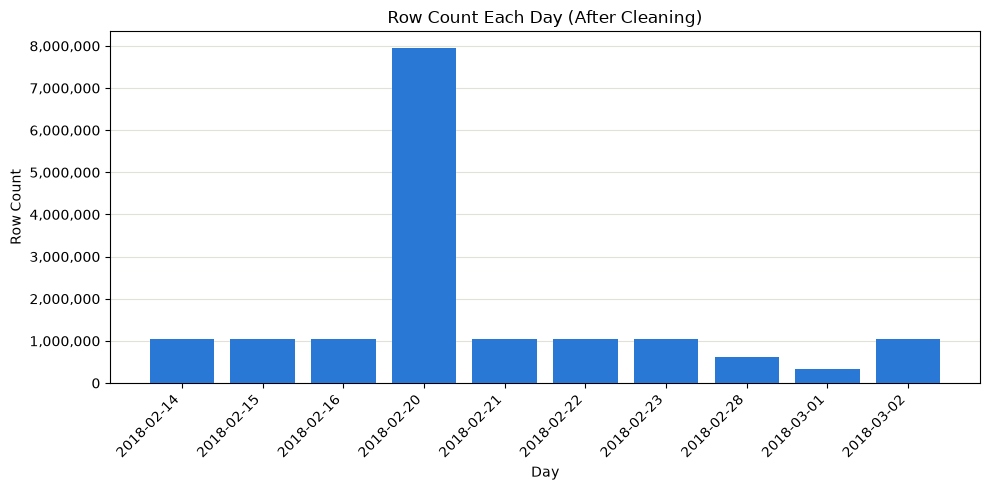

### Class Distribution (After Cleaning)

Found 15 classes in 168 files                                                   ed ~00:00:00 left


['Benign',
 'Bot',
 'Brute Force -Web',
 'Brute Force -XSS',
 'DDOS attack-HOIC',
 'DDOS attack-LOIC-UDP',
 'DDoS attacks-LOIC-HTTP',
 'DoS attacks-GoldenEye',
 'DoS attacks-Hulk',
 'DoS attacks-SlowHTTPTest',
 'DoS attacks-Slowloris',
 'FTP-BruteForce',
 'Infilteration',
 'SQL Injection',
 'SSH-Bruteforce']

Counted classes in 168 files                                                    sed ~00:00:00 left


,day,Benign,Bot,Brute Force -Web,Brute Force -XSS,DDOS attack-HOIC,DDOS attack-LOIC-UDP,DDoS attacks-LOIC-HTTP,DoS attacks-GoldenEye,DoS attacks-Hulk,DoS attacks-SlowHTTPTest,DoS attacks-Slowloris,FTP-BruteForce,Infilteration,SQL Injection,SSH-Bruteforce
0,2018-02-14,667626,0,0,0,0,0,0,0,0,0,0,193360,0,0,187589
1,2018-02-15,996077,0,0,0,0,0,0,41508,0,0,10990,0,0,0,0
2,2018-02-16,446772,0,0,0,0,0,0,0,461912,139890,0,0,0,0,0
3,2018-02-20,7372557,0,0,0,0,0,576191,0,0,0,0,0,0,0,0
4,2018-02-21,360833,0,0,0,686012,1730,0,0,0,0,0,0,0,0,0
5,2018-02-22,1048213,0,249,79,0,0,0,0,0,0,0,0,0,34,0
6,2018-02-23,1048009,0,362,151,0,0,0,0,0,0,0,0,0,53,0
7,2018-02-28,544200,0,0,0,0,0,0,0,0,0,0,0,68871,0,0
8,2018-03-01,238037,0,0,0,0,0,0,0,0,0,0,0,93063,0,0
9,2018-03-02,762384,286191,0,0,0,0,0,0,0,0,0,0,0,0,0


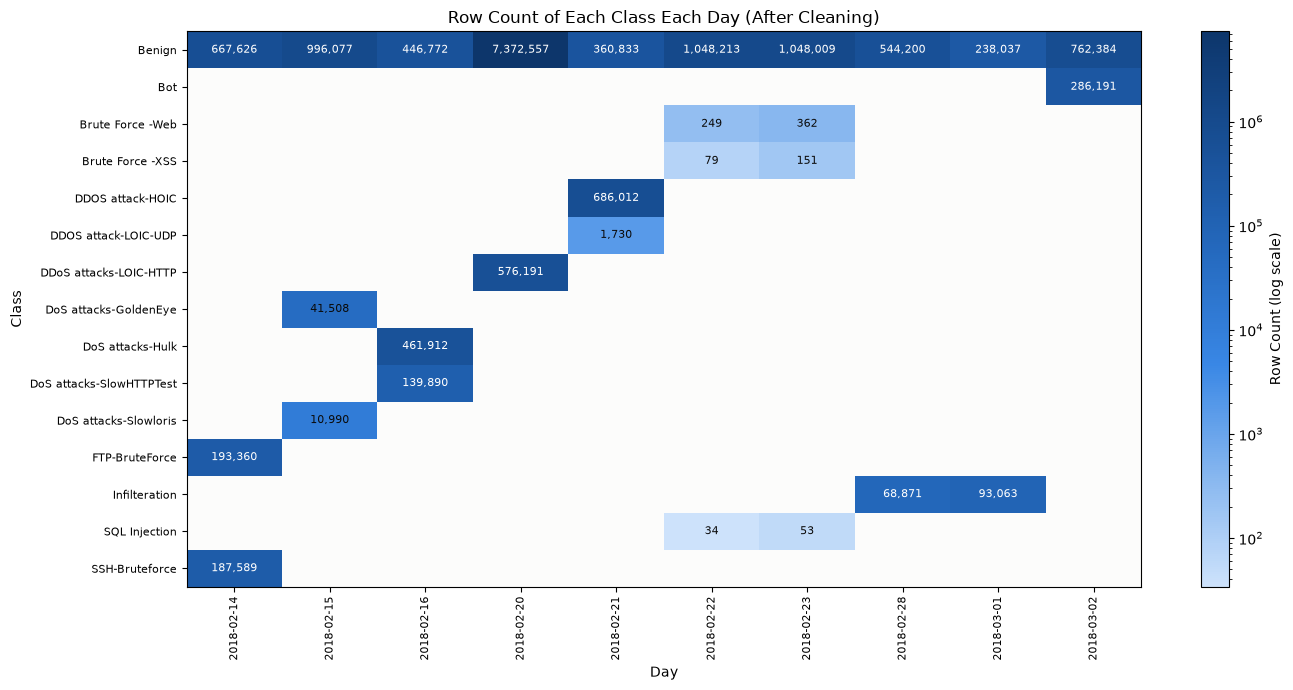

,class,rows,percentage
0,Benign,13484708,83.070014
1,DDOS attack-HOIC,686012,4.226048
2,DDoS attacks-LOIC-HTTP,576191,3.549517
3,DoS attacks-Hulk,461912,2.845522
4,Bot,286191,1.763026
5,FTP-BruteForce,193360,1.191158
6,SSH-Bruteforce,187589,1.155607
7,Infilteration,161934,0.997564
8,DoS attacks-SlowHTTPTest,139890,0.861766
9,DoS attacks-GoldenEye,41508,0.255702


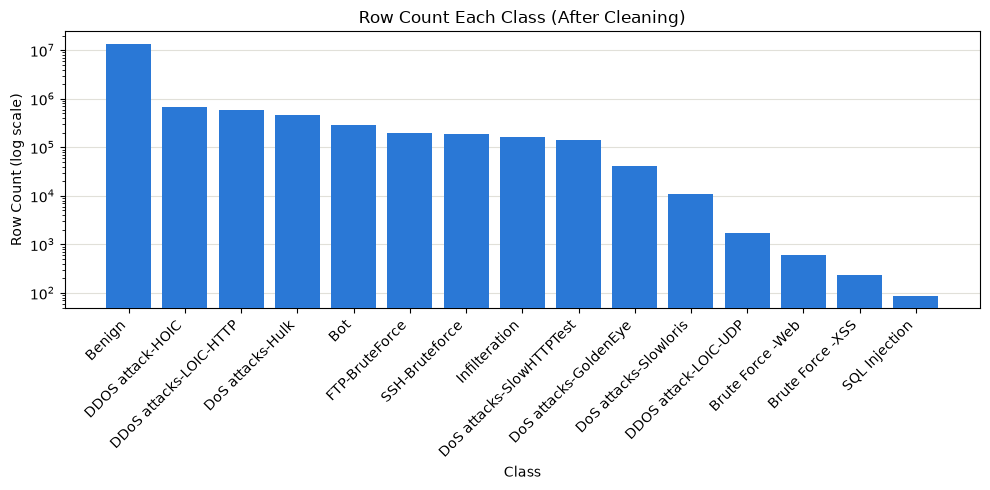

### Descriptive Statistics (After Cleaning)

Described 74 features                                                           psed ~00:00:00 left


,feature,rows,missing,nan,infinite,min,max,mean,median,std,negative,zero,unique
0,ack_flag_cnt,16232943,0,0,0,0.000000e+00,1.000000e+00,3.316020e-01,0.000000,4.707888e-01,0,10850066,2
1,active_max,16232943,0,0,0,0.000000e+00,1.140000e+08,2.623920e+05,0.000000,3.319230e+06,0,14605586,905146
2,active_mean,16232943,0,0,0,0.000000e+00,1.140000e+08,1.728776e+05,0.000000,2.505927e+06,0,14605586,1192290
3,active_min,16232943,0,0,0,0.000000e+00,1.140000e+08,1.154657e+05,0.000000,2.114145e+06,0,14605586,427163
4,active_std,16232943,0,0,0,0.000000e+00,7.523242e+07,8.644097e+04,0.000000,1.514575e+06,0,15107385,1009594
5,bwd_header_len,16232943,0,0,0,0.000000e+00,2.462372e+06,1.330935e+02,16.000000,3.265496e+03,0,4148558,7366
6,bwd_iat_max,16232943,0,0,0,0.000000e+00,1.200000e+08,2.612947e+06,0.000000,1.024426e+07,0,9337704,1892963
7,bwd_iat_mean,16232943,0,0,0,0.000000e+00,1.200000e+08,8.241998e+05,0.000000,4.340497e+06,0,9337704,3875884
8,bwd_iat_min,16232943,0,0,0,0.000000e+00,1.200000e+08,2.912304e+05,0.000000,3.825444e+06,0,9950687,465420
9,bwd_iat_std,16232943,0,0,0,0.000000e+00,8.483719e+07,8.511741e+05,0.000000,3.376930e+06,0,10484384,4622781


### Infinite Values (After Cleaning)

,feature,infinite,percentage


### Missing Values (After Cleaning)

... (3 outputs left out)

### Constant Features (After Cleaning)

,feature,min,unique


### Correlation Heatmaps (After Cleaning)

Correlated 74 features in 168 files                                             02 elapsed ~00:00:00 left


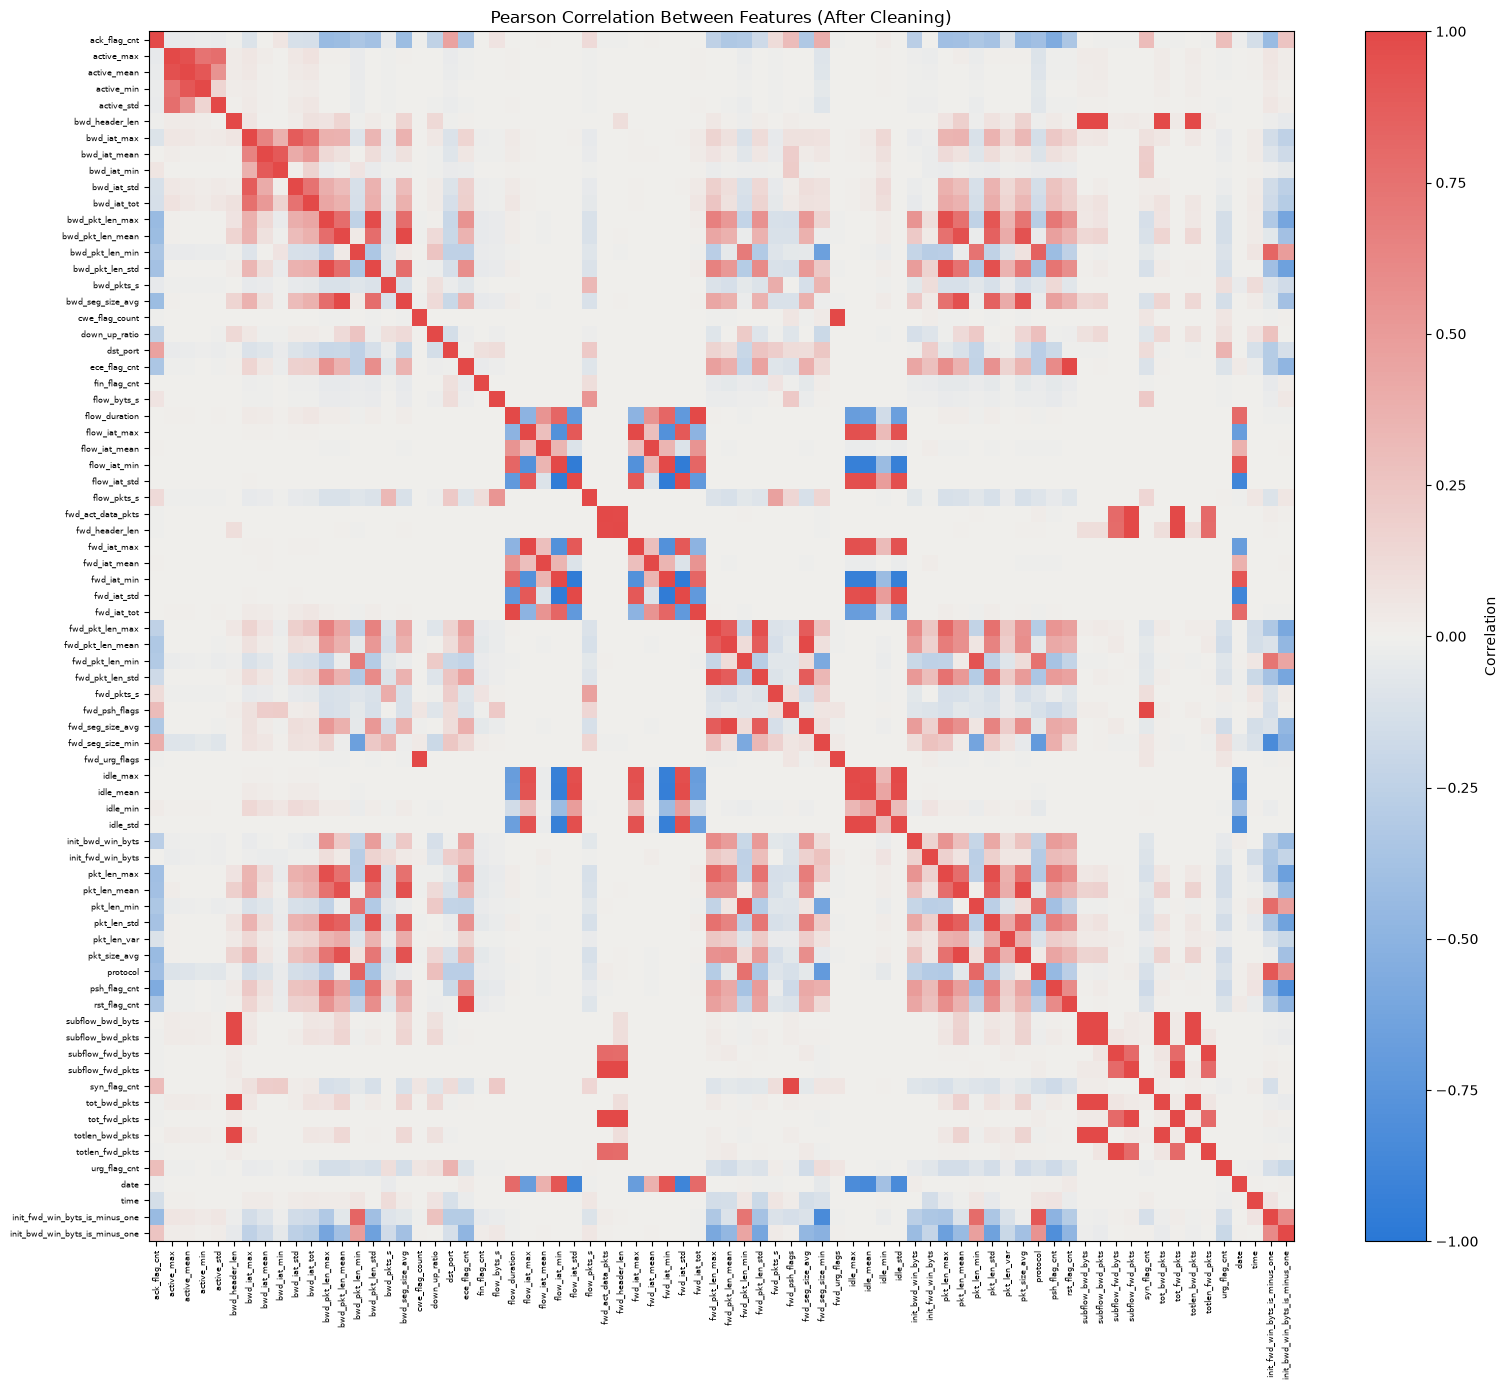

### Highly Correlated Features (After Cleaning)

,feature,other_feature,correlation
0,cwe_flag_count,fwd_urg_flags,1.000000
1,subflow_fwd_pkts,tot_fwd_pkts,1.000000
2,fwd_pkt_len_mean,fwd_seg_size_avg,1.000000
3,fwd_psh_flags,syn_flag_cnt,1.000000
4,subflow_fwd_byts,totlen_fwd_pkts,1.000000
5,bwd_pkt_len_mean,bwd_seg_size_avg,1.000000
6,subflow_bwd_pkts,tot_bwd_pkts,1.000000
7,subflow_bwd_byts,totlen_bwd_pkts,1.000000
8,flow_iat_min,fwd_iat_min,0.999996
9,flow_iat_max,fwd_iat_max,0.999994


In [103]:
if RUN_EDA:
    eda_after_cleaning = run_eda(PATH_FOLDER_CLEANED_DATASET, AFTER_CLEANING_STAGE)

### Row Count Each Day

In [104]:
if RUN_EDA:
    display(compare_counts(eda_before_cleaning[ROWS_PER_DAY_KEY], eda_after_cleaning[ROWS_PER_DAY_KEY], DAY_COLUMN))

,day,before,after,difference
0,2018-02-14,1048575,1048575,0
1,2018-02-15,1048575,1048575,0
2,2018-02-16,1048574,1048574,0
3,2018-02-20,7948748,7948748,0
4,2018-02-21,1048575,1048575,0
5,2018-02-22,1048575,1048575,0
6,2018-02-23,1048575,1048575,0
7,2018-02-28,613071,613071,0
8,2018-03-01,331100,331100,0
9,2018-03-02,1048575,1048575,0


### Class Distribution

In [105]:
if RUN_EDA:
    display(compare_counts(eda_before_cleaning[CLASS_TOTALS_KEY], eda_after_cleaning[CLASS_TOTALS_KEY], CLASS_COLUMN))

,class,before,after,difference
0,Benign,13484708,13484708,0
1,DDOS attack-HOIC,686012,686012,0
2,DDoS attacks-LOIC-HTTP,576191,576191,0
3,DoS attacks-Hulk,461912,461912,0
4,Bot,286191,286191,0
5,FTP-BruteForce,193360,193360,0
6,SSH-Bruteforce,187589,187589,0
7,Infilteration,161934,161934,0
8,DoS attacks-SlowHTTPTest,139890,139890,0
9,DoS attacks-GoldenEye,41508,41508,0


### Feature Statistics

In [106]:
if RUN_EDA:
    results = compare_feature_statistics(
        eda_before_cleaning[DESCRIPTIVE_STATISTICS_KEY],
        eda_after_cleaning[DESCRIPTIVE_STATISTICS_KEY],
    )
    is_unchanged = results[CHANGE_COLUMN] == "unchanged"
    end_status(f"The cleaning leaves {is_unchanged.sum()} of {len(results)} features unchanged, the others are:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(results[~is_unchanged])
    del results, is_unchanged

The cleaning leaves 68 of 82 features unchanged, the others are:                


change  missing          nan       infinite  \
                                          before after before after   before   
feature                                                                        
bwd_blk_rate_avg                removed      0.0   NaN    0.0   NaN      0.0   
bwd_byts_b_avg                  removed      0.0   NaN    0.0   NaN      0.0   
bwd_pkts_b_avg                  removed      0.0   NaN    0.0   NaN      0.0   
bwd_psh_flags                   removed      0.0   NaN    0.0   NaN      0.0   
bwd_urg_flags                   removed      0.0   NaN    0.0   NaN      0.0   
flow_byts_s                     changed  59721.0   0.0    0.0   0.0  36039.0   
flow_pkts_s                     changed      0.0   0.0    0.0   0.0  95760.0   
fwd_blk_rate_avg                removed      0.0   NaN    0.0   NaN      0.0   
fwd_byts_b_avg                  removed      0.0   NaN    0.0   NaN      0.0   
fwd_pkts_b_avg                  removed      0.0   NaN    0.0   NaN      0.0   
date                              added      NaN   0.0    NaN   0.0      NaN   
time                              added      NaN   0.0    NaN   0.0      NaN   
init_fwd_win_byts_is_minus_one    added      NaN   0.0    NaN   0.0      NaN   
init_bwd_win_byts_is_minus_one    added      NaN   0.0    NaN   0.0      NaN   

                                           min                        max  \
                               after    before        after        before   
feature                                                                     
bwd_blk_rate_avg                 NaN  0.000000          NaN  0.000000e+00   
bwd_byts_b_avg                   NaN  0.000000          NaN  0.000000e+00   
bwd_pkts_b_avg                   NaN  0.000000          NaN  0.000000e+00   
bwd_psh_flags                    NaN  0.000000          NaN  0.000000e+00   
bwd_urg_flags                    NaN  0.000000          NaN  0.000000e+00   
flow_byts_s                      0.0  0.000000     0.000000  1.806643e+09   
flow_pkts_s                      0.0 -0.008895    -0.008895  6.000000e+06   
fwd_blk_rate_avg                 NaN  0.000000          NaN  0.000000e+00   
fwd_byts_b_avg                   NaN  0.000000          NaN  0.000000e+00   
fwd_pkts_b_avg                   NaN  0.000000          NaN  0.000000e+00   
date                             0.0       NaN     4.000000           NaN   
time                             0.0       NaN  3600.000000           NaN   
init_fwd_win_byts_is_minus_one   0.0       NaN     0.000000           NaN   
init_bwd_win_byts_is_minus_one   0.0       NaN     0.000000           NaN   

                                                       mean                \
                                       after         before         after   
feature                                                                     
bwd_blk_rate_avg                         NaN       0.000000           NaN   
bwd_byts_b_avg                           NaN       0.000000           NaN   
bwd_pkts_b_avg                           NaN       0.000000           NaN   
bwd_psh_flags                            NaN       0.000000           NaN   
bwd_urg_flags                            NaN       0.000000           NaN   
flow_byts_s                     1.806643e+09  257034.893053  4.266474e+06   
flow_pkts_s                     6.000001e+06   52296.982258  8.738317e+04   
fwd_blk_rate_avg                         NaN       0.000000           NaN   
fwd_byts_b_avg                           NaN       0.000000           NaN   
fwd_pkts_b_avg                           NaN       0.000000           NaN   
date                            1.759200e+04            NaN  1.758254e+04   
time                            4.679900e+04            NaN  2.442691e+04   
init_fwd_win_byts_is_minus_one  1.000000e+00            NaN  2.730625e-01   
init_bwd_win_byts_is_minus_one  1.000000e+00            NaN  5.085676e-01   

                                    median          

### Correlation Change

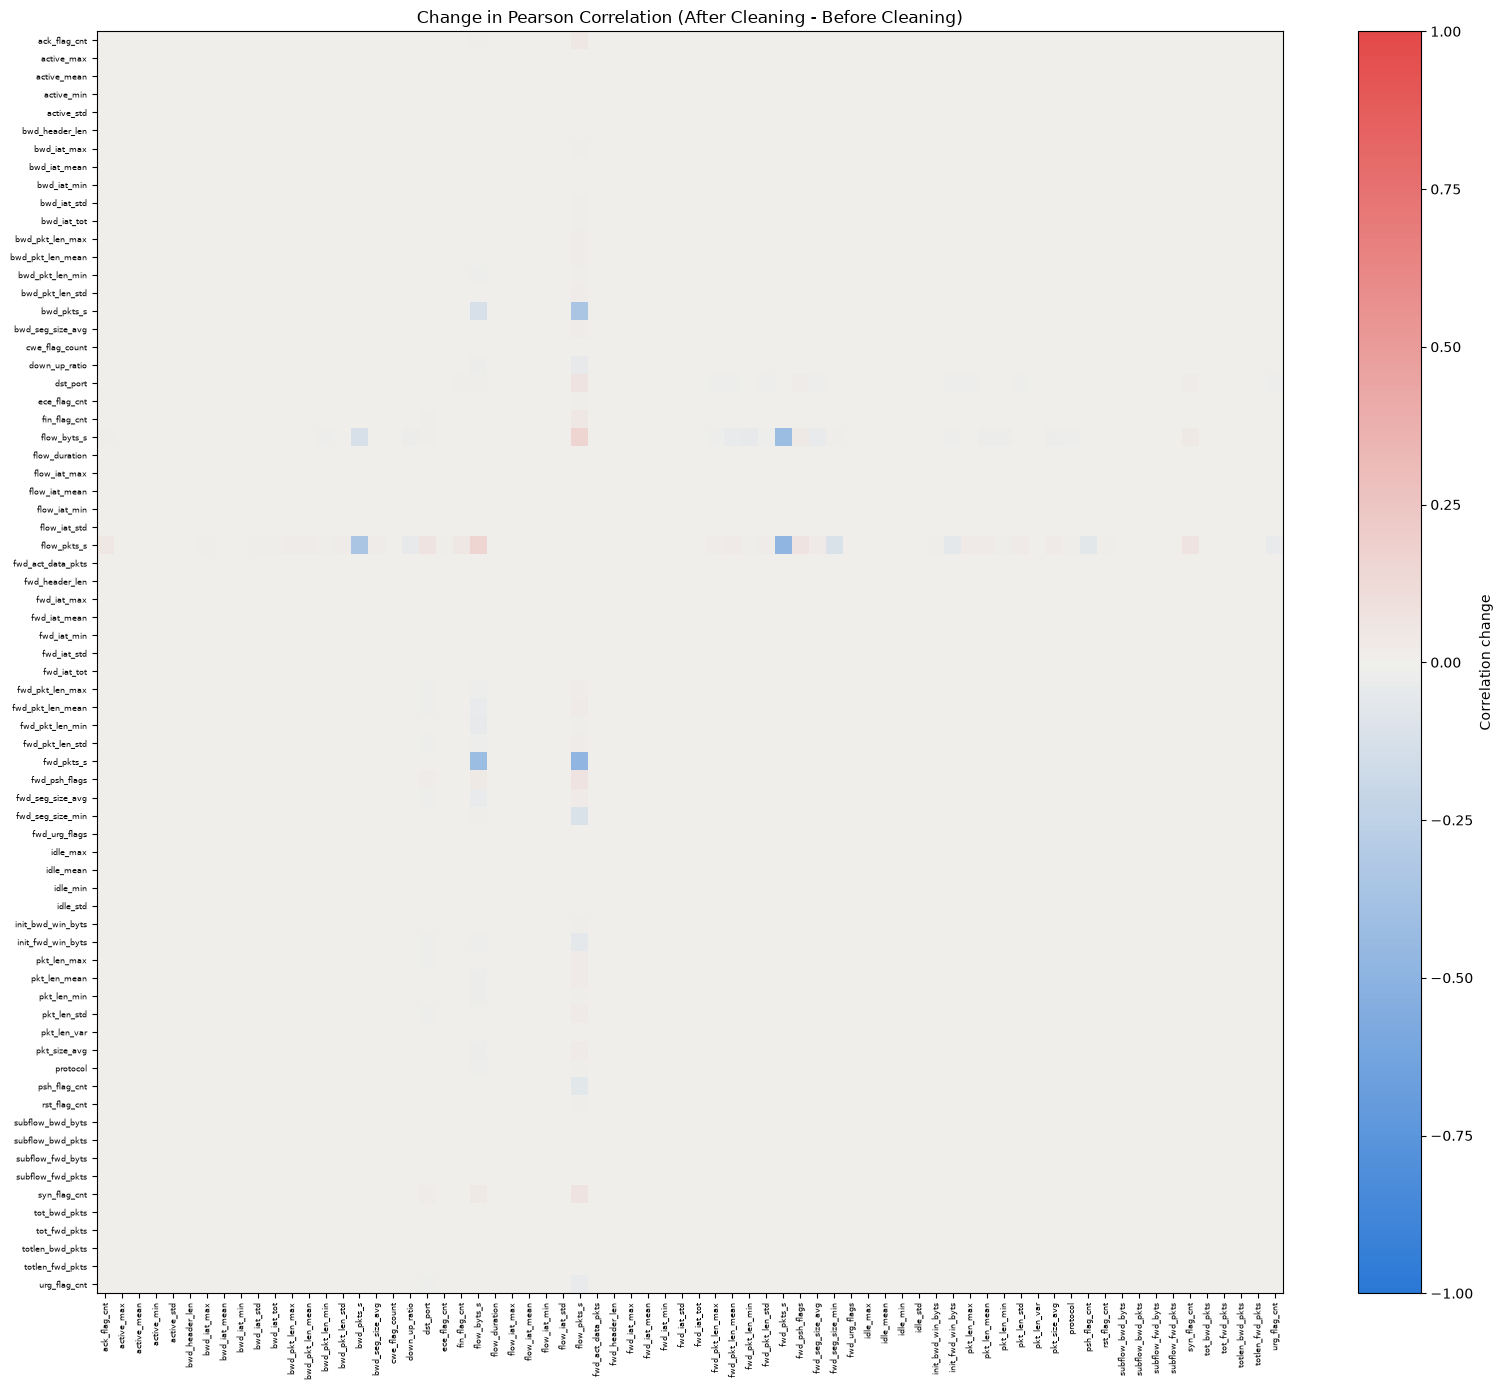

In [107]:
if RUN_EDA:
    plot_heatmap(
        compare_correlations(eda_before_cleaning[CORRELATION_KEY], eda_after_cleaning[CORRELATION_KEY]),
        "Change in Pearson Correlation (After Cleaning - Before Cleaning)",
        colormap=DIVERGING_COLORMAP,
        value_range=(-1, 1),
        colorbar_label="Correlation change",
        figsize=(16, 14),
        font_size=6,
    )
    del eda_before_cleaning, eda_after_cleaning

# Remove Duplicate Values

## Configurations

In [108]:
DUPLICATE_ROWS_COLUMN = "duplicate_rows_removed"

# seeds of the row hash that finds the duplicates, not of a shuffle, so they stay the same whatever RANDOM_STATE is
ROW_HASH_SEEDS = (0, 1)

# every attack ran in its own time window, so the date and time would name the attack without looking at the traffic,
# and the same flow a second later would count as a new row; they stay out of the duplicates check and of the models
TIME_COLUMNS = [DATE_COLUMN, TIME_COLUMN]

DEDUPLICATION_SETTINGS = {
    **CLEANING_SETTINGS,
    "class_mapping": CLASS_MAPPING,
    "row_hash_seeds": list(ROW_HASH_SEEDS),
    "dropped_columns": TIME_COLUMNS,
}

## Apply Class Scheme

In [109]:
# the classes are mapped before the duplicates are found, so rows that only differ in a merged class are duplicates
def apply_class_scheme(
    dataframe: pl.DataFrame,
    class_mapping: dict[str, str] | None = CLASS_MAPPING,
    label_column: str = LABEL_COLUMN,
) -> pl.DataFrame:
    if class_mapping is None:
        return dataframe
    unknown_labels = set(dataframe[label_column].unique().to_list()) - set(class_mapping)
    if unknown_labels:
        raise ValueError(f"The {CLASS_SCHEME} class scheme has no class for {sorted(unknown_labels)}")
    return dataframe.with_columns(pl.col(label_column).replace_strict(class_mapping))

In [110]:
# the hashes and the written rows come from the same columns, so a row offset points at the same row in both
def load_rows_to_deduplicate(file_path: str, dropped_columns: list[str] = TIME_COLUMNS) -> pl.DataFrame:
    return apply_class_scheme(pl.read_parquet(file_path)).drop(dropped_columns)

## Hash Rows

In [111]:
def hash_rows_in_a_single_file(
    file_path: str,
    hash_seeds: tuple[int, ...] = ROW_HASH_SEEDS,
) -> np.ndarray:
    row = pl.struct(pl.all())
    hash_columns = []
    for hash_seed in hash_seeds:
        hash_columns.append(row.hash(hash_seed).alias(f"hash_{hash_seed}"))
    return load_rows_to_deduplicate(file_path).select(hash_columns).to_numpy()

In [112]:
def hash_rows_in_all_files(
    file_paths: list[str],
    n_jobs: int = DEDUPLICATION_N_JOBS,
) -> list[np.ndarray]:
    tasks = create_tasks_list(hash_rows_in_a_single_file, file_paths)
    return run_tasks_in_parallel(tasks, n_jobs, "Hashing rows")

## Find Duplicate Rows

In [113]:
def find_duplicate_rows(row_hashes: list[np.ndarray]) -> np.ndarray:
    hashes = pd.DataFrame(np.concatenate(row_hashes))
    return hashes.duplicated(keep="first").to_numpy()

In [114]:
def get_row_offsets(file_paths: list[str], per_file_rows: list[np.ndarray]) -> dict[str, int]:
    row_offsets = {}
    row_offset = 0
    for file_path, file_rows in zip(file_paths, per_file_rows):
        row_offsets[os.path.basename(file_path)] = row_offset
        row_offset += len(file_rows)
    return row_offsets

## Remove Duplicates In A Single File

In [115]:
def remove_duplicate_rows_in_a_single_file(
    file_path: str,
    is_duplicate: np.ndarray,
    row_offsets: dict[str, int],
    output_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    file_column: str = FILE_COLUMN,
) -> dict:
    file_name = os.path.basename(file_path)
    dataframe = load_rows_to_deduplicate(file_path).to_pandas()
    row_count_before = len(dataframe)

    row_offset = row_offsets[file_name]
    is_duplicate_in_file = is_duplicate[row_offset:row_offset + row_count_before]
    dataframe = dataframe[~is_duplicate_in_file]
    row_count_after = len(dataframe)

    os.makedirs(output_folder_path, exist_ok=True)
    dataframe.to_parquet(os.path.join(output_folder_path, file_name), index=False)

    return {
        file_column: file_name,
        ROWS_BEFORE_COLUMN: row_count_before,
        DUPLICATE_ROWS_COLUMN: row_count_before - row_count_after,
        ROWS_AFTER_COLUMN: row_count_after,
    }

## Remove Duplicates In All Files

In [116]:
def remove_duplicate_rows_in_all_files(
    input_folder_path: str = PATH_FOLDER_CLEANED_DATASET,
    output_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    n_jobs: int = DEDUPLICATION_N_JOBS,
) -> pd.DataFrame:
    file_paths = get_file_paths_in_folder(input_folder_path, "parquet")

    row_hashes = hash_rows_in_all_files(file_paths, n_jobs)
    print_status("Finding duplicate rows")
    is_duplicate = find_duplicate_rows(row_hashes)
    row_offsets = get_row_offsets(file_paths, row_hashes)
    del row_hashes

    tasks = create_tasks_list(
        remove_duplicate_rows_in_a_single_file,
        file_paths,
        is_duplicate,
        row_offsets,
        output_folder_path,
    )
    records = run_tasks_in_parallel(tasks, n_jobs, f"Removing {is_duplicate.sum():,} duplicate rows")
    summary = pd.DataFrame(records)

    rows_before = summary[ROWS_BEFORE_COLUMN].sum()
    rows_after = summary[ROWS_AFTER_COLUMN].sum()
    end_status(f"Removed duplicates from {len(tasks)} files: {rows_before:,} rows -> {rows_after:,} rows")
    return summary

## Implementation

### Deduplication

In [117]:
summary = run_stage(PATH_FOLDER_DEDUPLICATED_DATASET, DEDUPLICATION_SETTINGS, remove_duplicate_rows_in_all_files)
if summary is not None:
    display(group_and_sum(summary, FILE_COLUMN, DAY_COLUMN, DAY_REGEX))
del summary

Hashing rows |█-----------------------------| 8/168 (5%) | 00:00:00 elapsed, ~00:00:19 left

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Removed duplicates from 168 files: 16,232,943 rows -> 11,515,483 rows           ) | 00:00:05 elapsed ~00:00:00 left


,day,rows_before,duplicate_rows_removed,rows_after
0,2018-02-14,1048575,374124,674451
1,2018-02-15,1048575,211304,837271
2,2018-02-16,1048574,456675,591899
3,2018-02-20,7948748,1991066,5957682
4,2018-02-21,1048575,487201,561374
5,2018-02-22,1048575,259357,789218
6,2018-02-23,1048575,259324,789251
7,2018-02-28,613071,270964,342107
8,2018-03-01,331100,92885,238215
9,2018-03-02,1048575,314560,734015


### Classes List

In [118]:
results = create_classes_list_from_a_folder(PATH_FOLDER_DEDUPLICATED_DATASET)
display(results)
del results

Found 6 classes in 168 files                                                    ed ~00:00:00 left


['Benign', 'Bot', 'Brute Force', 'DoS', 'Infiltration', 'SQL Injection']

### Class Distribution After Deduplication

In [119]:
results = group_and_sum(
    count_classes_in_all_files(PATH_FOLDER_DEDUPLICATED_DATASET),
    FILE_COLUMN,
    DAY_COLUMN,
    DAY_REGEX,
)
results = count_total_classes(results)
display(results)
del results

Counted classes in 168 files                                                    sed ~00:00:00 left


,class,rows,percentage
0,Benign,10163417,88.258712
1,DoS,971961,8.440471
2,Bot,144535,1.255136
3,Infiltration,140610,1.221052
4,Brute Force,94876,0.823899
5,SQL Injection,84,0.000729


# Splitting Datasets (Train, Dev/Val, Test)

## Configurations

In [120]:
TRAIN_ROWS_COLUMN = "train_rows"
TEST_ROWS_COLUMN = "test_rows"
TEST_PERCENTAGE_COLUMN = "test_percentage"

SPLIT_SETTINGS = {
    **DEDUPLICATION_SETTINGS,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
}

## Assign Test Rows

In [121]:
def assign_test_rows(
    dataset: pl.LazyFrame,
    label_column: str = LABEL_COLUMN,
    test_size: float = TEST_SIZE,
    random_state: int = RANDOM_STATE,
) -> pl.Series:
    label_codes = pl.col(label_column).cast(pl.Enum(load_classes_list())).to_physical()
    labels = dataset.select(label_codes).collect().to_series().to_numpy()

    row_indices = np.arange(len(labels))
    _, test_row_indices = train_test_split(
        row_indices,
        test_size=test_size,
        stratify=labels,
        random_state=random_state,
    )
    return pl.Series(ROW_INDEX_COLUMN, test_row_indices).cast(pl.get_index_type())

## Write Features And Labels

In [122]:
def write_features_and_labels(
    split: pl.LazyFrame,
    split_folder_path: str,
    label_column: str = LABEL_COLUMN,
    row_index_column: str = ROW_INDEX_COLUMN,
) -> None:
    os.makedirs(split_folder_path, exist_ok=True)

    features = split.drop(row_index_column, label_column)
    labels = split.select(label_column)
    features.sink_parquet(os.path.join(split_folder_path, FEATURES_FILE_NAME))
    labels.sink_parquet(os.path.join(split_folder_path, LABELS_FILE_NAME))

## Split Dataset

In [123]:
def split_dataset(
    input_folder_path: str = PATH_FOLDER_DEDUPLICATED_DATASET,
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    row_index_column: str = ROW_INDEX_COLUMN,
) -> None:
    dataset = load_all_files(input_folder_path, row_index_column)
    row_count = dataset.select(pl.len()).collect().item()

    started = time.time()
    print_progress(0, 3, f"Assigning {row_count:,} rows to train and test", started=started)
    test_row_indices = assign_test_rows(dataset)
    is_test_row = pl.col(row_index_column).is_in(test_row_indices.implode())

    print_progress(1, 3, "Writing the train split", started=started)
    write_features_and_labels(dataset.filter(~is_test_row), train_folder_path)
    print_progress(2, 3, "Writing the test split", started=started)
    write_features_and_labels(dataset.filter(is_test_row), test_folder_path)

    test_row_count = len(test_row_indices)
    train_row_count = row_count - test_row_count
    end_status(f"Split {row_count:,} rows: {train_row_count:,} train rows, {test_row_count:,} test rows")

## Class Distribution Per Split

In [124]:
def summarize_split_classes(
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    class_column: str = CLASS_COLUMN,
) -> pd.DataFrame:
    summary = pd.DataFrame({
        TRAIN_ROWS_COLUMN: count_classes_in_split(train_folder_path),
        TEST_ROWS_COLUMN: count_classes_in_split(test_folder_path),
    })
    total_rows = summary[TRAIN_ROWS_COLUMN] + summary[TEST_ROWS_COLUMN]
    summary[TEST_PERCENTAGE_COLUMN] = summary[TEST_ROWS_COLUMN] / total_rows * 100

    summary = summary.rename_axis(class_column).reset_index()
    return summary.sort_values(TRAIN_ROWS_COLUMN, ascending=False, ignore_index=True)

## Implementation

### Splitting

In [125]:
run_stage(PATH_FOLDER_SPLITTED_DATASET, SPLIT_SETTINGS, split_dataset)

Split 11,515,483 rows: 9,212,386 train rows, 2,303,097 test rows                psed, ~00:00:07 lefttsed


### Class Distribution Per Split

In [126]:
results = summarize_split_classes()
display(results)
del results

,class,train_rows,test_rows,test_percentage
0,Benign,8130733,2032684,20.000006
1,DoS,777569,194392,19.999979
2,Bot,115628,28907,20.000000
3,Infiltration,112488,28122,20.000000
4,Brute Force,75901,18975,19.999789
5,SQL Injection,67,17,20.238095


# Encode Classes' Label

## Load and Dump LabelEncoder

In [127]:
def load_label_encoder(label_encoder_path:str = PATH_LABEL_ENCODER_TRANSFORMER) -> LabelEncoder:
    return load(label_encoder_path)

In [128]:
def dump_label_encoder(label_encoder:LabelEncoder,label_encoder_path:str = PATH_LABEL_ENCODER_TRANSFORMER) -> None:
    dump(label_encoder,label_encoder_path)

## Make Label Encoder

In [129]:
def create_label_encoding()->LabelEncoder:
    encoder = LabelEncoder()
    classes_list = load_classes_list()
    encoder.fit(classes_list)
    dump_label_encoder(encoder)
    return encoder

## Encode and Decode Labels

In [130]:
def encode_labels(dataframe: pd.DataFrame, column: str = LABEL_COLUMN) -> pd.DataFrame:
    encoder = load_label_encoder()
    df = dataframe.copy()
    df[column] = encoder.transform(dataframe[column])
    return df

In [131]:
def encode_polar_labels(dataset: pl.LazyFrame, column: str = LABEL_COLUMN) -> pl.LazyFrame:
    classes = load_label_encoder().classes_.tolist()
    codes = list(range(len(classes)))
    return dataset.with_columns(pl.col(column).replace_strict(classes, codes, return_dtype=pl.Int64))

In [132]:
def decode_labels(dataframe: pd.DataFrame, column: str = LABEL_COLUMN) -> pd.DataFrame:
    encoder = load_label_encoder()
    df = dataframe.copy()
    df[column] = encoder.inverse_transform(df[column].astype(int))
    return df

## Encode Train and Test Labels

In [133]:
def encode_train_and_test_labels(output_name:str=ENCODED_LABELS_FILE_NAME):
    folders = [PATH_FOLDER_SPLITTED_DATASET_TRAIN, PATH_FOLDER_SPLITTED_DATASET_TEST]
    started = time.time()
    for folder_index, folder in enumerate(folders):
        print_progress(folder_index, len(folders), f"Encoding labels in {folder}", started=started)
        labels = pl.scan_parquet(os.path.join(folder, LABELS_FILE_NAME))
        encode_polar_labels(labels).sink_parquet(os.path.join(folder, output_name))
    end_status("Encoded labels in the train and test splits")

## Implementation

In [134]:
create_label_encoding()

LabelEncoder()

In [135]:
encode_train_and_test_labels()

Encoded labels in the train and test splits                                     ████---------------| 1/2 (50%) | 00:00:00 elapsed, ~00:00:00 left


# Pipeline

## Configurations

In [136]:
CUML_VERBOSE = 3  # cuML logs warnings and errors only

## Shared Steps

In [137]:
class ProgressPipeline(Pipeline):
    def fit(self, X, y=None, progress: Any = None, **params):
        self.progress_ = progress
        # cuML's multiclass SVC sits in a reference cycle, so a dead fit keeps its GPU memory until the cycle collector runs
        gc.collect()
        try:
            super().fit(X, y, **params)
        except Exception:
            self.report_progress("failed")
            raise
        self.report_progress("fitted")
        return self

    # the scorers predict the validation rows after every fit, and for KNN that takes far longer than the fit
    def predict(self, X, **params):
        try:
            predictions = super().predict(X, **params)
        except Exception:
            self.report_progress("failed")
            raise
        self.report_progress("scored")
        return predictions

    def report_progress(self, event: str) -> None:
        progress = getattr(self, "progress_", None)
        if progress is None:
            return
        progress.put(event)
        if event != "fitted":
            self.progress_ = None  # each fit ends once, although every scorer retries a failed predict

In [138]:
def make_preprocessing_steps(
    use_pca: bool = USE_PCA,
    pca_variance_threshold: float = PCA_VARIANCE_THRESHOLD,
) -> list[tuple[str, Any]]:
    steps = [
        ("cast", FunctionTransformer(_to_float32)),
        ("scaler", StandardScaler()),
    ]
    if use_pca:
        steps.append(("pca", PCA(n_components=pca_variance_threshold, random_state=RANDOM_STATE)))
    return steps

In [139]:
def make_smote_targets(labels: np.ndarray, target_rank: int = SMOTE_TARGET_RANK) -> dict[int, int]:
    classes, class_counts = np.unique(labels, return_counts=True)
    ranked = np.argsort(class_counts, kind="stable")[::-1]
    if len(ranked) <= target_rank:
        return {}
    target = int(class_counts[ranked[target_rank - 1]])
    targets = {}
    for class_index in ranked[target_rank:]:
        # a class tied with the one at the target rank has nothing to add
        if class_counts[class_index] < target:
            targets[int(classes[class_index])] = target
    return targets

In [140]:
def make_smote(target_rank: int = SMOTE_TARGET_RANK) -> SMOTE:
    # the targets are counted on the rows of each fit, so a grid search sample gets the same class shares as the final fit
    return SMOTE(sampling_strategy=partial(make_smote_targets, target_rank=target_rank), random_state=RANDOM_STATE)

In [141]:
def make_model_pipeline(model_name: str, model: Any, use_smote: bool = True) -> Pipeline:
    steps = []
    if use_smote:
        steps.append(("smote", make_smote()))
    steps.append((model_name, model))
    return ProgressPipeline(steps)

## K-Nearest-Neighbors

In [142]:
def make_knn_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("knn", KNeighborsClassifier(verbose=CUML_VERBOSE), use_smote)

## Support Vector Machine

In [143]:
SVM_STALL_ERROR = "Working set has already been initialized"
SVM_RETRY_CACHE_SIZES = [512.0, 2048.0, 3072.0]

In [144]:
class RetrySVC(SVC):
    """cuML SVC that refits with other kernel cache sizes when cuML's SMO solver stalls.

    The stall ("Working set has already been initialized!") is a cuML bug. The cache size
    changes the order the solver visits the working set, so a refit often gets past it.
    """

    def fit(self, X, y, sample_weight=None):
        cache_size = self.cache_size
        try:
            for retry_cache_size in [cache_size, *SVM_RETRY_CACHE_SIZES]:
                self.cache_size = retry_cache_size
                try:
                    return super().fit(X, y, sample_weight)
                except RuntimeError as error:
                    if SVM_STALL_ERROR not in str(error):
                        raise
            raise RuntimeError(f"{SVM_STALL_ERROR} with every cache size in {SVM_RETRY_CACHE_SIZES}")
        finally:
            self.cache_size = cache_size

In [145]:
def make_svm_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("svm", RetrySVC(verbose=CUML_VERBOSE), use_smote)

## Random Forest

In [146]:
# ML::build_treelite_forest<float, int>, which turns a fitted float32 classifier into a Treelite model
BUILD_TREELITE_FOREST = ctypes.CDLL("libcuml++.so")["_ZN2ML21build_treelite_forestIfiEEvPPvPKNS_20RandomForestMetaDataIT_T0_EEi"]
BUILD_TREELITE_FOREST.argtypes = [ctypes.POINTER(ctypes.c_void_p), ctypes.c_void_p, ctypes.c_int]
BUILD_TREELITE_FOREST.restype = None

TREELITE_LIBRARY = ctypes.CDLL("libtreelite.so")
TREELITE_LIBRARY.TreeliteSerializeModelToBytes.argtypes = [
    ctypes.c_void_p,
    ctypes.POINTER(ctypes.POINTER(ctypes.c_char)),
    ctypes.POINTER(ctypes.c_size_t),
]
TREELITE_LIBRARY.TreeliteFreeModel.argtypes = [ctypes.c_void_p]
TREELITE_LIBRARY.TreeliteGetLastError.restype = ctypes.c_char_p

In [147]:
class LeakFreeRandomForestClassifier(RandomForestClassifier):
    # cuML 25.06 never frees the Treelite model it builds here, so every fitted forest leaked a full copy of itself on its first predict or dump
    def _serialize_treelite_bytes(self) -> bytes:
        if self.treelite_serialized_bytes or not self.rf_forest or self.dtype != np.float32:
            return super()._serialize_treelite_bytes()

        treelite_model = ctypes.c_void_p()
        BUILD_TREELITE_FOREST(ctypes.byref(treelite_model), self.rf_forest, self.n_cols)
        try:
            model_bytes = ctypes.POINTER(ctypes.c_char)()
            byte_count = ctypes.c_size_t()
            status = TREELITE_LIBRARY.TreeliteSerializeModelToBytes(
                treelite_model,
                ctypes.byref(model_bytes),
                ctypes.byref(byte_count),
            )
            if status != 0:
                raise RuntimeError(TREELITE_LIBRARY.TreeliteGetLastError().decode())
            self.treelite_serialized_bytes = ctypes.string_at(model_bytes, byte_count.value)
        finally:
            TREELITE_LIBRARY.TreeliteFreeModel(treelite_model)
        return self.treelite_serialized_bytes

In [148]:
def make_rf_pipeline(use_smote: bool = True) -> Pipeline:
    model = LeakFreeRandomForestClassifier(random_state=RANDOM_STATE, verbose=CUML_VERBOSE)
    return make_model_pipeline("rf", model, use_smote)

## Extreme Gradient Boost

In [149]:
def make_xgb_pipeline(use_smote: bool = True) -> Pipeline:
    model = XGBClassifier(
        device="cuda" if USE_CUDA else "cpu",
        tree_method="hist",
        max_bin=128,
        subsample=0.8,
        random_state=RANDOM_STATE,
    )
    return make_model_pipeline("xgb", model, use_smote)

## Logistic Regression (LogRes) or Softmax

In [150]:
def make_logreg_pipeline(use_smote: bool = True) -> Pipeline:
    return make_model_pipeline("logreg", LogisticRegression(verbose=CUML_VERBOSE), use_smote)

# Preprocessing Transformer

## Configurations

In [151]:
COMPONENT_COLUMN = "component"
EXPLAINED_VARIANCE_COLUMN = "explained_variance_percentage"
CUMULATIVE_VARIANCE_COLUMN = "cumulative_variance_percentage"

PREPROCESSING_SETTINGS = {
    **SPLIT_SETTINGS,
    "use_pca": USE_PCA,
}
if USE_PCA:
    PREPROCESSING_SETTINGS["pca_variance_threshold"] = PCA_VARIANCE_THRESHOLD

## Load and Dump

### Load Train Split

In [152]:
def load_labels(
    split_folder_path: str,
    labels_file_name: str = ENCODED_LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> pd.Series:
    labels = pl.scan_parquet(os.path.join(split_folder_path, labels_file_name)).select(label_column)
    return labels.collect().to_series().to_pandas()

In [153]:
def load_split(
    split_folder_path: str,
    features_file_name: str = FEATURES_FILE_NAME,
    labels_file_name: str = ENCODED_LABELS_FILE_NAME,
    label_column: str = LABEL_COLUMN,
) -> tuple[pd.DataFrame, pd.Series]:
    features = pl.scan_parquet(os.path.join(split_folder_path, features_file_name))
    features = load_features(features, f"Loading {split_folder_path}")
    labels = load_labels(split_folder_path, labels_file_name, label_column)
    if len(features) != len(labels):
        raise ValueError(f"{split_folder_path}: {len(features):,} feature rows but {len(labels):,} labels")
    return features, labels

### Load and Dump Preprocessing Transformer

In [154]:
def load_preprocessing_transformer(preprocessing_transformer_path: str = PATH_PREPROCESSING_TRANSFORMER) -> Pipeline:
    return load(preprocessing_transformer_path)

In [155]:
def dump_preprocessing_transformer(preprocessing_transformer: Pipeline, preprocessing_transformer_path: str = PATH_PREPROCESSING_TRANSFORMER) -> None:
    dump(preprocessing_transformer, preprocessing_transformer_path)

## Make Preprocessing Transformer

In [156]:
def create_preprocessing_transformer(split_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN) -> Pipeline:
    features, _ = load_split(split_folder_path)
    preprocessing_transformer = Pipeline(make_preprocessing_steps())
    step_names = ", ".join(preprocessing_transformer.named_steps)
    print_status(f"Fitting the {step_names} steps on {len(features):,} rows")
    preprocessing_transformer.fit(features)
    dump_preprocessing_transformer(preprocessing_transformer)
    end_status(
        f"Fitted the {step_names} steps on {len(features):,} rows of {split_folder_path}, "
        f"saved to {PATH_PREPROCESSING_TRANSFORMER}"
    )
    return preprocessing_transformer

## Explained Variance

In [157]:
def summarize_explained_variance(pca: PCA) -> pd.DataFrame:
    component_count = len(pca.explained_variance_ratio_)
    return pd.DataFrame({
        COMPONENT_COLUMN: np.arange(1, component_count + 1),
        EXPLAINED_VARIANCE_COLUMN: pca.explained_variance_ratio_ * 100,
        CUMULATIVE_VARIANCE_COLUMN: np.cumsum(pca.explained_variance_ratio_) * 100,
    })

## Transform Split

In [158]:
def count_transformed_features(preprocessing_transformer: Pipeline) -> int:
    pca = preprocessing_transformer.named_steps.get("pca")
    if pca is None:
        return preprocessing_transformer.named_steps["scaler"].n_features_in_
    return pca.n_components_

In [159]:
def transform_split(
    split_folder_path: str,
    preprocessing_transformer: Pipeline,
    batch_size: int = BATCH_SIZE,
) -> tuple[np.ndarray, pd.Series]:
    features = pl.scan_parquet(os.path.join(split_folder_path, FEATURES_FILE_NAME))
    component_count = count_transformed_features(preprocessing_transformer)
    components = np.empty((count_rows(features), component_count), dtype=NUMERIC_DATA_TYPE)
    for row_offset, batch in read_in_batches(features, f"Transforming {split_folder_path}", batch_size):
        components[row_offset:row_offset + len(batch)] = preprocessing_transformer.transform(batch.to_pandas())
    labels = load_labels(split_folder_path)
    if len(components) != len(labels):
        raise ValueError(f"{split_folder_path}: {len(components):,} feature rows but {len(labels):,} labels")
    return components, labels

## Implementation

### Make Preprocessing Transformer

In [160]:
run_stage(PATH_PREPROCESSING_TRANSFORMER, PREPROCESSING_SETTINGS, create_preprocessing_transformer)

Fitted the cast, scaler, pca steps on 9,212,386 rows of data-pipeline/04-splitted-parquet/minimized/train, saved to cache/minimized_with-smote_with-pca/preprocessing-transformer.pkl


Pipeline(steps=[('cast',
                 FunctionTransformer(func=<function _to_float32 at 0x72c450965440>)),
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=0.95, random_state=42))])

### Explained Variance

In [161]:
if USE_PCA:
    pca = load_preprocessing_transformer().named_steps["pca"]
    results = summarize_explained_variance(pca)
    kept_variance = results[CUMULATIVE_VARIANCE_COLUMN].iloc[-1]
    end_status(
        f"{pca.n_components_} principal components keep {kept_variance:.2f}% of the variance "
        f"(more than {PCA_VARIANCE_THRESHOLD:.0%})"
    )
    with pd.option_context("display.max_rows", None):
        display(results)
    del pca, results, kept_variance
else:
    feature_count = count_transformed_features(load_preprocessing_transformer())
    end_status(f"This experiment trains without PCA, so the models take the {feature_count} scaled features")
    del feature_count

26 principal components keep 95.73% of the variance (more than 95%)             


,component,explained_variance_percentage,cumulative_variance_percentage
0,1,16.549437,16.549437
1,2,14.217218,30.766655
2,3,7.811860,38.578514
3,4,7.271699,45.850212
4,5,6.778541,52.628754
5,6,5.019903,57.648659
6,7,4.337845,61.986507
7,8,3.543807,65.530312
8,9,3.435264,68.965576
9,10,2.956817,71.922394


# Grid Search CV

## Configurations

In [162]:
GRID_SEARCH_SCORING = {
    "f1_macro": partial(f1_score, average="macro", zero_division=0),
    "precision_macro": partial(precision_score, average="macro", zero_division=0),
    "recall_macro": partial(recall_score, average="macro", zero_division=0),
    "f1_weighted": partial(f1_score, average="weighted", zero_division=0),
    "precision_weighted": partial(precision_score, average="weighted", zero_division=0),
    "recall_weighted": partial(recall_score, average="weighted", zero_division=0),
    "accuracy": accuracy_score,
    "balanced_accuracy": balanced_accuracy_score,
    "mcc": matthews_corrcoef,
    "cohen_kappa": cohen_kappa_score,
}
GRID_SEARCH_RANK_METRIC = "f1_macro"

In [163]:
FULL_ROWS_COLUMN = "full_rows"
FULL_PERCENTAGE_COLUMN = "full_percentage"
SAMPLE_ROWS_COLUMN = "sample_rows"
SAMPLE_PERCENTAGE_COLUMN = "sample_percentage"

In [164]:
SMOTE_ROWS_COLUMN = "smote_rows"
SMOTE_PERCENTAGE_COLUMN = "smote_percentage"

In [165]:
CONFUSION_SCORE_PREFIX = "confusion"
CANDIDATE_COLUMN = "candidate"
SPLIT_COLUMN = "split"
TRUE_CLASS_COLUMN = "true_class"

### Parameter Grids

In [166]:
# cuML's KNeighborsClassifier only supports weights="uniform"
KNN_PARAM_GRID = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13],
    "knn__metric": ["manhattan", "euclidean", "cosine"],
}

In [167]:
SVM_PARAM_GRID = [
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1.0, 10.0], "svm__gamma": ["scale", 0.1]},
    {"svm": [LinearSVC(loss="hinge", output_type="numpy", verbose=CUML_VERBOSE)], "svm__C": [0.1, 1.0, 10.0]},
]

In [168]:
RF_PARAM_GRID = {
    "rf__n_estimators": [100, 300],
    "rf__max_depth": [12, 16, 24],
    "rf__max_features": ["sqrt", "log2"],
}

In [169]:
# GridSearchCV gives no validation set for early stopping, so the tree count is searched instead
XGB_PARAM_GRID = {
    "xgb__n_estimators": [200, 400],
    "xgb__max_depth": [6, 8, 10],
    "xgb__learning_rate": [0.1, 0.3],
    "xgb__colsample_bytree": [0.6, 1.0],
}

In [170]:
LOGREG_PARAM_GRID = {
    "logreg__C": [0.01, 0.1, 1.0, 10.0],
    "logreg__penalty": ["l1", "l2"],
}

In [171]:
MODEL_PARAM_GRIDS = {
    "knn": KNN_PARAM_GRID,
    "svm": SVM_PARAM_GRID,
    "rf": RF_PARAM_GRID,
    "xgb": XGB_PARAM_GRID,
    "logreg": LOGREG_PARAM_GRID,
}

## Load and Dump

In [172]:
def save_grid_search_results(
    results: pd.DataFrame,
    confusion_matrices: pd.DataFrame,
    class_reports: pd.DataFrame,
    model_name: str,
    use_smote: bool,
    sample_size: int,
    sample_classes: pd.DataFrame,
    smote_target_rank: int = SMOTE_TARGET_RANK,
    folder_path: str = PATH_FOLDER_EXPERIMENT_GRID_SEARCH,
) -> None:
    os.makedirs(folder_path, exist_ok=True)

    results.to_csv(os.path.join(folder_path, f"{model_name}.csv"), index=False)
    confusion_matrices.to_csv(os.path.join(folder_path, f"{model_name}-confusion-matrices.csv"), index=False)
    class_reports.to_csv(os.path.join(folder_path, f"{model_name}-class-reports.csv"), index=False)
    sample_classes.to_csv(os.path.join(folder_path, f"{model_name}-sample-classes.csv"), index=False)
    best_params = {"sample_size": sample_size, "params": results.loc[0, "params"]}
    if use_smote:
        best_params["smote_target_rank"] = smote_target_rank
    with open(os.path.join(folder_path, f"{model_name}-best-params.json"), "w", encoding="utf-8") as file:
        json.dump(best_params, file, indent=4, default=repr)

In [173]:
def get_trained_model_path(experiment: str, model_name: str) -> str:
    return os.path.join(PATH_FOLDER_TRAINED_MODEL, experiment, f"{model_name}.pkl")

In [174]:
def dump_trained_model(pipeline: Pipeline, model_name: str, experiment: str = EXPERIMENT) -> str:
    model_path = get_trained_model_path(experiment, model_name)
    print_status(f"{model_name}: saving the model to {model_path}")
    dump(pipeline, model_path)
    return model_path

## Parameter Grid

In [175]:
def make_param_grid(
    model_param_grid: dict | list[dict],
    use_smote: bool = True,
    smote_k_neighbors: list[int] = SMOTE_K_NEIGHBORS_GRID,
) -> list[dict]:
    if isinstance(model_param_grid, dict):
        model_param_grid = [model_param_grid]

    shared_param_grid = {}
    if use_smote:
        shared_param_grid["smote__k_neighbors"] = smote_k_neighbors

    param_grid = []
    for model_params in model_param_grid:
        param_grid.append({**shared_param_grid, **model_params})
    return param_grid

## Stratified Sample

In [176]:
def make_stratified_sample(
    features: np.ndarray,
    labels: pd.Series,
    sample_size: int | None,
    random_state: int = RANDOM_STATE,
    min_rows_per_class: int = MIN_ROWS_PER_CLASS,
) -> tuple[np.ndarray, pd.Series]:
    if sample_size is None or sample_size >= len(labels):
        return features, labels

    label_values = labels.to_numpy()
    classes, class_counts = np.unique(label_values, return_counts=True)
    # sampled per class by hand, because train_test_split(stratify=...) can round the rarest classes down to 0 rows
    quotas = np.round(class_counts * sample_size / len(labels)).astype(int)
    quotas = np.maximum(quotas, np.minimum(class_counts, min_rows_per_class))
    # the largest class gives up or takes the rows that the rounding and the minimum added or lost
    quotas[np.argmax(quotas)] += sample_size - quotas.sum()

    rng = np.random.default_rng(random_state)
    sample_rows = []
    for class_code, quota in zip(classes, quotas):
        class_rows = np.flatnonzero(label_values == class_code)
        sample_rows.append(rng.choice(class_rows, size=quota, replace=False))
    sample_rows = np.sort(np.concatenate(sample_rows))
    return features[sample_rows], labels.iloc[sample_rows].reset_index(drop=True)

In [177]:
def make_training_set(
    model_name: str,
    features: np.ndarray,
    labels: pd.Series,
    sample_sizes: dict[str, int | None] = TRAIN_SAMPLE_SIZES,
) -> tuple[np.ndarray, pd.Series]:
    if model_name not in sample_sizes:
        raise KeyError(f"{model_name!r} is missing from TRAIN_SAMPLE_SIZES, give it a row count or None for the full train split")
    return make_stratified_sample(features, labels, sample_sizes[model_name])

In [178]:
def summarize_sample_classes(
    labels: pd.Series,
    sample_labels: pd.Series,
    class_column: str = CLASS_COLUMN,
) -> pd.DataFrame:
    summary = pd.DataFrame({
        FULL_ROWS_COLUMN: labels.value_counts(),
        SAMPLE_ROWS_COLUMN: sample_labels.value_counts(),
    }).fillna(0).astype(int)
    summary[FULL_PERCENTAGE_COLUMN] = summary[FULL_ROWS_COLUMN] / summary[FULL_ROWS_COLUMN].sum() * 100
    summary[SAMPLE_PERCENTAGE_COLUMN] = summary[SAMPLE_ROWS_COLUMN] / summary[SAMPLE_ROWS_COLUMN].sum() * 100

    summary.index = load_label_encoder().classes_[summary.index.to_numpy()]
    columns = [FULL_ROWS_COLUMN, FULL_PERCENTAGE_COLUMN, SAMPLE_ROWS_COLUMN, SAMPLE_PERCENTAGE_COLUMN]
    summary = summary[columns].rename_axis(class_column).reset_index()
    return summary.sort_values(FULL_ROWS_COLUMN, ascending=False, ignore_index=True)

## SMOTE Targets

In [179]:
def summarize_smote_classes(labels: pd.Series, class_column: str = CLASS_COLUMN) -> pd.DataFrame:
    class_rows = labels.value_counts()
    smote_rows = class_rows.copy()
    for class_code, target in make_smote().sampling_strategy(labels.to_numpy()).items():
        smote_rows[class_code] = target

    summary = pd.DataFrame({FULL_ROWS_COLUMN: class_rows, SMOTE_ROWS_COLUMN: smote_rows})
    summary[FULL_PERCENTAGE_COLUMN] = summary[FULL_ROWS_COLUMN] / summary[FULL_ROWS_COLUMN].sum() * 100
    summary[SMOTE_PERCENTAGE_COLUMN] = summary[SMOTE_ROWS_COLUMN] / summary[SMOTE_ROWS_COLUMN].sum() * 100

    summary.index = load_label_encoder().classes_[summary.index.to_numpy()]
    columns = [FULL_ROWS_COLUMN, FULL_PERCENTAGE_COLUMN, SMOTE_ROWS_COLUMN, SMOTE_PERCENTAGE_COLUMN]
    summary = summary[columns].rename_axis(class_column).reset_index()
    return summary.sort_values(FULL_ROWS_COLUMN, ascending=False, ignore_index=True)

## Grid Search Scorer

In [180]:
def get_confusion_score_name(true_code: int, predicted_code: int) -> str:
    return f"{CONFUSION_SCORE_PREFIX}_{true_code}_{predicted_code}"

In [181]:
class GridSearchScorer:
    def __init__(self, metrics: dict[str, Callable], class_count: int) -> None:
        # a metric that cannot score would only show up as NaN after the whole grid search, so each one is tried first
        for name, metric in metrics.items():
            try:
                metric(np.arange(class_count), np.arange(class_count))
            except Exception as error:
                raise ValueError(f"{name!r} has to be a metric(labels, predictions) function") from error
        self.metrics = metrics
        self.class_count = class_count

    def get_score_names(self) -> list[str]:
        score_names = list(self.metrics)
        for true_code in range(self.class_count):
            for predicted_code in range(self.class_count):
                score_names.append(get_confusion_score_name(true_code, predicted_code))
        return score_names

    def __call__(self, estimator: Any, features: pd.DataFrame, labels: pd.Series) -> dict[str, float]:
        try:
            predictions = np.asarray(estimator.predict(features)).astype(np.int64, copy=False)
            scores = {}
            for name, metric in self.metrics.items():
                scores[name] = metric(labels, predictions)
            matrix = confusion_matrix(labels, predictions, labels=np.arange(self.class_count))
        except Exception as error:
            # a scorer that raises gets a single NaN instead of a dict, and that breaks GridSearchCV after the last fit
            warnings.warn(f"Scoring failed, every score of this fit is NaN: {error!r}")
            return dict.fromkeys(self.get_score_names(), np.nan)

        # cv_results_ only keeps numbers, so every cell of the confusion matrix is passed as a score of its own
        for true_code in range(self.class_count):
            for predicted_code in range(self.class_count):
                scores[get_confusion_score_name(true_code, predicted_code)] = matrix[true_code, predicted_code]
        return scores

## Confusion Matrices and Class Reports

In [182]:
def get_confusion_columns(split_index: int, class_count: int) -> list[str]:
    columns = []
    for true_code in range(class_count):
        for predicted_code in range(class_count):
            columns.append(f"split{split_index}_test_{get_confusion_score_name(true_code, predicted_code)}")
    return columns

In [183]:
def make_class_report(matrix: np.ndarray, class_names: list[str]) -> pd.DataFrame:
    true_rows = matrix.sum(axis=1)
    predicted_rows = matrix.sum(axis=0)
    hits = np.diag(matrix)
    with np.errstate(divide="ignore", invalid="ignore"):
        report = pd.DataFrame({
            CLASS_COLUMN: class_names,
            "precision": np.where(predicted_rows > 0, hits / predicted_rows, 0.0),
            "recall": np.where(true_rows > 0, hits / true_rows, 0.0),
            "f1": np.where(true_rows + predicted_rows > 0, 2 * hits / (true_rows + predicted_rows), 0.0),
            "support": true_rows,
        })

    # like the grid search scores, a class that is neither true nor predicted is left out of the macro average
    is_present = true_rows + predicted_rows > 0
    class_scores = report.loc[is_present, ["precision", "recall", "f1"]]
    macro_scores = class_scores.mean()
    weighted_scores = class_scores.mul(true_rows[is_present], axis=0).sum() / true_rows.sum()
    averages = pd.DataFrame({
        CLASS_COLUMN: ["accuracy", "macro avg", "weighted avg"],
        "precision": [np.nan, macro_scores["precision"], weighted_scores["precision"]],
        "recall": [np.nan, macro_scores["recall"], weighted_scores["recall"]],
        "f1": [hits.sum() / true_rows.sum(), macro_scores["f1"], weighted_scores["f1"]],
        "support": true_rows.sum(),
    })
    return pd.concat([report, averages], ignore_index=True)

In [184]:
def add_fit_columns(table: pd.DataFrame, fit: dict) -> pd.DataFrame:
    for position, (column, value) in enumerate(fit.items()):
        table.insert(position, column, [value] * len(table))
    return table

In [185]:
def report_every_fit(
    results: pd.DataFrame,
    class_names: list[str],
    n_splits: int = N_SPLITS,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    class_count = len(class_names)
    param_columns = []
    for column in results.columns:
        if column.startswith("param_"):
            param_columns.append(column)

    matrix_tables = []
    report_tables = []
    for candidate in results.index:
        fit = {CANDIDATE_COLUMN: candidate}
        for column in param_columns:
            fit[column] = results.loc[candidate, column]
        for split_index in range(n_splits):
            cells = results.loc[candidate, get_confusion_columns(split_index, class_count)].to_numpy(dtype=float)
            if np.isnan(cells).any():
                continue  # the fit failed, so it has no predictions
            matrix = cells.reshape(class_count, class_count).astype(np.int64)
            fit[SPLIT_COLUMN] = split_index

            matrix_table = pd.DataFrame(matrix, columns=class_names)
            matrix_table.insert(0, TRUE_CLASS_COLUMN, class_names)
            matrix_tables.append(add_fit_columns(matrix_table, fit))
            report_tables.append(add_fit_columns(make_class_report(matrix, class_names), fit))

    if not matrix_tables:
        raise ValueError("Every fit of the grid search failed, so there is no confusion matrix to report")
    return pd.concat(matrix_tables, ignore_index=True), pd.concat(report_tables, ignore_index=True)

In [186]:
def drop_confusion_scores(results: pd.DataFrame) -> pd.DataFrame:
    columns = []
    for column in results.columns:
        if f"_test_{CONFUSION_SCORE_PREFIX}_" not in column:
            columns.append(column)
    return results[columns]

## Run Grid Search

In [187]:
def make_splitter(
    n_splits: int = N_SPLITS,
    validation_size: float = VALIDATION_SIZE,
    random_state: int = RANDOM_STATE,
) -> StratifiedShuffleSplit:
    return StratifiedShuffleSplit(n_splits=n_splits, test_size=validation_size, random_state=random_state)

In [188]:
def get_split_score_columns(rank_metric: str = GRID_SEARCH_RANK_METRIC, n_splits: int = N_SPLITS) -> list[str]:
    columns = []
    for split_index in range(n_splits):
        columns.append(f"split{split_index}_test_{rank_metric}")
    return columns

In [189]:
def run_grid_search(
    model_name: str,
    pipeline: Pipeline,
    param_grid: list[dict],
    features: np.ndarray,
    labels: pd.Series,
    class_count: int,
    scoring: dict[str, Callable] = GRID_SEARCH_SCORING,
    rank_metric: str = GRID_SEARCH_RANK_METRIC,
    n_jobs: int = GRID_SEARCH_N_JOBS,
) -> pd.DataFrame:
    splitter = make_splitter()
    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        scoring=GridSearchScorer(scoring, class_count),
        refit=False,  # the best fold model is refitted separately, so a failed refit cannot lose the results
        cv=splitter,
        n_jobs=n_jobs,
    )
    fit_count = len(ParameterGrid(param_grid)) * splitter.get_n_splits()
    progress = GridSearchProgress(fit_count, f"{model_name}: grid search on {len(labels):,} rows")
    try:
        with warnings.catch_warnings():
            # a failed fit makes every confusion matrix cell warn on its own, and the failed fits are counted below
            warnings.filterwarnings("ignore", message="One or more of the test scores are non-finite")
            grid_search.fit(features, labels, progress=progress.events)
    finally:
        progress.close()

    results = pd.DataFrame(grid_search.cv_results_)
    results = results.sort_values(f"rank_test_{rank_metric}", ignore_index=True)

    elapsed = format_duration(time.time() - progress.started)
    failed_count = results[get_split_score_columns(rank_metric)].isna().sum().sum()
    best_score = results.loc[0, f"mean_test_{rank_metric}"]
    end_status(f"{model_name}: {fit_count} fits in {elapsed}, {failed_count} failed, best {rank_metric} {best_score:.4f}")
    return results

In [190]:
def summarize_grid_search(results: pd.DataFrame, rank_metric: str = GRID_SEARCH_RANK_METRIC) -> pd.DataFrame:
    columns = []
    for column in results.columns:
        if column.startswith(("param_", "mean_test_")):
            columns.append(column)
    columns.append(f"std_test_{rank_metric}")
    columns.append("mean_fit_time")
    return results[columns]

In [191]:
def search_model(
    model_name: str,
    make_pipeline: Callable[[bool], Pipeline],
    model_param_grid: dict | list[dict],
    features: np.ndarray,
    labels: pd.Series,
    use_smote: bool,
    sample_sizes: dict[str, int | None] = GRID_SEARCH_SAMPLE_SIZES,
) -> pd.DataFrame:
    if model_name not in sample_sizes:
        raise KeyError(f"{model_name!r} is missing from GRID_SEARCH_SAMPLE_SIZES, give it a row count or None for all of its training rows")

    print_status(f"{model_name}: sampling the training rows for the grid search")
    train_features, train_labels = make_training_set(model_name, features, labels)
    sample_features, sample_labels = make_stratified_sample(train_features, train_labels, sample_sizes[model_name])
    sample_classes = summarize_sample_classes(labels, sample_labels)
    kept_classes = (sample_classes[SAMPLE_ROWS_COLUMN] > 0).sum()
    end_status(
        f"{model_name}: grid search sample of {len(sample_labels):,} / {len(train_labels):,} training rows "
        f"({len(labels):,} train rows), {kept_classes} / {len(sample_classes)} classes kept"
    )

    class_names = load_label_encoder().classes_.tolist()
    results = run_grid_search(
        model_name,
        make_pipeline(use_smote),
        make_param_grid(model_param_grid, use_smote),
        sample_features,
        sample_labels,
        len(class_names),
    )
    confusion_matrices, class_reports = report_every_fit(results, class_names)
    results = drop_confusion_scores(results)
    save_grid_search_results(
        results,
        confusion_matrices,
        class_reports,
        model_name,
        use_smote,
        len(sample_labels),
        sample_classes,
    )

    del train_features, train_labels, sample_features, sample_labels
    gc.collect()
    return results

## Best Fold Model

In [192]:
def save_best_fold_model(
    model_name: str,
    make_pipeline: Callable[[bool], Pipeline],
    results: pd.DataFrame,
    features: np.ndarray,
    labels: pd.Series,
    use_smote: bool,
    preprocessing_transformer: Pipeline,
    rank_metric: str = GRID_SEARCH_RANK_METRIC,
) -> None:
    # the search may have run on a sample whose split indices do not match the training rows, so no split is reused here
    train_features, train_labels = make_training_set(model_name, features, labels)
    print_status(f"{model_name}: fitting the best params on {len(train_labels):,} / {len(labels):,} train rows")
    pipeline = make_pipeline(use_smote).set_params(**clone(results.loc[0, "params"], safe=False))
    pipeline.fit(train_features, train_labels)
    # the preprocessing transformer goes in front, so the saved model takes raw features like the test and noisy splits
    pipeline = Pipeline([*preprocessing_transformer.steps, *pipeline.steps])

    model_path = dump_trained_model(pipeline, model_name)
    best_score = results.loc[0, f"mean_test_{rank_metric}"]
    end_status(
        f"{model_name}: saved the model fitted on {len(train_labels):,} rows ({features.shape[1]} {MODEL_INPUTS_LABEL}) "
        f"to {model_path}, best mean CV {rank_metric} {best_score:.4f}"
    )

## Implementation

### Load Train Components

In [193]:
preprocessing_transformer = load_preprocessing_transformer()
train_components, train_labels = transform_split(PATH_FOLDER_SPLITTED_DATASET_TRAIN, preprocessing_transformer)
end_status(f"Transformed {len(train_labels):,} train rows into {train_components.shape[1]} {MODEL_INPUTS_LABEL}")

Transformed 9,212,386 train rows into 26 principal components                   ██████████████| 19/19 (100%) | 00:00:05 elapsed ~00:00:00 left


### SMOTE Targets

In [194]:
if USE_SMOTE:
    results = summarize_smote_classes(train_labels)
    synthetic_rows = results[SMOTE_ROWS_COLUMN].sum() - len(train_labels)
    end_status(
        f"SMOTE adds {synthetic_rows:,} synthetic rows to the {len(train_labels):,} train rows "
        f"(+{synthetic_rows / len(train_labels):.2%})"
    )
    display(results)
    del results, synthetic_rows
else:
    end_status("This experiment trains without SMOTE, so the train rows stay as they are")

SMOTE adds 158,428 synthetic rows to the 9,212,386 train rows (+1.72%)          


,class,full_rows,full_percentage,smote_rows,smote_percentage
0,Benign,8130733,88.258710,8130733,86.766561
1,DoS,777569,8.440474,777569,8.297774
2,Bot,115628,1.255136,115628,1.233916
3,Infiltration,112488,1.221052,115628,1.233916
4,Brute Force,75901,0.823902,115628,1.233916
5,SQL Injection,67,0.000727,115628,1.233916


### K-Nearest-Neighbors

In [195]:
knn_results = search_model(
    "knn",
    make_knn_pipeline,
    KNN_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(knn_results.loc[0, "params"])
display(summarize_grid_search(knn_results).head(10))

knn: grid search sample of 250,000 / 9,212,386 training rows (9,212,386 train rows), 6 / 6 classes kept
knn: 315 fits in 00:03:55, 0 failed, best f1_macro 0.7743                        | 00:03:55 elapsed | 315 fitted, 0 failedfitted, 0 failed


{'knn__metric': 'manhattan', 'knn__n_neighbors': 1, 'smote__k_neighbors': 3}

,param_knn__metric,param_knn__n_neighbors,param_smote__k_neighbors,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,manhattan,1,3,0.774276,0.760637,0.796963,0.978903,0.978948,0.978864,0.978864,0.796963,0.901162,0.901160,0.019290,0.861405
1,manhattan,1,5,0.770276,0.755183,0.796951,0.978866,0.978934,0.978804,0.978804,0.796951,0.900905,0.900904,0.015033,0.347045
2,manhattan,1,7,0.767260,0.751951,0.796894,0.978852,0.978927,0.978784,0.978784,0.796894,0.900817,0.900815,0.011986,0.347465
3,euclidean,1,5,0.755422,0.748341,0.778629,0.978422,0.978589,0.978272,0.978272,0.778629,0.898543,0.898526,0.020090,0.327525
4,euclidean,1,3,0.752102,0.748249,0.770250,0.978442,0.978587,0.978312,0.978312,0.770250,0.898705,0.898689,0.018111,0.298313
5,cosine,1,3,0.749700,0.743743,0.761725,0.978746,0.978676,0.978820,0.978820,0.761725,0.900844,0.900841,0.014639,0.300907
6,cosine,3,3,0.748843,0.761402,0.773606,0.982493,0.980472,0.985900,0.985900,0.773606,0.932615,0.931769,0.013708,0.502037
7,euclidean,1,7,0.747541,0.741690,0.770406,0.978434,0.978601,0.978284,0.978284,0.770406,0.898597,0.898580,0.017150,0.300477
8,euclidean,3,5,0.746220,0.759554,0.773566,0.982407,0.980390,0.985756,0.985756,0.773566,0.931930,0.931111,0.006677,0.324612
9,manhattan,5,3,0.744765,0.768449,0.781526,0.982918,0.981442,0.986664,0.986664,0.781526,0.936279,0.935226,0.013790,0.311080


In [196]:
save_best_fold_model(
    "knn",
    make_knn_pipeline,
    knn_results,
    train_components,
    train_labels,
    USE_SMOTE,
    preprocessing_transformer,
)

knn: saved the model fitted on 9,212,386 rows (26 principal components) to trained-models/minimized_with-smote_with-pca/knn.pkl, best mean CV f1_macro 0.7743


### Support Vector Machine

In [197]:
svm_results = search_model(
    "svm",
    make_svm_pipeline,
    SVM_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(svm_results.loc[0, "params"])
display(summarize_grid_search(svm_results).head(10))

svm: grid search sample of 200,000 / 1,000,000 training rows (9,212,386 train rows), 6 / 6 classes kept
svm: grid search on 200,000 rows |████████████████████----------| 90/135 (67%) | 00:05:37 elapsed, ~00:02:48 left | 88 fitted, 2 failed[2026-11-11 22:28:18.350] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-11 22:28:18.351] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
svm: grid search on 200,000 rows |████████████████████----------| 91/135 (67%) | 00:05:41 elapsed, ~00:02:45 left | 89 fitted, 2 failed[2026-11-11 22:28:22.477] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-11 22:28:22.478] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-11 22:28:23.444] [CUML] [warn

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
2 fits failed out of a total of 135.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/tmp/ipykernel_6558/1981460947.py", line 7, in fit
    super().fit(X, y, **params)
  File "/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
       

{'smote__k_neighbors': 7,
 'svm__C': 10.0,
 'svm__gamma': 0.1,
 'svm__kernel': 'rbf'}

,param_smote__k_neighbors,param_svm__C,param_svm__gamma,param_svm__kernel,param_svm,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,7,10.0,0.1,rbf,NaN,0.726212,0.777855,0.748187,0.980020,0.978963,0.985680,0.985680,0.748187,0.931472,0.929685,0.024894,4.000860
1,5,10.0,0.1,rbf,NaN,0.711498,0.756116,0.739438,0.979929,0.978370,0.985615,0.985615,0.739438,0.931155,0.929368,0.025349,3.826892
2,7,1.0,0.1,rbf,NaN,0.692311,0.736959,0.720387,0.979510,0.977675,0.985440,0.985440,0.720387,0.930311,0.928503,0.023339,2.557416
3,7,1.0,scale,rbf,NaN,0.692071,0.706685,0.694316,0.973786,0.968134,0.979710,0.979710,0.694316,0.903497,0.902728,0.037292,2.575405
4,5,1.0,0.1,rbf,NaN,0.691139,0.734575,0.737136,0.979477,0.977701,0.985355,0.985355,0.737136,0.929898,0.928123,0.015822,2.550290
5,3,10.0,0.1,rbf,NaN,0.689975,0.740152,0.756074,0.979496,0.978567,0.984750,0.984750,0.756074,0.926970,0.925418,0.017188,4.129055
6,7,0.1,scale,rbf,NaN,0.686901,0.729908,0.680310,0.969107,0.963290,0.975070,0.975070,0.680310,0.879928,0.878686,0.043457,2.676271
7,3,0.1,scale,rbf,NaN,0.685122,0.726463,0.680258,0.968839,0.963030,0.974795,0.974795,0.680258,0.878687,0.877497,0.044415,2.714911
8,5,1.0,scale,rbf,NaN,0.684628,0.694366,0.694310,0.973762,0.968122,0.979675,0.979675,0.694310,0.903339,0.902574,0.032232,2.774163
9,3,1.0,0.1,rbf,NaN,0.683648,0.729150,0.737238,0.979219,0.977705,0.984835,0.984835,0.737238,0.927406,0.925764,0.011590,2.514836


In [198]:
save_best_fold_model(
    "svm",
    make_svm_pipeline,
    svm_results,
    train_components,
    train_labels,
    USE_SMOTE,
    preprocessing_transformer,
)

svm: saved the model fitted on 1,000,000 rows (26 principal components) to trained-models/minimized_with-smote_with-pca/svm.pkl, best mean CV f1_macro 0.7262


### Random Forest

In [199]:
rf_results = search_model(
    "rf",
    make_rf_pipeline,
    RF_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(rf_results.loc[0, "params"])
display(summarize_grid_search(rf_results).head(10))

rf: grid search sample of 800,000 / 1,000,000 training rows (9,212,386 train rows), 6 / 6 classes kept
rf: 180 fits in 00:16:56, 0 failed, best f1_macro 0.7462                        | 00:16:56 elapsed | 180 fitted, 0 faileditted, 0 failed


{'rf__max_depth': 24,
 'rf__max_features': 'log2',
 'rf__n_estimators': 300,
 'smote__k_neighbors': 5}

,param_rf__max_depth,param_rf__max_features,param_rf__n_estimators,param_smote__k_neighbors,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,24,log2,300,5,0.746155,0.790113,0.746181,0.983103,0.981836,0.987282,0.987282,0.746181,0.939249,0.937970,0.033480,7.859762
1,24,sqrt,300,3,0.745578,0.789728,0.746060,0.983095,0.981831,0.987285,0.987285,0.746060,0.939261,0.937977,0.029959,8.771041
2,24,sqrt,100,5,0.745426,0.787552,0.746476,0.983102,0.981770,0.987226,0.987226,0.746476,0.938974,0.937722,0.034242,3.152750
3,24,sqrt,100,3,0.745095,0.788435,0.745767,0.983038,0.981713,0.987245,0.987245,0.745767,0.939066,0.937781,0.029647,3.143307
4,24,sqrt,300,5,0.744087,0.785708,0.746452,0.983106,0.981770,0.987231,0.987231,0.746452,0.938998,0.937747,0.031817,8.523792
5,24,log2,300,7,0.743084,0.781607,0.754412,0.983114,0.981902,0.987304,0.987304,0.754412,0.939353,0.938067,0.028647,8.016692
6,24,log2,100,7,0.742807,0.779754,0.754301,0.983087,0.981830,0.987280,0.987280,0.754301,0.939238,0.937954,0.027454,2.847991
7,24,log2,100,5,0.742635,0.785578,0.745999,0.983074,0.981788,0.987263,0.987263,0.745999,0.939152,0.937872,0.032238,2.793243
8,24,log2,300,3,0.741344,0.782928,0.745425,0.983023,0.981765,0.987284,0.987284,0.745425,0.939256,0.937945,0.027681,8.184730
9,24,sqrt,300,7,0.739954,0.777770,0.746486,0.983119,0.981814,0.987248,0.987248,0.746486,0.939078,0.937822,0.030841,8.632441


In [200]:
save_best_fold_model(
    "rf",
    make_rf_pipeline,
    rf_results,
    train_components,
    train_labels,
    USE_SMOTE,
    preprocessing_transformer,
)

rf: saved the model fitted on 1,000,000 rows (26 principal components) to trained-models/minimized_with-smote_with-pca/rf.pkl, best mean CV f1_macro 0.7462


### Extreme Gradient Boost

In [201]:
xgb_results = search_model(
    "xgb",
    make_xgb_pipeline,
    XGB_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(xgb_results.loc[0, "params"])
display(summarize_grid_search(xgb_results).head(10))

xgb: grid search sample of 1,000,000 / 9,212,386 training rows (9,212,386 train rows), 6 / 6 classes kept
xgb: grid search on 1,000,000 rows |------------------------------| 1/360 (0%) | 00:00:08 elapsed, ~00:52:01 left | 1 fitted, 0 failed

/home/joshuans/miniforge3/envs/rapids/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [22:52:33] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


xgb: 360 fits in 01:01:31, 0 failed, best f1_macro 0.7644                       %) | 01:01:30 elapsed | 360 fitted, 0 failedfitted, 0 failed


{'smote__k_neighbors': 7,
 'xgb__colsample_bytree': 1.0,
 'xgb__learning_rate': 0.3,
 'xgb__max_depth': 10,
 'xgb__n_estimators': 400}

,param_smote__k_neighbors,param_xgb__colsample_bytree,param_xgb__learning_rate,param_xgb__max_depth,param_xgb__n_estimators,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,7,1.0,0.3,10,400,0.764418,0.780307,0.790735,0.983022,0.981196,0.986679,0.986679,0.790735,0.936320,0.935314,0.016634,16.406961
1,7,1.0,0.3,10,200,0.761526,0.785031,0.789673,0.983156,0.981641,0.987075,0.987075,0.789673,0.938235,0.937086,0.011990,8.928783
2,3,1.0,0.1,10,400,0.758873,0.795347,0.771719,0.983168,0.981962,0.987326,0.987326,0.771719,0.939458,0.938187,0.018903,16.562858
3,3,0.6,0.1,6,400,0.756906,0.809926,0.774907,0.982767,0.982355,0.987627,0.987627,0.774907,0.940961,0.939379,0.007479,11.085020
4,3,0.6,0.3,6,400,0.756341,0.797127,0.778291,0.983086,0.982235,0.987511,0.987511,0.778291,0.940371,0.938974,0.007148,10.400370
5,7,1.0,0.3,6,200,0.755784,0.797009,0.785910,0.983031,0.982310,0.987545,0.987545,0.785910,0.940541,0.939102,0.013188,6.145293
6,3,1.0,0.1,8,400,0.754918,0.799835,0.769685,0.983069,0.982264,0.987529,0.987529,0.769685,0.940460,0.939045,0.019607,12.601137
7,3,1.0,0.1,10,200,0.753404,0.800455,0.761796,0.983096,0.982221,0.987498,0.987498,0.761796,0.940306,0.938917,0.014855,8.607741
8,7,1.0,0.3,8,400,0.752730,0.779168,0.780772,0.983131,0.981662,0.987128,0.987128,0.780772,0.938492,0.937306,0.013329,12.412044
9,3,0.6,0.3,6,200,0.752695,0.798334,0.776702,0.982944,0.982312,0.987573,0.987573,0.776702,0.940684,0.939200,0.005227,5.715143


In [202]:
save_best_fold_model(
    "xgb",
    make_xgb_pipeline,
    xgb_results,
    train_components,
    train_labels,
    USE_SMOTE,
    preprocessing_transformer,
)

xgb: saved the model fitted on 9,212,386 rows (26 principal components) to trained-models/minimized_with-smote_with-pca/xgb.pkl, best mean CV f1_macro 0.7644


### Logistic Regression (LogRes) or Softmax

In [203]:
logreg_results = search_model(
    "logreg",
    make_logreg_pipeline,
    LOGREG_PARAM_GRID,
    train_components,
    train_labels,
    USE_SMOTE,
)
display(logreg_results.loc[0, "params"])
display(summarize_grid_search(logreg_results).head(10))

logreg: grid search sample of 1,000,000 / 9,212,386 training rows (9,212,386 train rows), 6 / 6 classes kept
logreg: grid search on 1,000,000 rows |------------------------------| 0/120 (0%) | 00:00:00 elapsed | 0 fitted, 0 failed[2026-11-11 23:56:01.757] [CUML] [warning] QWL-QN: max iterations reached
[2026-11-11 23:56:01.759] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: grid search on 1,000,000 rows |------------------------------| 1/120 (1%) | 00:00:06 elapsed, ~00:12:31 left | 1 fitted, 0 failed[2026-11-11 23:56:07.012] [CUML] [warning] QWL-QN: max iterations reached
[2026-11-11 23:56:07.012] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: grid search on 1,000,000 rows |------

{'logreg__C': 10.0, 'logreg__penalty': 'l2', 'smote__k_neighbors': 7}

,param_logreg__C,param_logreg__penalty,param_smote__k_neighbors,mean_test_f1_macro,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_weighted,mean_test_precision_weighted,mean_test_recall_weighted,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_mcc,mean_test_cohen_kappa,std_test_f1_macro,mean_fit_time
0,10.0,l2,7,0.651130,0.699778,0.739126,0.967142,0.966692,0.972061,0.972061,0.739126,0.867923,0.867393,0.000684,4.354078
1,10.0,l2,5,0.650822,0.699428,0.747235,0.966956,0.966559,0.971839,0.971839,0.747235,0.866874,0.866347,0.000981,4.354804
2,10.0,l2,3,0.650702,0.699223,0.747199,0.967055,0.966619,0.971971,0.971971,0.747199,0.867424,0.866894,0.000731,4.413988
3,1.0,l2,3,0.649556,0.696402,0.746761,0.966260,0.965777,0.971243,0.971243,0.746761,0.864166,0.863643,0.000651,4.394812
4,1.0,l2,5,0.649322,0.696819,0.746824,0.966470,0.966065,0.971371,0.971371,0.746824,0.864735,0.864218,0.000489,4.482578
5,1.0,l2,7,0.649140,0.695935,0.746731,0.966274,0.965841,0.971171,0.971171,0.746731,0.863878,0.863364,0.000465,4.477772
6,1.0,l1,3,0.647838,0.693938,0.745869,0.964396,0.964154,0.969162,0.969162,0.745869,0.855129,0.854628,0.000819,4.983787
7,10.0,l1,3,0.647704,0.694903,0.745901,0.964430,0.964286,0.969186,0.969186,0.745901,0.855257,0.854756,0.000885,5.064932
8,10.0,l1,5,0.647438,0.694539,0.745851,0.964048,0.964008,0.968706,0.968706,0.745851,0.853287,0.852780,0.000827,5.041219
9,1.0,l1,5,0.647219,0.692977,0.745807,0.964139,0.963983,0.968821,0.968821,0.745807,0.853758,0.853257,0.000198,5.163475


In [204]:
save_best_fold_model(
    "logreg",
    make_logreg_pipeline,
    logreg_results,
    train_components,
    train_labels,
    USE_SMOTE,
    preprocessing_transformer,
)

logreg: fitting the best params on 9,212,386 / 9,212,386 train rows             [2026-11-12 00:05:17.139] [CUML] [warning] L-BFGS: max iterations reached
[2026-11-12 00:05:17.140] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
logreg: saved the model fitted on 9,212,386 rows (26 principal components) to trained-models/minimized_with-smote_with-pca/logreg.pkl, best mean CV f1_macro 0.6511


# Make Noisy Datasets

## Configurations

In [205]:
IS_NOISE_COLUMN = "is_noise"
SCENARIO_COLUMN = "scenario"
NOISE_TYPE_COLUMN = "noise_type"
INTENSITY_COLUMN = "intensity"
STANDARD_DEVIATION_COLUMN = "standard_deviation"
MEDIAN_COLUMN = "median"

# the noise takes the scaler's standard deviations, which PCA and SMOTE leave as they are,
# so the experiments of the class scheme share the noisy datasets
NOISE_SETTINGS = {
    **SPLIT_SETTINGS,
    "noise_magnitudes": NOISE_MAGNITUDES,
    "noise_intensities": NOISE_INTENSITIES,
}

## Load and Dump

In [206]:
def load_noise_check(folder_path: str = PATH_FOLDER_NOISE_EVALUATION) -> pd.DataFrame:
    return pd.read_csv(os.path.join(folder_path, NOISE_CHECK_FILE_NAME))

In [207]:
def dump_noise_check(noise_check: pd.DataFrame, folder_path: str = PATH_FOLDER_NOISE_EVALUATION) -> None:
    os.makedirs(folder_path, exist_ok=True)
    noise_check.to_csv(os.path.join(folder_path, NOISE_CHECK_FILE_NAME), index=False)

## Train Feature Statistics

In [208]:
def compute_feature_statistics(
    preprocessing_transformer: Pipeline,
    train_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TRAIN,
) -> pd.DataFrame:
    scaler = preprocessing_transformer.named_steps["scaler"]
    features = pl.scan_parquet(os.path.join(train_folder_path, FEATURES_FILE_NAME))
    feature_columns = features.collect_schema().names()
    if feature_columns != scaler.feature_names_in_.tolist():
        raise ValueError(f"{train_folder_path} and the preprocessing transformer have different features")

    medians = []
    started = time.time()
    for feature_index, feature in enumerate(feature_columns, start=1):
        medians.append(features.select(pl.col(feature).cast(pl.Float64).median()).collect().item())
        print_progress(feature_index, len(feature_columns), "Computing the train feature medians", started=started)
    return pd.DataFrame(
        {
            # the scaler's own standard deviation (ddof=0), so noise of one sigma is one unit after the scaler
            STANDARD_DEVIATION_COLUMN: np.sqrt(scaler.var_),
            MEDIAN_COLUMN: medians,
        },
        index=feature_columns,
    )

## Noise Scenarios

In [209]:
def get_noise_scenario_name(noise_type: str, intensity: float) -> str:
    return f"{noise_type}-{round(intensity * 100):02d}"

In [210]:
def list_noise_scenarios() -> list[tuple[str, float, str]]:
    scenarios = []
    for noise_type in NOISE_MAGNITUDES:
        for intensity in NOISE_INTENSITIES:
            scenarios.append((noise_type, intensity, get_noise_scenario_name(noise_type, intensity)))
    return scenarios

In [211]:
def make_scenario_rng(scenario: str, seed: int = RANDOM_STATE) -> np.random.Generator:
    digest = hashlib.blake2b(f"{seed}/{scenario}".encode(), digest_size=8).digest()
    return np.random.default_rng(int.from_bytes(digest, "big"))

## Add Noise

In [212]:
def add_gaussian_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    standard_deviations = magnitude * feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy()
    return values + rng.normal(0.0, standard_deviations, values.shape)

In [213]:
def add_uniform_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    half_widths = magnitude * feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy() * np.sqrt(3)  # the same variance as the gaussian noise
    return values + rng.uniform(-half_widths, half_widths, values.shape)

In [214]:
def add_multiplicative_noise(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    return values * rng.normal(1.0, magnitude, values.shape)

In [215]:
def add_missing_values(
    values: np.ndarray,
    magnitude: float,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> np.ndarray:
    # each cell of a noisy row goes missing on its own, so the row keeps the rest of its features
    is_missing = rng.random(values.shape) < magnitude
    # the pipeline cannot take NaN, so the blanked values are imputed with the train medians right away
    medians = np.broadcast_to(feature_statistics[MEDIAN_COLUMN].to_numpy(), values.shape)
    return np.where(is_missing, medians, values)

In [216]:
NOISE_INJECTORS = {
    "gaussian": add_gaussian_noise,
    "uniform": add_uniform_noise,
    "multiplicative": add_multiplicative_noise,
    "missing": add_missing_values,
}

In [217]:
def select_noisy_rows(row_count: int, intensity: float, rng: np.random.Generator) -> np.ndarray:
    is_noise = np.zeros(row_count, dtype=bool)
    is_noise[rng.choice(row_count, round(intensity * row_count), replace=False)] = True
    return is_noise

In [218]:
def add_noise_to_features(
    features: pl.DataFrame,
    is_noise: np.ndarray,
    noise_type: str,
    feature_statistics: pd.DataFrame,
    rng: np.random.Generator,
) -> pl.DataFrame:
    values = features.to_numpy().astype(np.float64)
    add_noise = NOISE_INJECTORS[noise_type]
    values[is_noise] = add_noise(values[is_noise], NOISE_MAGNITUDES[noise_type], feature_statistics, rng)

    noisy_features = pl.DataFrame(values.astype(NUMERIC_DATA_TYPE), schema=features.columns, orient="row")
    return noisy_features.with_columns(pl.Series(IS_NOISE_COLUMN, is_noise))

## Store Noisy Datasets

In [219]:
def make_noisy_dataset(
    noise_type: str,
    intensity: float,
    scenario: str,
    test_features: pl.LazyFrame,
    feature_statistics: pd.DataFrame,
    output_folder_path: str = PATH_FOLDER_NOISY_DATASET_TEST,
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    batch_size: int = BATCH_SIZE,
) -> pl.LazyFrame:
    if test_features.collect_schema().names() != feature_statistics.index.tolist():
        raise ValueError("The test features and the train feature statistics have different columns")

    rng = make_scenario_rng(scenario)
    is_noise = select_noisy_rows(count_rows(test_features), intensity, rng)

    scenario_folder_path = os.path.join(output_folder_path, scenario)
    os.makedirs(scenario_folder_path, exist_ok=True)
    features_path = os.path.join(scenario_folder_path, FEATURES_FILE_NAME)
    prefix = f"{scenario}: adding {noise_type} noise to {intensity:.0%} of the rows"
    writer = None
    # the batches draw from one rng in row order, so the noise is the same as one draw over the whole split
    for row_offset, batch in read_in_batches(test_features, prefix, batch_size):
        batch_is_noise = is_noise[row_offset:row_offset + len(batch)]
        table = add_noise_to_features(batch, batch_is_noise, noise_type, feature_statistics, rng).to_arrow()
        if writer is None:
            writer = pq.ParquetWriter(features_path, table.schema)
        writer.write_table(table)
    if writer is not None:
        writer.close()

    shutil.copyfile(
        os.path.join(test_folder_path, ENCODED_LABELS_FILE_NAME),
        os.path.join(scenario_folder_path, ENCODED_LABELS_FILE_NAME),
    )
    return pl.scan_parquet(features_path)

In [220]:
def measure_noise(
    clean_features: pl.LazyFrame,
    noisy_features: pl.LazyFrame,
    noise_type: str,
    feature_statistics: pd.DataFrame,
    prefix: str = "Measuring the noise",
    batch_size: int = BATCH_SIZE,
) -> dict:
    standard_deviations = feature_statistics[STANDARD_DEVIATION_COLUMN].to_numpy()
    row_count = 0
    cell_count = 0
    noisy_row_count = 0
    changed_row_count = 0
    changed_cell_count = 0
    changed_intact_row_count = 0
    magnitude_statistics = StandardScaler()  # partial_fit keeps a running variance over the batches
    for row_offset, noisy_batch in read_in_batches(noisy_features, prefix, batch_size):
        is_noise = noisy_batch[IS_NOISE_COLUMN].to_numpy()
        noisy_values = noisy_batch.drop(IS_NOISE_COLUMN).to_numpy().astype(np.float64)
        clean_values = clean_features.slice(row_offset, batch_size).collect().to_numpy().astype(np.float64)
        is_changed = noisy_values != clean_values

        row_count += len(is_noise)
        cell_count += is_changed.size
        noisy_row_count += int(is_noise.sum())
        changed_row_count += int(is_changed.any(axis=1).sum())
        changed_cell_count += int(is_changed.sum())
        changed_intact_row_count += int(is_changed[~is_noise].any(axis=1).sum())

        differences = noisy_values[is_noise] - clean_values[is_noise]
        with np.errstate(divide="ignore", invalid="ignore"):
            if noise_type == "multiplicative":
                relative_differences = differences / clean_values[is_noise]
            else:
                relative_differences = differences / standard_deviations
        relative_differences = relative_differences[is_changed[is_noise]]
        if noise_type != "missing" and relative_differences.size > 0:
            magnitude_statistics.partial_fit(relative_differences.reshape(-1, 1))

    observed_magnitude = np.nan
    if hasattr(magnitude_statistics, "var_"):
        observed_magnitude = float(np.sqrt(magnitude_statistics.var_[0]))
    return {
        "noisy_rows_percentage": noisy_row_count / row_count * 100,
        "changed_rows_percentage": changed_row_count / row_count * 100,
        "changed_cells_percentage": changed_cell_count / cell_count * 100,
        "changed_intact_rows": changed_intact_row_count,
        "observed_magnitude": observed_magnitude,
    }

In [221]:
def make_every_noisy_dataset(
    test_folder_path: str = PATH_FOLDER_SPLITTED_DATASET_TEST,
    output_folder_path: str = PATH_FOLDER_NOISY_DATASET_TEST,
) -> pd.DataFrame:
    test_features = pl.scan_parquet(os.path.join(test_folder_path, FEATURES_FILE_NAME))
    end_status(f"Scanned {count_rows(test_features):,} test rows x {len(test_features.collect_schema())} features")

    feature_statistics = compute_feature_statistics(load_preprocessing_transformer())
    end_status(f"Took the standard deviation of {len(feature_statistics)} features from the preprocessing transformer, the median from the train split")
    with pd.option_context("display.max_rows", None):
        display(feature_statistics)

    noise_check = []
    scenarios = list_noise_scenarios()
    for scenario_index, (noise_type, intensity, scenario) in enumerate(scenarios, start=1):
        noisy_features = make_noisy_dataset(
            noise_type,
            intensity,
            scenario,
            test_features,
            feature_statistics,
            output_folder_path,
            test_folder_path,
        )
        record = {
            SCENARIO_COLUMN: scenario,
            NOISE_TYPE_COLUMN: noise_type,
            INTENSITY_COLUMN: intensity,
            "magnitude": NOISE_MAGNITUDES[noise_type],
            **measure_noise(test_features, noisy_features, noise_type, feature_statistics, f"{scenario}: measuring the noise"),
        }
        noise_check.append(record)
        end_status(f"[{scenario_index}/{len(scenarios)}] {scenario}: stored in {os.path.join(output_folder_path, scenario)}")

    noise_check = pd.DataFrame(noise_check)
    dump_noise_check(noise_check)
    return noise_check

## Implementation

In [222]:
noise_check = run_stage(PATH_FOLDER_NOISY_DATASET_TEST, NOISE_SETTINGS, make_every_noisy_dataset)
if noise_check is None:
    noise_check = load_noise_check()
display(noise_check.round(4))
del noise_check

Scanned 2,303,097 test rows x 72 features                                       
Took the standard deviation of 72 features from the preprocessing transformer, the median from the train split left


,standard_deviation,median
ack_flag_cnt,4.583467e-01,0.000000
active_max,3.944449e+06,0.000000
active_mean,2.980803e+06,0.000000
active_min,2.516793e+06,0.000000
active_std,1.800133e+06,0.000000
bwd_header_len,3.879273e+03,40.000000
bwd_iat_max,1.198690e+07,8487.000000
bwd_iat_mean,5.082636e+06,3249.666748
bwd_iat_min,4.497867e+06,1.000000
bwd_iat_std,3.958620e+06,0.000000


[1/12] gaussian-10: stored in data-pipeline/06-noisy-parquet/minimized/gaussian-1000:06 elapsed ~00:00:01 leftlapsed ~00:00:01 left
[2/12] gaussian-20: stored in data-pipeline/06-noisy-parquet/minimized/gaussian-2000:06 elapsed ~00:00:01 leftlapsed ~00:00:01 left
[3/12] gaussian-30: stored in data-pipeline/06-noisy-parquet/minimized/gaussian-3000:05 elapsed ~00:00:01 leftlapsed ~00:00:01 left
[4/12] uniform-10: stored in data-pipeline/06-noisy-parquet/minimized/uniform-10:00:04 elapsed ~00:00:01 leftapsed ~00:00:00 left
[5/12] uniform-20: stored in data-pipeline/06-noisy-parquet/minimized/uniform-20:00:05 elapsed ~00:00:01 leftapsed ~00:00:01 left
[6/12] uniform-30: stored in data-pipeline/06-noisy-parquet/minimized/uniform-30:00:06 elapsed ~00:00:01 leftapsed ~00:00:01 left
[7/12] multiplicative-10: stored in data-pipeline/06-noisy-parquet/minimized/multiplicative-10elapsed ~00:00:01 left0:04 elapsed ~00:00:00 left
[8/12] multiplicative-20: stored in data-pipeline/06-noisy-parquet/min

,scenario,noise_type,intensity,magnitude,noisy_rows_percentage,changed_rows_percentage,changed_cells_percentage,changed_intact_rows,observed_magnitude
0,gaussian-10,gaussian,0.1,1.0,10.0,10.0,10.0000,0,1.0000
1,gaussian-20,gaussian,0.2,1.0,20.0,20.0,20.0000,0,0.9999
2,gaussian-30,gaussian,0.3,1.0,30.0,30.0,30.0000,0,1.0000
3,uniform-10,uniform,0.1,1.0,10.0,10.0,10.0000,0,0.9998
4,uniform-20,uniform,0.2,1.0,20.0,20.0,20.0000,0,0.9999
5,uniform-30,uniform,0.3,1.0,30.0,30.0,30.0000,0,0.9999
6,multiplicative-10,multiplicative,0.1,0.5,10.0,10.0,5.8399,0,0.5000
7,multiplicative-20,multiplicative,0.2,0.5,20.0,20.0,11.6860,0,0.5000
8,multiplicative-30,multiplicative,0.3,0.5,30.0,30.0,17.5288,0,0.5001
9,missing-10,missing,0.1,0.5,10.0,10.0,3.3543,0,NaN


# Evaluate Models

## Configurations

In [223]:
EVALUATED_MODELS = {
    "knn": "KNN",
    "svm": "SVM",
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "logreg": "Logistic Regression",
}

CLEAN_SCENARIO = "clean"
PREDICTION_SUMMARY_KEY = "prediction_summary"
DATASET_FINGERPRINT_KEY = "dataset_fingerprint"
PREDICTION_BATCH_SIZE_KEY = "prediction_batch_size"

EXPERIMENT_COLUMN = "experiment"
MODEL_COLUMN = "model"
PREDICTION_COLUMN = "prediction"
CLEAN_PREDICTION_COLUMN = "clean_prediction"
CONFIDENCE_COLUMN = "confidence"
TRUE_CLASS_PROBABILITY_COLUMN = "true_class_probability"
DISPLACEMENT_COLUMN = "displacement"

## Load and Dump

In [224]:
def load_trained_pipeline(experiment: str, model_name: str) -> Pipeline | None:
    model_path = get_trained_model_path(experiment, model_name)
    if not os.path.exists(model_path):
        end_status(f"No trained model at {model_path}, skipped")
        return None

    print_status(f"Loading {model_path}")
    return load(model_path)

In [225]:
def get_predictions_path(experiment: str, model_name: str, scenario: str) -> str:
    return os.path.join(
        PATH_FOLDER_PREDICTIONS,
        experiment,
        f"{MODEL_COLUMN}={model_name}",
        f"{SCENARIO_COLUMN}={scenario}",
        PREDICTIONS_FILE_NAME,
    )

In [226]:
def save_predictions(predictions: pd.DataFrame, summary: dict, predictions_path: str) -> None:
    table = pa.Table.from_pandas(predictions, preserve_index=False)
    metadata = {**table.schema.metadata, PREDICTION_SUMMARY_KEY.encode(): json.dumps(summary).encode()}
    os.makedirs(os.path.dirname(predictions_path), exist_ok=True)
    # written under a temporary name first, so an interrupted run never leaves a file that looks finished
    temporary_path = f"{predictions_path}.tmp"
    pq.write_table(table.replace_schema_metadata(metadata), temporary_path)
    os.replace(temporary_path, predictions_path)

In [227]:
def scan_predictions(experiment: str, model_name: str, scenario: str) -> pl.LazyFrame:
    return pl.scan_parquet(get_predictions_path(experiment, model_name, scenario))

In [228]:
def read_prediction_summary(experiment: str, model_name: str, scenario: str) -> dict:
    metadata = pq.read_schema(get_predictions_path(experiment, model_name, scenario)).metadata or {}
    return json.loads(metadata.get(PREDICTION_SUMMARY_KEY.encode(), b"{}"))

In [229]:
def get_prediction_confusion_matrix_path(experiment: str, model_name: str, scenario: str) -> str:
    return os.path.join(PATH_FOLDER_PREDICTION_CONFUSION_MATRICES, experiment, model_name, f"{scenario}.csv")

In [230]:
def save_prediction_confusion_matrix(matrix_table: pd.DataFrame, matrix_path: str) -> None:
    os.makedirs(os.path.dirname(matrix_path), exist_ok=True)
    # written under a temporary name first, like the predictions, so a stopped run never leaves a half-written file
    temporary_path = f"{matrix_path}.tmp"
    matrix_table.to_csv(temporary_path, index=False)
    os.replace(temporary_path, matrix_path)

## Scenarios

In [231]:
def list_evaluation_scenarios() -> list[tuple[str, float, str]]:
    scenarios = [(CLEAN_SCENARIO, 0.0, CLEAN_SCENARIO)]
    scenarios.extend(list_noise_scenarios())
    return scenarios

In [232]:
def list_scenario_names(include_clean: bool = True) -> list[str]:
    scenarios = []
    for _, _, scenario in list_evaluation_scenarios():
        if include_clean or scenario != CLEAN_SCENARIO:
            scenarios.append(scenario)
    return scenarios

In [233]:
def get_scenario_details(scenario: str) -> tuple[str, float]:
    for noise_type, intensity, scenario_name in list_evaluation_scenarios():
        if scenario_name == scenario:
            return noise_type, intensity
    raise ValueError(f"Unknown scenario: {scenario}")

In [234]:
def get_scenario_folder_path(scenario: str) -> str:
    if scenario == CLEAN_SCENARIO:
        return PATH_FOLDER_SPLITTED_DATASET_TEST
    return os.path.join(PATH_FOLDER_NOISY_DATASET_TEST, scenario)

In [235]:
def scan_scenario_split(scenario: str) -> tuple[pl.LazyFrame, np.ndarray, np.ndarray]:
    folder_path = get_scenario_folder_path(scenario)
    features = pl.scan_parquet(os.path.join(folder_path, FEATURES_FILE_NAME))
    labels = load_labels(folder_path).to_numpy()
    if IS_NOISE_COLUMN in features.collect_schema().names():
        is_noise = features.select(IS_NOISE_COLUMN).collect().to_series().to_numpy()
        features = features.drop(IS_NOISE_COLUMN)
    else:
        is_noise = np.zeros(len(labels), dtype=bool)
    if count_rows(features) != len(labels):
        raise ValueError(f"{folder_path}: {count_rows(features):,} feature rows but {len(labels):,} labels")
    return features, labels, is_noise

## Trained Pipeline

In [236]:
def split_trained_pipeline(pipeline: Pipeline) -> tuple[Pipeline, Any]:
    preprocessing_steps = []
    for step_name, step in pipeline.steps[:-1]:
        if not hasattr(step, "fit_resample"):
            preprocessing_steps.append((step_name, step))
    return Pipeline(preprocessing_steps), pipeline.steps[-1][1]

In [237]:
def summarize_pipeline_settings(
    pipeline: Pipeline,
    param_grids: dict[str, dict | list[dict]] = MODEL_PARAM_GRIDS,
) -> dict:
    model_name, model = pipeline.steps[-1]
    pca = pipeline.named_steps.get("pca")
    smote = pipeline.named_steps.get("smote")
    settings = {
        "classifier": type(model).__name__,
        "pca_components": None if pca is None else int(pca.n_components_),
        "pca_variance_percentage": None if pca is None else float(pca.explained_variance_ratio_.sum() * 100),
        "smote_k_neighbors": None if smote is None else int(smote.k_neighbors),
    }

    # the hyperparameters the grid search tuned, named like the param_ columns of its results
    params = pipeline.get_params()
    for model_params in make_param_grid(param_grids[model_name], use_smote=False):
        for param_name in model_params:
            value = params.get(param_name)
            # the SVM grid swaps the whole estimator, so its class name stands for it
            if hasattr(value, "get_params"):
                value = type(value).__name__
            settings[f"param_{param_name}"] = value
    return settings

In [238]:
def uses_preprocessing_transformer(pipeline: Pipeline, preprocessing_transformer: Pipeline) -> bool:
    return joblib.hash(pipeline.steps[:len(preprocessing_transformer.steps)]) == joblib.hash(preprocessing_transformer.steps)

## Prediction Files

In [239]:
file_fingerprints = {}


def fingerprint_file(file_path: str) -> str:
    key = (file_path, os.path.getsize(file_path), os.path.getmtime(file_path))
    if key not in file_fingerprints:
        print_status(f"Fingerprinting {file_path}")
        with open(file_path, "rb") as file:
            file_fingerprints[key] = hashlib.file_digest(file, "blake2b").hexdigest()
    return file_fingerprints[key]

In [240]:
def is_scenario_predicted(
    experiment: str,
    model_name: str,
    scenario: str,
    overwrite: bool = OVERWRITE_PREDICTIONS,
    batch_size: int = PREDICTION_BATCH_SIZE,
) -> bool:
    predictions_path = get_predictions_path(experiment, model_name, scenario)
    matrix_path = get_prediction_confusion_matrix_path(experiment, model_name, scenario)
    features_path = os.path.join(get_scenario_folder_path(scenario), FEATURES_FILE_NAME)
    if overwrite or not os.path.exists(predictions_path) or not os.path.exists(features_path):
        return False
    # the confusion matrix is written right after the predictions, so a run stopped in between predicts the scenario again
    if not os.path.exists(matrix_path):
        return False

    for fitted_path in [get_trained_model_path(experiment, model_name), PATH_PREPROCESSING_TRANSFORMER]:
        if os.path.exists(fitted_path) and os.path.getmtime(fitted_path) > os.path.getmtime(predictions_path):
            return False
    summary = read_prediction_summary(experiment, model_name, scenario)
    # the batch size changes the last bits of the components, so every scenario of a model needs the same one
    if summary.get(PREDICTION_BATCH_SIZE_KEY) != batch_size:
        return False
    return summary.get(DATASET_FINGERPRINT_KEY) == fingerprint_file(features_path)

In [241]:
def list_pending_scenarios(experiment: str, model_name: str) -> list[str]:
    scenarios = list_scenario_names()
    if not is_scenario_predicted(experiment, model_name, CLEAN_SCENARIO):
        return scenarios

    pending_scenarios = []
    for scenario in scenarios:
        if not is_scenario_predicted(experiment, model_name, scenario):
            pending_scenarios.append(scenario)
    return pending_scenarios

## Predict

In [242]:
def has_probabilities(model: Any) -> bool:
    # cuML's SVC and LinearSVC only give probabilities when they are fitted with probability=True
    return hasattr(model, "predict_proba") and getattr(model, "probability", True)

In [243]:
def predict_batch(
    model: Any,
    components: np.ndarray,
    labels: np.ndarray,
    class_count: int,
    save_confidence: bool = SAVE_CONFIDENCE,
) -> pd.DataFrame:
    if save_confidence and has_probabilities(model):
        probabilities = np.asarray(model.predict_proba(components), dtype=np.float32)
        if probabilities.shape[1] != class_count:
            raise ValueError(f"predict_proba gave {probabilities.shape[1]} classes instead of {class_count}")
        # predict of KNN, Random Forest, XGBoost and Logistic Regression is the argmax of predict_proba,
        # so one pass gives both and the neighbour search of KNN runs once
        return pd.DataFrame({
            PREDICTION_COLUMN: probabilities.argmax(axis=1).astype(np.int64),
            CONFIDENCE_COLUMN: probabilities.max(axis=1),
            TRUE_CLASS_PROBABILITY_COLUMN: probabilities[np.arange(len(labels)), labels],
        })

    no_probabilities = np.full(len(components), np.nan, dtype=np.float32)
    return pd.DataFrame({
        PREDICTION_COLUMN: np.asarray(model.predict(components), dtype=np.int64),
        CONFIDENCE_COLUMN: no_probabilities,
        TRUE_CLASS_PROBABILITY_COLUMN: no_probabilities,
    })

## Confusion Matrix

In [244]:
def make_prediction_confusion_matrix(
    experiment: str,
    model_name: str,
    scenario: str,
    labels: np.ndarray,
    predictions: np.ndarray,
    class_names: list[str],
    pipeline_settings: dict,
    experiment_dimensions: dict[str, str] = EXPERIMENT_DIMENSIONS,
) -> pd.DataFrame:
    noise_type, intensity = get_scenario_details(scenario)
    # every row carries the configuration, so the matrices of every experiment, model and scenario stack into one table
    configuration = {
        EXPERIMENT_COLUMN: experiment,
        **experiment_dimensions,
        MODEL_COLUMN: model_name,
        **pipeline_settings,
        SCENARIO_COLUMN: scenario,
        NOISE_TYPE_COLUMN: noise_type,
        INTENSITY_COLUMN: intensity,
    }
    matrix = confusion_matrix(labels, predictions, labels=np.arange(len(class_names)))
    matrix_table = pd.DataFrame(matrix, columns=class_names)
    matrix_table.insert(0, TRUE_CLASS_COLUMN, class_names)
    return add_fit_columns(matrix_table, configuration)

## Predict One Scenario

In [245]:
def predict_scenario(
    experiment: str,
    model_name: str,
    scenario: str,
    preprocessing: Pipeline,
    model: Any,
    clean_predictions: np.ndarray | None,
    pipeline_settings: dict,
    class_names: list[str],
    batch_size: int = PREDICTION_BATCH_SIZE,
) -> np.ndarray:
    title = f"{EVALUATED_MODELS[model_name]} ({experiment}), {scenario}"
    dataset_fingerprint = fingerprint_file(os.path.join(get_scenario_folder_path(scenario), FEATURES_FILE_NAME))
    features, labels, is_noise = scan_scenario_split(scenario)
    clean_features, _, _ = scan_scenario_split(CLEAN_SCENARIO)

    batches = []
    transform_seconds = 0.0
    predict_seconds = 0.0
    for row_offset, batch in read_in_batches(features, f"{title}: predicting", batch_size):
        started = time.time()
        components = preprocessing.transform(batch.to_pandas())
        transform_seconds += time.time() - started
        clean_batch = clean_features.slice(row_offset, batch_size).collect()
        clean_components = preprocessing.transform(clean_batch.to_pandas())

        started = time.time()
        batch_labels = labels[row_offset:row_offset + len(batch)]
        batch_predictions = predict_batch(model, components, batch_labels, len(class_names))
        predict_seconds += time.time() - started
        displacements = np.linalg.norm(components - clean_components, axis=1).astype(np.float32)
        batch_predictions[DISPLACEMENT_COLUMN] = displacements
        batches.append(batch_predictions)
    predictions = pd.concat(batches, ignore_index=True)

    if clean_predictions is None:
        clean_predictions = predictions[PREDICTION_COLUMN].to_numpy()
    predictions.insert(0, LABEL_COLUMN, labels)
    predictions.insert(2, CLEAN_PREDICTION_COLUMN, clean_predictions)
    predictions.insert(3, IS_NOISE_COLUMN, is_noise)

    summary = {
        EXPERIMENT_COLUMN: experiment,
        MODEL_COLUMN: model_name,
        SCENARIO_COLUMN: scenario,
        ROW_COUNT_COLUMN: len(predictions),
        "noisy_rows": int(is_noise.sum()),
        "transform_seconds": transform_seconds,
        "predict_seconds": predict_seconds,
        "has_confidence": bool(predictions[CONFIDENCE_COLUMN].notna().any()),
        DATASET_FINGERPRINT_KEY: dataset_fingerprint,
        PREDICTION_BATCH_SIZE_KEY: batch_size,
        **pipeline_settings,
    }
    save_predictions(predictions, summary, get_predictions_path(experiment, model_name, scenario))
    matrix_table = make_prediction_confusion_matrix(
        experiment,
        model_name,
        scenario,
        labels,
        predictions[PREDICTION_COLUMN].to_numpy(),
        class_names,
        pipeline_settings,
    )
    save_prediction_confusion_matrix(matrix_table, get_prediction_confusion_matrix_path(experiment, model_name, scenario))

    f1_macro = f1_score(labels, predictions[PREDICTION_COLUMN], average="macro", zero_division=0)
    flip_rate = np.mean(predictions[PREDICTION_COLUMN].to_numpy() != clean_predictions)
    end_status(
        f"{title}: predicted in {format_duration(predict_seconds)}, f1_macro {f1_macro:.4f}, "
        f"{flip_rate:.2%} of the rows changed prediction"
    )
    return predictions[PREDICTION_COLUMN].to_numpy()

## Predict Every Scenario

In [246]:
def free_memory() -> None:
    gc.collect()

In [247]:
def predict_every_scenario(experiment: str, model_name: str, class_names: list[str], preprocessing_transformer: Pipeline) -> None:
    title = f"{EVALUATED_MODELS[model_name]} ({experiment})"
    scenarios = list_pending_scenarios(experiment, model_name)
    if not scenarios:
        end_status(f"{title}: every scenario is already predicted, skipped")
        return
    pipeline = load_trained_pipeline(experiment, model_name)
    if pipeline is None:
        return
    if not uses_preprocessing_transformer(pipeline, preprocessing_transformer):
        end_status(f"{title}: not trained on the output of {PATH_PREPROCESSING_TRANSFORMER}, retrain it first, skipped")
        return
    preprocessing, model = split_trained_pipeline(pipeline)
    pipeline_settings = summarize_pipeline_settings(pipeline)

    clean_predictions = None
    if CLEAN_SCENARIO not in scenarios:
        clean_predictions = scan_predictions(experiment, model_name, CLEAN_SCENARIO).select(PREDICTION_COLUMN)
        clean_predictions = clean_predictions.collect().to_series().to_numpy()
    end_status(f"{title}: {len(scenarios)} scenarios to predict")

    for scenario in scenarios:
        scenario_folder_path = get_scenario_folder_path(scenario)
        if not os.path.exists(os.path.join(scenario_folder_path, FEATURES_FILE_NAME)):
            end_status(f"{title}, {scenario}: no dataset in {scenario_folder_path}, skipped")
            continue
        predictions = predict_scenario(
            experiment,
            model_name,
            scenario,
            preprocessing,
            model,
            clean_predictions,
            pipeline_settings,
            class_names,
        )
        if scenario == CLEAN_SCENARIO:
            clean_predictions = predictions
        free_memory()

## Implementation

### Classes

In [248]:
class_names = load_label_encoder().classes_.tolist()
end_status(f"{len(class_names)} classes: {', '.join(class_names)}")

6 classes: Benign, Bot, Brute Force, DoS, Infiltration, SQL Injection           


### Preprocessing Transformer

In [249]:
preprocessing_transformer = load_preprocessing_transformer()
end_status(f"Loaded {PATH_PREPROCESSING_TRANSFORMER}, {count_transformed_features(preprocessing_transformer)} {MODEL_INPUTS_LABEL}")

Loaded cache/minimized_with-smote_with-pca/preprocessing-transformer.pkl, 26 principal components


### Predict

In [250]:
for model_name in EVALUATED_MODELS:
    predict_every_scenario(EXPERIMENT, model_name, class_names, preprocessing_transformer)
    free_memory()

KNN (minimized_with-smote_with-pca): 13 scenarios to predict                    
KNN (minimized_with-smote_with-pca), clean: predicted in 00:10:09, f1_macro 0.7374, 0.00% of the rows changed prediction00:01:06 left
KNN (minimized_with-smote_with-pca), gaussian-10: predicted in 00:10:10, f1_macro 0.6566, 1.40% of the rows changed prediction00:01:06 left
KNN (minimized_with-smote_with-pca), gaussian-20: predicted in 00:10:10, f1_macro 0.6165, 2.82% of the rows changed prediction00:01:06 left
KNN (minimized_with-smote_with-pca), gaussian-30: predicted in 00:10:11, f1_macro 0.5776, 4.23% of the rows changed prediction00:01:06 left
KNN (minimized_with-smote_with-pca), uniform-10: predicted in 00:10:11, f1_macro 0.6561, 1.43% of the rows changed prediction00:01:07 left
KNN (minimized_with-smote_with-pca), uniform-20: predicted in 00:10:11, f1_macro 0.6161, 2.84% of the rows changed prediction00:01:07 left
KNN (minimized_with-smote_with-pca), uniform-30: predicted in 00:10:11, f1_macro 0.5763

# Compare Models

## Configurations

In [251]:
POPULATIONS = {
    "all": "All Rows",
    "intact": "Intact Rows",
    "noisy": "Noisy Rows",
}
BENIGN_CLASS = "Benign"
CONFIDENT_ERROR_THRESHOLD = 0.9
PROBABILITY_FLOOR = 1e-7
DISPLACEMENT_BIN_COUNT = 10

OUTCOME_COLUMNS = [IS_NOISE_COLUMN, LABEL_COLUMN, CLEAN_PREDICTION_COLUMN, PREDICTION_COLUMN]
COMBINATION_COLUMNS = [EXPERIMENT_COLUMN, MODEL_COLUMN, SCENARIO_COLUMN, NOISE_TYPE_COLUMN, INTENSITY_COLUMN]
CONFIDENCE_SUM_COLUMN = "confidence_sum"
CONFIDENT_ROWS_COLUMN = "confident_rows"
LOG_LOSS_SUM_COLUMN = "log_loss_sum"
DISPLACEMENT_SUM_COLUMN = "displacement_sum"
POPULATION_COLUMN = "population"
METRIC_COLUMN = "metric"
VALUE_COLUMN = "value"
CLEAN_VALUE_COLUMN = "clean_value"
DROP_COLUMN = "drop"
RETENTION_COLUMN = "retention"
BIN_COLUMN = "bin"

METRIC_LABELS = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)",
    "precision_weighted": "Precision (weighted)",
    "recall_weighted": "Recall (weighted)",
    "f1_weighted": "F1-score (weighted)",
    "mcc": "Matthews Correlation",
    "cohen_kappa": "Cohen's Kappa",
    "detection_rate": "Attack Detection Rate",
    "attack_precision": "Attack Alarm Precision",
    "attack_f1": "Attack F1-score",
    "false_alarm_rate": "False Alarm Rate",
    "flip_rate": "Prediction Flip Rate",
    "evasion_rate": "Attack Evasion Rate",
    "mean_confidence": "Mean Confidence",
    "confident_error_share": "Confident Error Share",
}
ROBUSTNESS_METRIC = "f1_macro"
ROBUSTNESS_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted",
    "mcc",
    "cohen_kappa",
    "detection_rate",
    "attack_f1",
]
COMPARED_METRICS = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)",
}
INTENSITY_PLOTS = [
    ("f1_macro", "all"),
    ("f1_macro", "noisy"),
    ("accuracy", "all"),
    ("mcc", "all"),
    ("detection_rate", "noisy"),
    ("false_alarm_rate", "noisy"),
    ("flip_rate", "noisy"),
    ("mean_confidence", "noisy"),
]

## Load and Dump

In [252]:
def save_evaluation_table(
    table: pd.DataFrame,
    file_name: str,
    folder_path: str = PATH_FOLDER_EXPERIMENT_EVALUATION,
) -> None:
    os.makedirs(folder_path, exist_ok=True)
    table.to_csv(os.path.join(folder_path, file_name), index=False)

In [253]:
def load_prediction_summaries() -> pd.DataFrame:
    summaries = []
    for experiment, model_name, scenario in list_predicted_combinations():
        summaries.append(read_prediction_summary(experiment, model_name, scenario))
    summaries = pd.DataFrame(summaries)
    summaries["rows_per_second"] = summaries[ROW_COUNT_COLUMN] / summaries["predict_seconds"]
    return summaries

## Count Outcomes

In [254]:
def add_combination_columns(table: pd.DataFrame, experiment: str, model_name: str, scenario: str) -> pd.DataFrame:
    noise_type, intensity = get_scenario_details(scenario)
    combination = {
        EXPERIMENT_COLUMN: experiment,
        MODEL_COLUMN: model_name,
        SCENARIO_COLUMN: scenario,
        NOISE_TYPE_COLUMN: noise_type,
        INTENSITY_COLUMN: intensity,
    }
    table = table.copy()
    for position, (column, value) in enumerate(combination.items()):
        table.insert(position, column, value)
    return table

In [255]:
def count_outcomes(
    predictions: pl.LazyFrame,
    confident_threshold: float = CONFIDENT_ERROR_THRESHOLD,
    probability_floor: float = PROBABILITY_FLOOR,
) -> pd.DataFrame:
    confidence = pl.col(CONFIDENCE_COLUMN).fill_nan(None)
    true_class_probability = pl.col(TRUE_CLASS_PROBABILITY_COLUMN).cast(pl.Float64).fill_nan(None)
    outcomes = predictions.group_by(OUTCOME_COLUMNS).agg(
        pl.len().cast(pl.Int64).alias(ROW_COUNT_COLUMN),
        confidence.cast(pl.Float64).sum().alias(CONFIDENCE_SUM_COLUMN),
        # compared in float32 like the stored confidence, so a confidence of 0.9 counts as confident
        (confidence >= confident_threshold).sum().cast(pl.Float64).alias(CONFIDENT_ROWS_COLUMN),
        (-true_class_probability.clip(lower_bound=probability_floor).log()).sum().alias(LOG_LOSS_SUM_COLUMN),
        pl.col(DISPLACEMENT_COLUMN).cast(pl.Float64).sum().alias(DISPLACEMENT_SUM_COLUMN),
    )
    outcomes = outcomes.sort(OUTCOME_COLUMNS).collect(engine="streaming").to_pandas()
    if not predictions.select(confidence.is_not_null().any()).collect().item():
        outcomes[[CONFIDENCE_SUM_COLUMN, CONFIDENT_ROWS_COLUMN, LOG_LOSS_SUM_COLUMN]] = np.nan
    return outcomes

In [256]:
def bin_displacement(predictions: pl.LazyFrame, bin_count: int = DISPLACEMENT_BIN_COUNT) -> pd.DataFrame:
    columns = [LABEL_COLUMN, PREDICTION_COLUMN, CLEAN_PREDICTION_COLUMN, DISPLACEMENT_COLUMN]
    noisy_rows = predictions.filter(pl.col(IS_NOISE_COLUMN)).select(columns).collect().to_pandas()
    if noisy_rows.empty:
        return pd.DataFrame()

    noisy_rows = noisy_rows.assign(**{
        BIN_COLUMN: pd.qcut(noisy_rows[DISPLACEMENT_COLUMN], bin_count, labels=False, duplicates="drop"),
        "is_flipped": noisy_rows[PREDICTION_COLUMN] != noisy_rows[CLEAN_PREDICTION_COLUMN],
        "is_error": noisy_rows[PREDICTION_COLUMN] != noisy_rows[LABEL_COLUMN],
    })
    bins = noisy_rows.groupby(BIN_COLUMN).agg(**{
        ROW_COUNT_COLUMN: (DISPLACEMENT_COLUMN, "size"),
        "mean_displacement": (DISPLACEMENT_COLUMN, "mean"),
        "flip_rate": ("is_flipped", "mean"),
        "error_rate": ("is_error", "mean"),
    })
    return bins.reset_index()

In [257]:
def list_predicted_combinations(experiment: str = EXPERIMENT) -> list[tuple[str, str, str]]:
    combinations = []
    for model_name in EVALUATED_MODELS:
        for scenario in list_scenario_names():
            if os.path.exists(get_predictions_path(experiment, model_name, scenario)):
                combinations.append((experiment, model_name, scenario))
    return combinations

In [258]:
def count_every_outcome(evaluation_folder_path: str = PATH_FOLDER_EXPERIMENT_EVALUATION) -> tuple[pd.DataFrame, pd.DataFrame]:
    combinations = list_predicted_combinations()
    if not combinations:
        raise FileNotFoundError(f"No {EXPERIMENT} predictions in {PATH_FOLDER_PREDICTIONS}")

    outcome_tables = []
    displacement_tables = []
    started = time.time()
    for combination_index, (experiment, model_name, scenario) in enumerate(combinations, start=1):
        predictions = scan_predictions(experiment, model_name, scenario)
        outcomes = count_outcomes(predictions)
        outcome_tables.append(add_combination_columns(outcomes, experiment, model_name, scenario))
        displacement_bins = bin_displacement(predictions)
        if not displacement_bins.empty:
            displacement_tables.append(add_combination_columns(displacement_bins, experiment, model_name, scenario))
        print_progress(combination_index, len(combinations), "Counting the outcomes of predictions", started=started)

    outcomes = pd.concat(outcome_tables, ignore_index=True)
    displacement_bins = pd.DataFrame()
    if displacement_tables:
        displacement_bins = pd.concat(displacement_tables, ignore_index=True)
    os.makedirs(evaluation_folder_path, exist_ok=True)
    outcomes.to_parquet(os.path.join(evaluation_folder_path, OUTCOME_COUNTS_FILE_NAME), index=False)
    displacement_bins.to_csv(os.path.join(evaluation_folder_path, DISPLACEMENT_BINS_FILE_NAME), index=False)
    end_status(f"Counted the outcomes of {len(combinations)} predictions into {len(outcomes):,} rows")
    return outcomes, displacement_bins

## Score Every Population

In [259]:
def mean_per_row(sums: np.ndarray, rows: np.ndarray, is_selected: np.ndarray) -> float:
    selected_rows = rows[is_selected].sum()
    if selected_rows == 0:
        return np.nan
    return float(sums[is_selected].sum() / selected_rows)

In [260]:
def select_population(outcomes: pd.DataFrame, population: str) -> pd.DataFrame:
    if population == "noisy":
        return outcomes[outcomes[IS_NOISE_COLUMN]]
    if population == "intact":
        return outcomes[~outcomes[IS_NOISE_COLUMN]]
    return outcomes

In [261]:
def score_predictions(outcomes: pd.DataFrame, benign: int, prediction_column: str = PREDICTION_COLUMN) -> dict:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[prediction_column].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    # a rare class can be absent from a population, and counting it would add an F1-score of 0 to the macro average
    class_codes = np.union1d(labels, predictions)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, average="macro", sample_weight=rows, zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, average="weighted", sample_weight=rows, zero_division=0
    )
    is_attack = labels != benign
    is_alarm = predictions != benign
    attack_precision, detection_rate, attack_f1, _ = precision_recall_fscore_support(
        is_attack, is_alarm, average="binary", sample_weight=rows, zero_division=0
    )
    is_error = labels != predictions
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        balanced_accuracy = balanced_accuracy_score(labels, predictions, sample_weight=rows)
    return {
        "accuracy": accuracy_score(labels, predictions, sample_weight=rows),
        "balanced_accuracy": balanced_accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted,
        "mcc": matthews_corrcoef(labels, predictions, sample_weight=rows),
        "cohen_kappa": cohen_kappa_score(labels, predictions, labels=class_codes, sample_weight=rows),
        "detection_rate": detection_rate,
        "attack_precision": attack_precision,
        "attack_f1": attack_f1,
        "false_alarm_rate": mean_per_row(rows * is_alarm, rows, ~is_attack),
        "missed_attack_share": mean_per_row(rows * (is_attack & ~is_alarm), rows, is_error),
        "attack_confusion_share": mean_per_row(rows * (is_attack & is_alarm), rows, is_error),
        "false_alarm_share": mean_per_row(rows * ~is_attack, rows, is_error),
    }

In [262]:
def score_stability(outcomes: pd.DataFrame, benign: int) -> dict:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[PREDICTION_COLUMN].to_numpy()
    clean_predictions = outcomes[CLEAN_PREDICTION_COLUMN].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    every_row = np.ones(len(rows), dtype=bool)
    was_correct = clean_predictions == labels
    is_correct = predictions == labels
    is_attack = labels != benign
    return {
        "flip_rate": mean_per_row(rows * (predictions != clean_predictions), rows, every_row),
        "broken_rate": mean_per_row(rows * (was_correct & ~is_correct), rows, every_row),
        "fixed_rate": mean_per_row(rows * (~was_correct & is_correct), rows, every_row),
        "evasion_rate": mean_per_row(rows * (predictions == benign), rows, is_attack & (clean_predictions != benign)),
        "induced_false_alarm_rate": mean_per_row(
            rows * (predictions != benign), rows, ~is_attack & (clean_predictions == benign)
        ),
    }

In [263]:
def score_confidence(outcomes: pd.DataFrame) -> dict:
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    every_row = np.ones(len(rows), dtype=bool)
    is_error = (outcomes[LABEL_COLUMN] != outcomes[PREDICTION_COLUMN]).to_numpy()
    confidence_sums = outcomes[CONFIDENCE_SUM_COLUMN].to_numpy()
    return {
        "mean_confidence": mean_per_row(confidence_sums, rows, every_row),
        "mean_error_confidence": mean_per_row(confidence_sums, rows, is_error),
        "confident_error_share": mean_per_row(outcomes[CONFIDENT_ROWS_COLUMN].to_numpy(), rows, is_error),
        "log_loss": mean_per_row(outcomes[LOG_LOSS_SUM_COLUMN].to_numpy(), rows, every_row),
        "mean_displacement": mean_per_row(outcomes[DISPLACEMENT_SUM_COLUMN].to_numpy(), rows, every_row),
    }

In [264]:
def score_population(outcomes: pd.DataFrame, benign: int) -> dict:
    scores = {
        ROW_COUNT_COLUMN: int(outcomes[ROW_COUNT_COLUMN].sum()),
        **score_predictions(outcomes, benign),
        **score_stability(outcomes, benign),
        **score_confidence(outcomes),
    }
    scores["confidence_gap"] = scores["mean_confidence"] - scores["accuracy"]
    for metric, value in score_predictions(outcomes, benign, CLEAN_PREDICTION_COLUMN).items():
        scores[f"clean_{metric}"] = value
    return scores

In [265]:
def measure_every_population(outcomes: pd.DataFrame, class_names: list[str]) -> pd.DataFrame:
    benign = class_names.index(BENIGN_CLASS)
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    records = []
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        for population in POPULATIONS:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            record = dict(zip(COMBINATION_COLUMNS, combination))
            record[POPULATION_COLUMN] = population
            record.update(score_population(population_outcomes, benign))
            records.append(record)
        print_progress(group_index, groups.ngroups, "Scoring every population", started=started)
    end_status(f"Scored {len(records)} populations of {groups.ngroups} predictions")
    return pd.DataFrame(records)

## Degradation

In [266]:
def measure_degradation(metrics: pd.DataFrame, robustness_metrics: list[str] = ROBUSTNESS_METRICS) -> pd.DataFrame:
    tables = []
    for metric in robustness_metrics:
        table = metrics[COMBINATION_COLUMNS + [POPULATION_COLUMN]].copy()
        table[METRIC_COLUMN] = metric
        table[CLEAN_VALUE_COLUMN] = metrics[f"clean_{metric}"]
        table[VALUE_COLUMN] = metrics[metric]
        tables.append(table)

    degradation = pd.concat(tables, ignore_index=True)
    degradation[DROP_COLUMN] = degradation[CLEAN_VALUE_COLUMN] - degradation[VALUE_COLUMN]
    retention = degradation[VALUE_COLUMN] / degradation[CLEAN_VALUE_COLUMN]
    degradation[RETENTION_COLUMN] = retention.replace([np.inf, -np.inf], np.nan)
    return degradation

## Pivot Tables and Heatmaps

In [267]:
def pivot_models(table: pd.DataFrame, key_column: str, value_column: str, keys: list[str]) -> pd.DataFrame:
    pivot = {}
    for model_name, model_label in EVALUATED_MODELS.items():
        is_model = table[MODEL_COLUMN] == model_name
        if is_model.any():
            values = table[is_model].set_index(key_column)[value_column]
            pivot[model_label] = values.reindex(keys)
    return pd.DataFrame(pivot, index=keys)

In [268]:
def plot_scenario_heatmap(
    table: pd.DataFrame,
    value_column: str,
    population: str,
    title: str,
    colorbar_label: str,
    save_path: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (None, None),
) -> None:
    rows = table[table[POPULATION_COLUMN] == population]
    plot_heatmap(
        pivot_models(rows, SCENARIO_COLUMN, value_column, list_scenario_names(include_clean=False)).T,
        f"{title}, {EXPERIMENT_LABEL}",
        colormap=colormap,
        value_range=value_range,
        annotate=True,
        annotation_format=".2f",
        xlabel="Scenario",
        ylabel="Model",
        colorbar_label=colorbar_label,
        figsize=(14, 5),
        save_path=save_path,
    )

## Model Comparison

In [269]:
def plot_model_comparison(
    model_comparison: pd.DataFrame,
    metrics: dict[str, str] = COMPARED_METRICS,
    bar_width: float = 0.6,
    figsize: tuple[int, int] = (14, 10),
    title: str = "Model Comparison on the Test Split",
    save_path: str | None = None,
) -> None:
    positions = np.arange(len(EVALUATED_MODELS))
    row_count = (len(metrics) + 1) // 2
    fig, axes = plt.subplots(row_count, 2, figsize=figsize, sharey=True, squeeze=False, layout="constrained")

    scores = model_comparison.set_index(MODEL_COLUMN).reindex(list(EVALUATED_MODELS))
    for ax, (metric, metric_label) in zip(axes.flat, metrics.items()):
        ax.bar(positions, scores[metric], bar_width, color=BAR_COLOR, zorder=3)
        ax.set_title(metric_label)
        ax.set_xticks(positions)
        ax.set_xticklabels(list(EVALUATED_MODELS.values()), rotation=30, ha="right")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes.flat[len(metrics):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("Score")
    fig.suptitle(f"{title}, {EXPERIMENT_LABEL}")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

## Scores Against Noise Intensity

In [270]:
def plot_metric_against_intensity(
    metrics: pd.DataFrame,
    metric: str,
    population: str = "all",
    figsize: tuple[int, int] = (18, 5),
    save_path: str | None = None,
) -> None:
    noise_types = list(NOISE_MAGNITUDES)
    intensity_ticks = [0]
    for intensity in NOISE_INTENSITIES:
        intensity_ticks.append(round(intensity * 100))

    is_clean = (metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")
    is_population = metrics[POPULATION_COLUMN] == population
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    legend_handles = {}
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        is_noise_type = is_population & (metrics[NOISE_TYPE_COLUMN] == noise_type)
        for model_index, (model_name, model_label) in enumerate(EVALUATED_MODELS.items()):
            is_model = metrics[MODEL_COLUMN] == model_name
            rows = metrics[is_model & (is_noise_type | is_clean)].sort_values(INTENSITY_COLUMN)
            if len(rows) < 2:
                continue
            (line,) = ax.plot(
                rows[INTENSITY_COLUMN] * 100,
                rows[metric],
                color=SERIES_COLORS[model_index],
                marker=SERIES_MARKERS[model_index],
                markersize=8,
                markeredgecolor=EMPTY_CELL_COLOR,
                markeredgewidth=1.5,
                linewidth=2,
                zorder=3,
            )
            legend_handles.setdefault(model_label, line)
        ax.set_title(noise_type.capitalize())
        ax.set_xticks(intensity_ticks)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)

    metric_label = METRIC_LABELS.get(metric, metric)
    for ax in axes[-1, :]:
        ax.set_xlabel("Noisy rows (%)")
    for ax in axes[:, 0]:
        ax.set_ylabel(metric_label)
    handles = []
    labels = []
    for model_label in EVALUATED_MODELS.values():
        if model_label in legend_handles:
            handles.append(legend_handles[model_label])
            labels.append(model_label)
    if handles:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(f"{metric_label} Under Feature Noise, {POPULATIONS[population]}, {EXPERIMENT_LABEL} (0% is the clean test split)")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

## Robustness Ranking

In [271]:
def rank_robustness(degradation: pd.DataFrame) -> pd.DataFrame:
    is_noise_scenario = degradation[SCENARIO_COLUMN] != CLEAN_SCENARIO
    scored = degradation[is_noise_scenario].dropna(subset=[RETENTION_COLUMN])
    group_columns = [METRIC_COLUMN, POPULATION_COLUMN, EXPERIMENT_COLUMN, MODEL_COLUMN]
    records = []
    for group, rows in scored.groupby(group_columns, sort=False):
        worst = rows.loc[rows[RETENTION_COLUMN].idxmin()]
        record = dict(zip(group_columns, group))
        record.update({
            "scenarios": len(rows),
            "mean_clean_value": rows[CLEAN_VALUE_COLUMN].mean(),
            "mean_value": rows[VALUE_COLUMN].mean(),
            "mean_retention": rows[RETENTION_COLUMN].mean(),
            "worst_retention": worst[RETENTION_COLUMN],
            "worst_scenario": worst[SCENARIO_COLUMN],
            "mean_drop": rows[DROP_COLUMN].mean(),
            "max_drop": rows[DROP_COLUMN].max(),
        })
        for noise_type, noise_rows in rows.groupby(NOISE_TYPE_COLUMN, sort=False):
            record[f"{noise_type}_retention"] = noise_rows[RETENTION_COLUMN].mean()
        records.append(record)

    ranking = pd.DataFrame(records)
    mean_retention = ranking.groupby([METRIC_COLUMN, POPULATION_COLUMN])["mean_retention"]
    ranking.insert(0, "rank", mean_retention.rank(ascending=False, method="min").astype(int))
    return ranking.sort_values([METRIC_COLUMN, POPULATION_COLUMN, "rank"], ignore_index=True)

## Mixture Identity

In [272]:
def check_mixture_identity(metrics: pd.DataFrame) -> pd.DataFrame:
    noise_metrics = metrics[metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO]
    table = noise_metrics.pivot_table(
        index=[EXPERIMENT_COLUMN, MODEL_COLUMN, SCENARIO_COLUMN, INTENSITY_COLUMN],
        columns=POPULATION_COLUMN,
        values=["accuracy", ROW_COUNT_COLUMN],
    )
    noisy_fraction = table[(ROW_COUNT_COLUMN, "noisy")] / table[(ROW_COUNT_COLUMN, "all")]
    mixture_check = pd.DataFrame({
        "noisy_fraction": noisy_fraction,
        "accuracy": table[("accuracy", "all")],
        "intact_accuracy": table[("accuracy", "intact")],
        "noisy_accuracy": table[("accuracy", "noisy")],
    })
    mixture_check["mixed_accuracy"] = (
        (1 - noisy_fraction) * mixture_check["intact_accuracy"] + noisy_fraction * mixture_check["noisy_accuracy"]
    )
    mixture_check["residual"] = mixture_check["accuracy"] - mixture_check["mixed_accuracy"]
    return mixture_check.reset_index()

## Per-Class Metrics

In [273]:
def score_classes(outcomes: pd.DataFrame, class_names: list[str], benign: int) -> pd.DataFrame:
    labels = outcomes[LABEL_COLUMN].to_numpy()
    predictions = outcomes[PREDICTION_COLUMN].to_numpy()
    clean_predictions = outcomes[CLEAN_PREDICTION_COLUMN].to_numpy()
    rows = outcomes[ROW_COUNT_COLUMN].to_numpy()
    confidence_sums = outcomes[CONFIDENCE_SUM_COLUMN].to_numpy()
    class_codes = np.arange(len(class_names))
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predictions, labels=class_codes, sample_weight=rows, zero_division=np.nan
    )
    clean_precision, clean_recall, clean_f1, _ = precision_recall_fscore_support(
        labels, clean_predictions, labels=class_codes, sample_weight=rows, zero_division=np.nan
    )

    records = []
    for class_code in class_codes:
        is_class = labels == class_code
        records.append({
            CLASS_COLUMN: class_names[class_code],
            "support": int(support[class_code]),
            "predicted": int(rows[predictions == class_code].sum()),
            "precision": precision[class_code],
            "recall": recall[class_code],
            "f1": f1[class_code],
            "clean_precision": clean_precision[class_code],
            "clean_recall": clean_recall[class_code],
            "clean_f1": clean_f1[class_code],
            "flip_rate": mean_per_row(rows * (predictions != clean_predictions), rows, is_class),
            "benign_rate": mean_per_row(rows * (predictions == benign), rows, is_class),
            "clean_benign_rate": mean_per_row(rows * (clean_predictions == benign), rows, is_class),
            "mean_confidence": mean_per_row(confidence_sums, rows, is_class),
        })
    return pd.DataFrame(records)

In [274]:
def measure_every_class(outcomes: pd.DataFrame, class_names: list[str]) -> pd.DataFrame:
    benign = class_names.index(BENIGN_CLASS)
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    tables = []
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        experiment, model_name, scenario, _, _ = combination
        for population in POPULATIONS:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            table = score_classes(population_outcomes, class_names, benign)
            table.insert(0, POPULATION_COLUMN, population)
            tables.append(add_combination_columns(table, experiment, model_name, scenario))
        print_progress(group_index, groups.ngroups, "Scoring every class", started=started)

    class_metrics = pd.concat(tables, ignore_index=True)
    class_metrics["f1_drop"] = class_metrics["clean_f1"] - class_metrics["f1"]
    end_status(f"Scored {len(class_names)} classes on {len(tables)} populations")
    return class_metrics

In [275]:
def plot_class_heatmap(
    class_metrics: pd.DataFrame,
    class_names: list[str],
    scenario: str,
    population: str,
    value_column: str,
    title: str,
    colorbar_label: str,
    colormap: mcolors.Colormap = SEQUENTIAL_COLORMAP,
    value_range: tuple[float | None, float | None] = (0, 1),
) -> None:
    is_shown = (class_metrics[SCENARIO_COLUMN] == scenario) & (class_metrics[POPULATION_COLUMN] == population)
    plot_heatmap(
        pivot_models(class_metrics[is_shown], CLASS_COLUMN, value_column, class_names),
        f"{title}, {EXPERIMENT_LABEL}",
        colormap=colormap,
        value_range=value_range,
        annotate=True,
        annotation_format=".2f",
        xlabel="Model",
        ylabel="Class",
        colorbar_label=colorbar_label,
        figsize=(10, 9),
        save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, f"class-{value_column}-{scenario}-{population}.png"),
    )

## Error Composition

In [276]:
def measure_error_composition(metrics: pd.DataFrame) -> pd.DataFrame:
    is_clean = (metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")
    is_noisy = metrics[POPULATION_COLUMN] == "noisy"
    rows = metrics[is_clean | is_noisy].copy()
    rows["error_rate"] = 1 - rows["accuracy"]
    columns = [
        "error_rate",
        "missed_attack_share",
        "attack_confusion_share",
        "false_alarm_share",
        "detection_rate",
        "false_alarm_rate",
    ]
    error_composition = rows.groupby([EXPERIMENT_COLUMN, MODEL_COLUMN, NOISE_TYPE_COLUMN], sort=False)[columns].mean()
    return error_composition.reset_index()

In [277]:
def plot_error_composition(
    error_composition: pd.DataFrame,
    bar_width: float = 0.6,
    figsize: tuple[int, int] = (20, 5),
    save_path: str | None = None,
) -> None:
    error_types = {
        "missed_attack_share": "Attack predicted as Benign",
        "attack_confusion_share": "Attack predicted as another attack",
        "false_alarm_share": "Benign predicted as attack",
    }
    noise_types = [CLEAN_SCENARIO] + list(NOISE_MAGNITUDES)
    positions = np.arange(len(EVALUATED_MODELS))
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        is_panel = error_composition[NOISE_TYPE_COLUMN] == noise_type
        panel = error_composition[is_panel].set_index(MODEL_COLUMN).reindex(list(EVALUATED_MODELS))
        bottom = np.zeros(len(positions))
        for type_index, (error_type, error_label) in enumerate(error_types.items()):
            heights = (panel[error_type] * panel["error_rate"]).fillna(0).to_numpy()
            ax.bar(
                positions,
                heights,
                bar_width,
                bottom=bottom,
                label=error_label,
                color=SERIES_COLORS[type_index],
                zorder=3,
            )
            bottom += heights
        ax.set_title(noise_type.capitalize())
        ax.set_xticks(positions)
        ax.set_xticklabels(list(EVALUATED_MODELS.values()), rotation=30, ha="right")
        ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes[:, 0]:
        ax.set_ylabel("Error rate")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(f"Error Composition on the Clean Test Split and on the Noisy Rows, {EXPERIMENT_LABEL} (mean over intensities)")

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

## Prediction Stability

In [278]:
def plot_flip_rate_against_displacement(
    displacement_bins: pd.DataFrame,
    intensity: float = max(NOISE_INTENSITIES),
    figsize: tuple[int, int] = (18, 5),
    save_path: str | None = None,
) -> None:
    noise_types = list(NOISE_MAGNITUDES)
    fig, axes = plt.subplots(
        1,
        len(noise_types),
        figsize=figsize,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    legend_handles = {}
    for column_index, noise_type in enumerate(noise_types):
        ax = axes[0, column_index]
        scenario = get_noise_scenario_name(noise_type, intensity)
        for model_index, (model_name, model_label) in enumerate(EVALUATED_MODELS.items()):
            is_line = (
                (displacement_bins[MODEL_COLUMN] == model_name)
                & (displacement_bins[SCENARIO_COLUMN] == scenario)
            )
            rows = displacement_bins[is_line].sort_values("mean_displacement")
            if rows.empty:
                continue
            (line,) = ax.plot(
                rows["mean_displacement"],
                rows["flip_rate"],
                color=SERIES_COLORS[model_index],
                marker=SERIES_MARKERS[model_index],
                markersize=6,
                linewidth=2,
                zorder=3,
            )
            legend_handles.setdefault(model_label, line)
        ax.set_xscale("log")
        ax.set_title(scenario)
        ax.grid(color=GRID_COLOR, linewidth=0.8, zorder=0)

    for ax in axes[-1, :]:
        ax.set_xlabel(f"Displacement in {MODEL_INPUTS_LABEL}")
    for ax in axes[:, 0]:
        ax.set_ylabel("Prediction flip rate")
    handles = []
    labels = []
    for model_label in EVALUATED_MODELS.values():
        if model_label in legend_handles:
            handles.append(legend_handles[model_label])
            labels.append(model_label)
    if handles:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(
        f"Prediction Flip Rate per Displacement Decile of the Noisy Rows, {EXPERIMENT_LABEL} "
        f"({round(intensity * 100)}% noisy rows)"
    )

    if save_path is not None:
        fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

## Confusion Matrices

In [279]:
def get_confusion_matrix(
    outcomes: pd.DataFrame,
    class_names: list[str],
    true_column: str = LABEL_COLUMN,
    predicted_column: str = PREDICTION_COLUMN,
) -> pd.DataFrame:
    matrix = confusion_matrix(
        outcomes[true_column],
        outcomes[predicted_column],
        labels=np.arange(len(class_names)),
        sample_weight=outcomes[ROW_COUNT_COLUMN],
    )
    confusion = pd.DataFrame(matrix, index=class_names, columns=class_names)
    return confusion.rename_axis(index=true_column, columns=predicted_column)

In [280]:
def plot_confusion_matrix(
    confusion: pd.DataFrame,
    title: str,
    save_path: str | None = None,
    show: bool = True,
    xlabel: str = "Predicted Class",
    ylabel: str = "True Class",
) -> None:
    plot_heatmap(
        confusion,
        title,
        log_scale=True,
        annotate=True,
        xlabel=xlabel,
        ylabel=ylabel,
        colorbar_label="Row Count (log scale)",
        figsize=(14, 11),
        save_path=save_path,
        show=show,
    )

In [281]:
def plot_every_matrix(
    outcomes: pd.DataFrame,
    class_names: list[str],
    show_noisy: bool = SHOW_NOISY_MATRICES,
    matrices_folder_path: str = PATH_FOLDER_EXPERIMENT_EVALUATION_MATRICES,
) -> None:
    groups = outcomes.groupby(COMBINATION_COLUMNS, sort=False)
    started = time.time()
    for group_index, (combination, combination_outcomes) in enumerate(groups, start=1):
        experiment, model_name, scenario, _, _ = combination
        title = f"{EVALUATED_MODELS[model_name]} ({experiment}), {scenario}"
        show = scenario == CLEAN_SCENARIO or show_noisy
        folder_path = os.path.join(matrices_folder_path, model_name)
        os.makedirs(folder_path, exist_ok=True)
        for population in ["all", "noisy"]:
            population_outcomes = select_population(combination_outcomes, population)
            if population_outcomes.empty:
                continue
            plot_confusion_matrix(
                get_confusion_matrix(population_outcomes, class_names),
                f"Confusion Matrix of {title}, {POPULATIONS[population]}",
                os.path.join(folder_path, f"{scenario}-{population}-{CONFUSION_MATRIX_PLOT_FILE_NAME}"),
                show=show,
            )

        noisy_outcomes = select_population(combination_outcomes, "noisy")
        if not noisy_outcomes.empty:
            plot_confusion_matrix(
                get_confusion_matrix(noisy_outcomes, class_names, CLEAN_PREDICTION_COLUMN, PREDICTION_COLUMN),
                f"Predictions of {title} on the Noisy Rows Against the Same Rows Without Noise",
                os.path.join(folder_path, f"{scenario}-{PREDICTION_TRANSITIONS_PLOT_FILE_NAME}"),
                show=show,
                xlabel="Prediction With Noise",
                ylabel="Prediction Without Noise",
            )
        print_progress(group_index, groups.ngroups, "Plotting confusion matrices", started=started)
    end_status(f"Saved the confusion matrices of {groups.ngroups} predictions to {matrices_folder_path}")

## Key Findings

In [282]:
def find_key_findings(
    metrics: pd.DataFrame,
    degradation: pd.DataFrame,
    class_metrics: pd.DataFrame,
    mixture_check: pd.DataFrame,
    metric: str = ROBUSTNESS_METRIC,
) -> pd.DataFrame:
    findings = []
    is_noise_scenario = metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO
    is_attack_class = class_metrics[CLASS_COLUMN] != BENIGN_CLASS
    clean = metrics[~is_noise_scenario & (metrics[POPULATION_COLUMN] == "all")]
    clean = clean.set_index(MODEL_COLUMN)[metric]
    best_clean_model = EVALUATED_MODELS[clean.idxmax()]
    findings.append((f"Highest clean {METRIC_LABELS[metric]}", best_clean_model, clean.max()))

    for population in ["all", "noisy"]:
        is_shown = (
            (degradation[METRIC_COLUMN] == metric)
            & (degradation[POPULATION_COLUMN] == population)
            & (degradation[SCENARIO_COLUMN] != CLEAN_SCENARIO)
        )
        retention = degradation[is_shown]
        if retention.empty:
            continue
        by_model = retention.groupby(MODEL_COLUMN)[RETENTION_COLUMN].mean()
        by_scenario = retention.groupby(SCENARIO_COLUMN)[RETENTION_COLUMN].mean()
        by_noise_type = retention.groupby(NOISE_TYPE_COLUMN)[RETENTION_COLUMN].mean()
        rows_label = POPULATIONS[population].lower()
        findings.append((
            f"Most robust model, {rows_label} (mean retention)",
            EVALUATED_MODELS[by_model.idxmax()],
            by_model.max(),
        ))
        findings.append((
            f"Least robust model, {rows_label} (mean retention)",
            EVALUATED_MODELS[by_model.idxmin()],
            by_model.min(),
        ))
        findings.append((
            f"Hardest scenario, {rows_label} (mean retention)",
            by_scenario.idxmin(),
            by_scenario.min(),
        ))
        findings.append((
            f"Most damaging noise type, {rows_label} (mean retention)",
            by_noise_type.idxmin(),
            by_noise_type.min(),
        ))

    noisy_rows = metrics[metrics[POPULATION_COLUMN] == "noisy"]
    highest_questions = {
        "flip_rate": "Most unstable model on the noisy rows (mean flip rate)",
        "evasion_rate": "Model whose detected attacks turn Benign most often (mean evasion rate)",
        "false_alarm_rate": "Model with the most false alarms on the noisy rows (mean false alarm rate)",
        "confident_error_share": "Model with the most confident errors on the noisy rows",
    }
    for column, question in highest_questions.items():
        by_model = noisy_rows.groupby(MODEL_COLUMN)[column].mean().dropna()
        if not by_model.empty:
            findings.append((question, EVALUATED_MODELS[by_model.idxmax()], by_model.max()))

    noisy_classes = class_metrics[(class_metrics[POPULATION_COLUMN] == "noisy") & is_attack_class]
    if not noisy_classes.empty:
        benign_rate = noisy_classes.groupby(CLASS_COLUMN)["benign_rate"].mean().dropna()
        f1_drop = noisy_classes.groupby(CLASS_COLUMN)["f1_drop"].mean().dropna()
        findings.append((
            "Attack most often predicted as Benign on the noisy rows",
            benign_rate.idxmax(),
            benign_rate.max(),
        ))
        findings.append((
            "Attack with the largest F1-score drop on the noisy rows",
            f1_drop.idxmax(),
            f1_drop.max(),
        ))

    is_intact = (metrics[POPULATION_COLUMN] == "intact") & is_noise_scenario
    findings.append((
        "Largest flip rate on the intact rows (0 means the clean baseline is valid)",
        "",
        metrics.loc[is_intact, "flip_rate"].max(),
    ))
    findings.append((
        "Largest accuracy mixture residual (0 means the populations add up)",
        "",
        mixture_check["residual"].abs().max(),
    ))
    return pd.DataFrame(findings, columns=["finding", "answer", "value"])

## Implementation

### Count Outcomes

In [283]:
outcomes, displacement_bins = count_every_outcome()
display(outcomes.head(10))

Counted the outcomes of 65 predictions into 4,641 rows                          %) | 00:00:07 elapsed ~00:00:00 left


,experiment,model,scenario,noise_type,intensity,is_noise,label,clean_prediction,prediction,rows,confidence_sum,confident_rows,log_loss_sum,displacement_sum
0,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,0,0,2003690,2003690.0,2003690.0,0.000000,0.0
1,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,1,1,5,5.0,5.0,80.590478,0.0
2,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,2,2,41,41.0,41.0,660.841922,0.0
3,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,3,3,23,23.0,23.0,370.716200,0.0
4,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,4,4,28917,28917.0,28917.0,466086.971939,0.0
5,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,0,5,5,8,8.0,8.0,128.944765,0.0
6,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,1,0,0,4,4.0,4.0,64.472383,0.0
7,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,1,1,1,28903,28903.0,28903.0,0.000000,0.0
8,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,2,0,0,34,34.0,34.0,548.015252,0.0
9,minimized_with-smote_with-pca,knn,clean,clean,0.0,False,2,2,2,18895,18895.0,18895.0,0.000000,0.0


### Score Every Population

In [284]:
metrics = measure_every_population(outcomes, class_names)
save_evaluation_table(metrics, METRICS_FILE_NAME)
display(metrics.round(4))

Scoring every population |------------------------------| 1/65 (2%) | 00:00:00 elapsed, ~00:00:02 left

Scored 190 populations of 65 predictions                                        1 elapsed ~00:00:00 left


,experiment,model,scenario,noise_type,intensity,population,rows,accuracy,balanced_accuracy,precision_macro,...,clean_f1_weighted,clean_mcc,clean_cohen_kappa,clean_detection_rate,clean_attack_precision,clean_attack_f1,clean_false_alarm_rate,clean_missed_attack_share,clean_attack_confusion_share,clean_false_alarm_share
0,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,2303097,0.9766,0.8013,0.7174,...,0.9774,0.8914,0.8914,0.9084,0.8944,0.9014,0.0143,0.4602,0.0011,0.5387
1,minimized_with-smote_with-pca,knn,clean,clean,0.0,intact,2303097,0.9766,0.8013,0.7174,...,0.9774,0.8914,0.8914,0.9084,0.8944,0.9014,0.0143,0.4602,0.0011,0.5387
2,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,all,2303097,0.9652,0.7539,0.6676,...,0.9774,0.8914,0.8914,0.9084,0.8944,0.9014,0.0143,0.4602,0.0011,0.5387
3,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,intact,2072787,0.9767,0.8017,0.7204,...,0.9775,0.8917,0.8917,0.9087,0.8947,0.9016,0.0142,0.4600,0.0011,0.5389
4,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,noisy,230310,0.8621,0.2472,0.2824,...,0.9771,0.8888,0.8887,0.9057,0.8922,0.8989,0.0144,0.4621,0.0015,0.5364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,minimized_with-smote_with-pca,logreg,missing-20,missing,0.2,intact,1842478,0.9732,0.6903,0.6987,...,0.9680,0.8732,0.8727,0.8744,0.8967,0.8855,0.0134,0.5502,0.0085,0.4412
186,minimized_with-smote_with-pca,logreg,missing-20,missing,0.2,noisy,460619,0.8203,0.2654,0.3004,...,0.9678,0.8735,0.8729,0.8732,0.8984,0.8856,0.0132,0.5575,0.0080,0.4346
187,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,all,2303097,0.9275,0.5689,0.5557,...,0.9679,0.8733,0.8727,0.8742,0.8971,0.8855,0.0133,0.5517,0.0084,0.4399
188,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,intact,1612168,0.9732,0.6986,0.6970,...,0.9680,0.8733,0.8728,0.8750,0.8964,0.8856,0.0135,0.5483,0.0083,0.4434


### Degradation

In [285]:
degradation = measure_degradation(metrics)
save_evaluation_table(degradation, DEGRADATION_FILE_NAME)
end_status(f"Measured the degradation of {len(ROBUSTNESS_METRICS)} metrics on {len(metrics)} populations")
for population in ["all", "noisy"]:
    is_shown = (degradation[METRIC_COLUMN] == ROBUSTNESS_METRIC) & (degradation[POPULATION_COLUMN] == population)
    display(
        degradation[is_shown].pivot_table(
            index=[EXPERIMENT_COLUMN, MODEL_COLUMN],
            columns=SCENARIO_COLUMN,
            values=VALUE_COLUMN,
        ).reindex(columns=list_scenario_names()).round(4)
    )

Measured the degradation of 10 metrics on 190 populations                       


scenario                               clean  gaussian-10  gaussian-20  \
experiment                    model                                      
minimized_with-smote_with-pca knn     0.7374       0.6566       0.6165   
                              logreg  0.6506       0.5082       0.4254   
                              rf      0.7285       0.7042       0.6695   
                              svm     0.6788       0.6515       0.6186   
                              xgb     0.7209       0.6518       0.6081   

scenario                              gaussian-30  uniform-10  uniform-20  \
experiment                    model                                         
minimized_with-smote_with-pca knn          0.5776      0.6561      0.6161   
                              logreg       0.3643      0.5077      0.4250   
                              rf           0.6317      0.7013      0.6635   
                              svm          0.5875      0.6503      0.6190   
                              xgb          0.5642      0.6497      0.6067   

scenario                              uniform-30  multiplicative-10  \
experiment                    model                                   
minimized_with-smote_with-pca knn         0.5763             0.6627   
                              logreg      0.3639             0.5759   
                              rf          0.6392             0.6903   
                              svm         0.5886             0.6423   
                              xgb         0.5633             0.6592   

scenario                              multiplicative-20  multiplicative-30  \
experiment                    model                                          
minimized_with-smote_with-pca knn                0.6351             0.6059   
                              logreg             0.5217             0.4786   
                              rf                 0.6474             0.6099   
                              svm                0.6161             0.5886   
                              xgb                0.6259             0.5902   

scenario                              missing-10  missing-20  missing-30  
experiment                    model                                       
minimized_with-smote_with-pca knn         0.6574      0.6221      0.5871  
                              logreg      0.6015      0.5554      0.5137  
                              rf          0.6721      0.6347      0.5968  
                              svm         0.6397      0.6075      0.5747  
                              xgb         0.6703      0.6314      0.5944

scenario                              clean  gaussian-10  gaussian-20  \
experiment                    model                                     
minimized_with-smote_with-pca knn       NaN       0.2198       0.2192   
                              logreg    NaN       0.1053       0.1056   
                              rf        NaN       0.1883       0.1566   
                              svm       NaN       0.1845       0.1819   
                              xgb       NaN       0.1692       0.1702   

scenario                              gaussian-30  uniform-10  uniform-20  \
experiment                    model                                         
minimized_with-smote_with-pca knn          0.2184      0.2158      0.2160   
                              logreg       0.1056      0.1055      0.1039   
                              rf           0.1564      0.1565      0.1564   
                              svm          0.1821      0.1797      0.1797   
                              xgb          0.1703      0.1684      0.1700   

scenario                              uniform-30  multiplicative-10  \
experiment                    model                                   
minimized_with-smote_with-pca knn         0.2145             0.3420   
                              logreg      0.1047             0.2999   
                              rf          0.1565             0.1677   
                              svm         0.1809             0.3808   
                              xgb         0.1698             0.2374   

scenario                              multiplicative-20  multiplicative-30  \
experiment                    model                                          
minimized_with-smote_with-pca knn                0.3365             0.3390   
                              logreg             0.3003             0.3012   
                              rf                 0.1717             0.1675   
                              svm                0.3769             0.3758   
                              xgb                0.2391             0.2407   

scenario                              missing-10  missing-20  missing-30  
experiment                    model                                       
minimized_with-smote_with-pca knn         0.1836      0.1847      0.1836  
                              logreg      0.2505      0.2494      0.2478  
                              rf          0.1633      0.1634      0.1633  
                              svm         0.2102      0.2079      0.2071  
                              xgb         0.1685      0.1682      0.1694

### Clean Test Split

In [286]:
clean_metrics = metrics[(metrics[SCENARIO_COLUMN] == CLEAN_SCENARIO) & (metrics[POPULATION_COLUMN] == "all")]
end_status(f"Compared {len(clean_metrics)} trained models on the clean test split")
display(clean_metrics.sort_values(ROBUSTNESS_METRIC, ascending=False, ignore_index=True).round(4))

Compared 5 trained models on the clean test split                               


,experiment,model,scenario,noise_type,intensity,population,rows,accuracy,balanced_accuracy,precision_macro,...,clean_f1_weighted,clean_mcc,clean_cohen_kappa,clean_detection_rate,clean_attack_precision,clean_attack_f1,clean_false_alarm_rate,clean_missed_attack_share,clean_attack_confusion_share,clean_false_alarm_share
0,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,2303097,0.9766,0.8013,0.7174,...,0.9774,0.8914,0.8914,0.9084,0.8944,0.9014,0.0143,0.4602,0.0011,0.5387
1,minimized_with-smote_with-pca,rf,clean,clean,0.0,all,2303097,0.9874,0.7772,0.7634,...,0.9831,0.9397,0.9384,0.9039,0.9876,0.9439,0.0015,0.8934,0.0007,0.1059
2,minimized_with-smote_with-pca,xgb,clean,clean,0.0,all,2303097,0.9874,0.7942,0.7565,...,0.9829,0.9397,0.9383,0.9025,0.9892,0.9439,0.0013,0.9062,0.0020,0.0918
3,minimized_with-smote_with-pca,svm,clean,clean,0.0,all,2303097,0.9862,0.7823,0.7572,...,0.9805,0.9338,0.9320,0.8926,0.9890,0.9383,0.0013,0.9117,0.0042,0.0841
4,minimized_with-smote_with-pca,logreg,clean,clean,0.0,all,2303097,0.9732,0.6961,0.6975,...,0.9679,0.8733,0.8727,0.8742,0.8971,0.8855,0.0133,0.5517,0.0084,0.4399


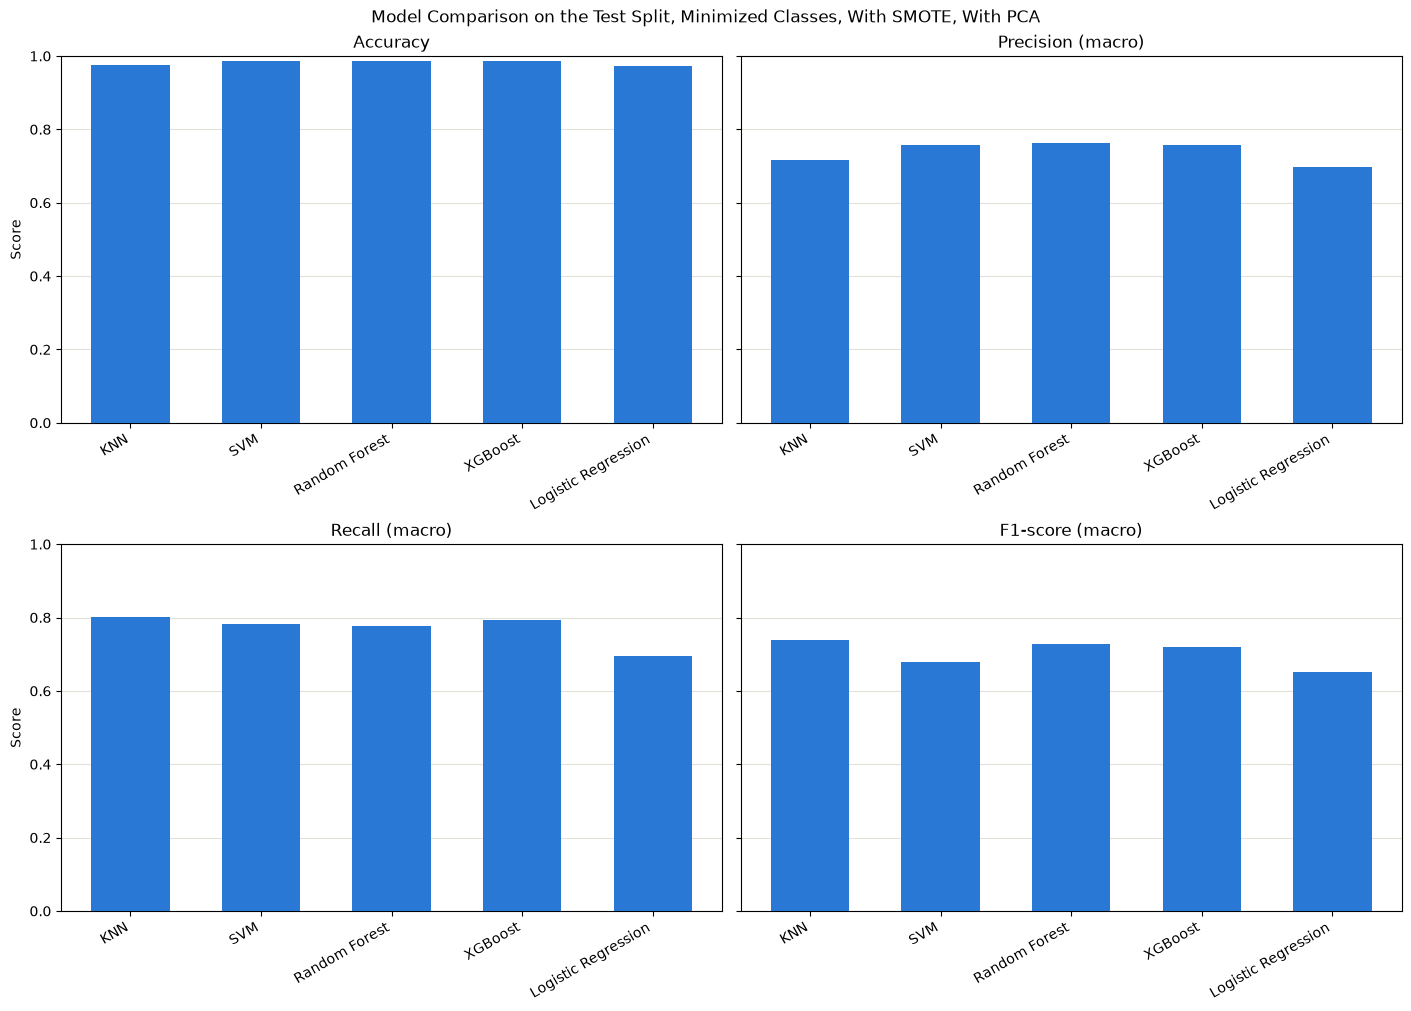

In [287]:
plot_model_comparison(
    clean_metrics,
    save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, MODEL_COMPARISON_PLOT_FILE_NAME),
)

### Scores Against Noise Intensity

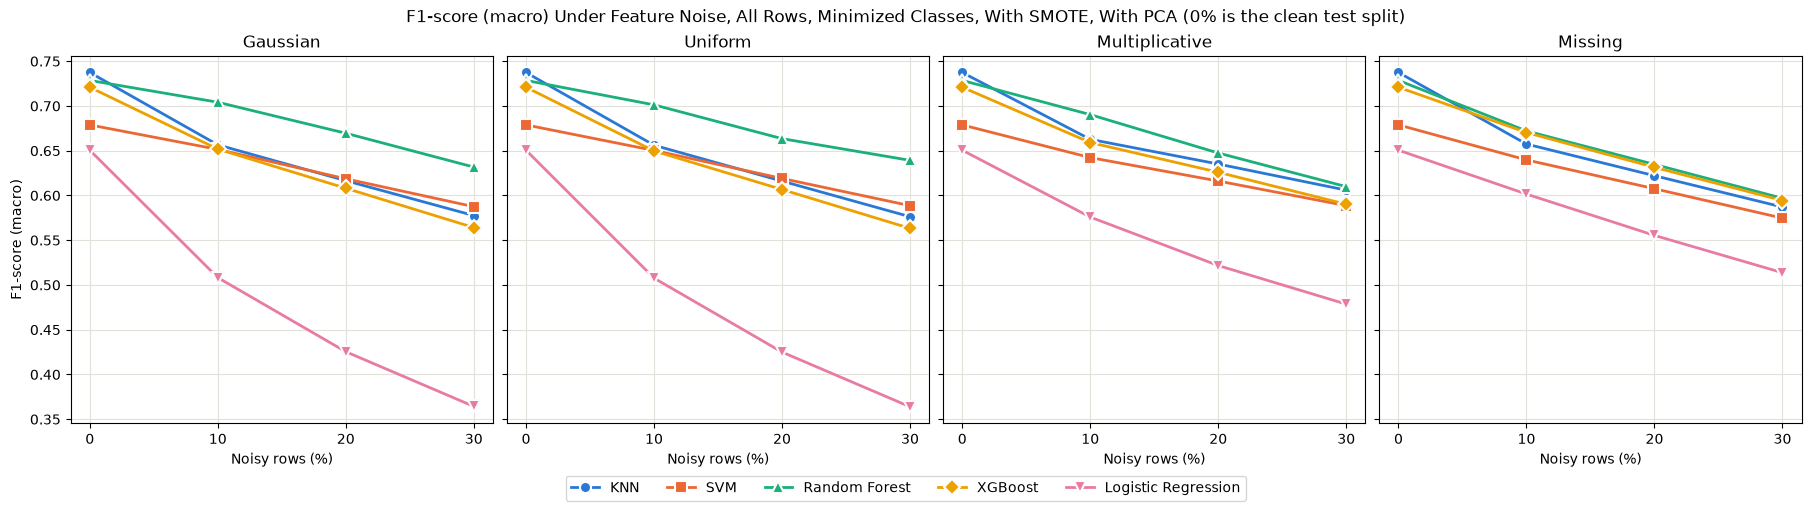

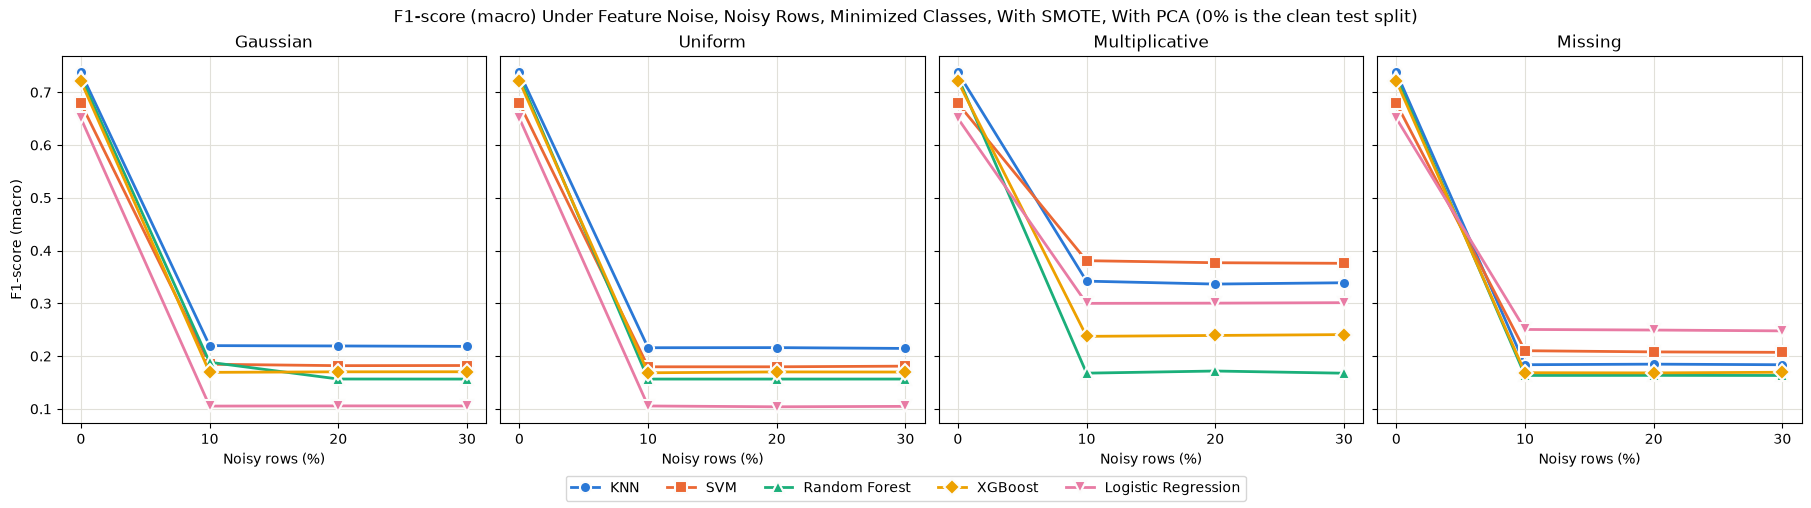

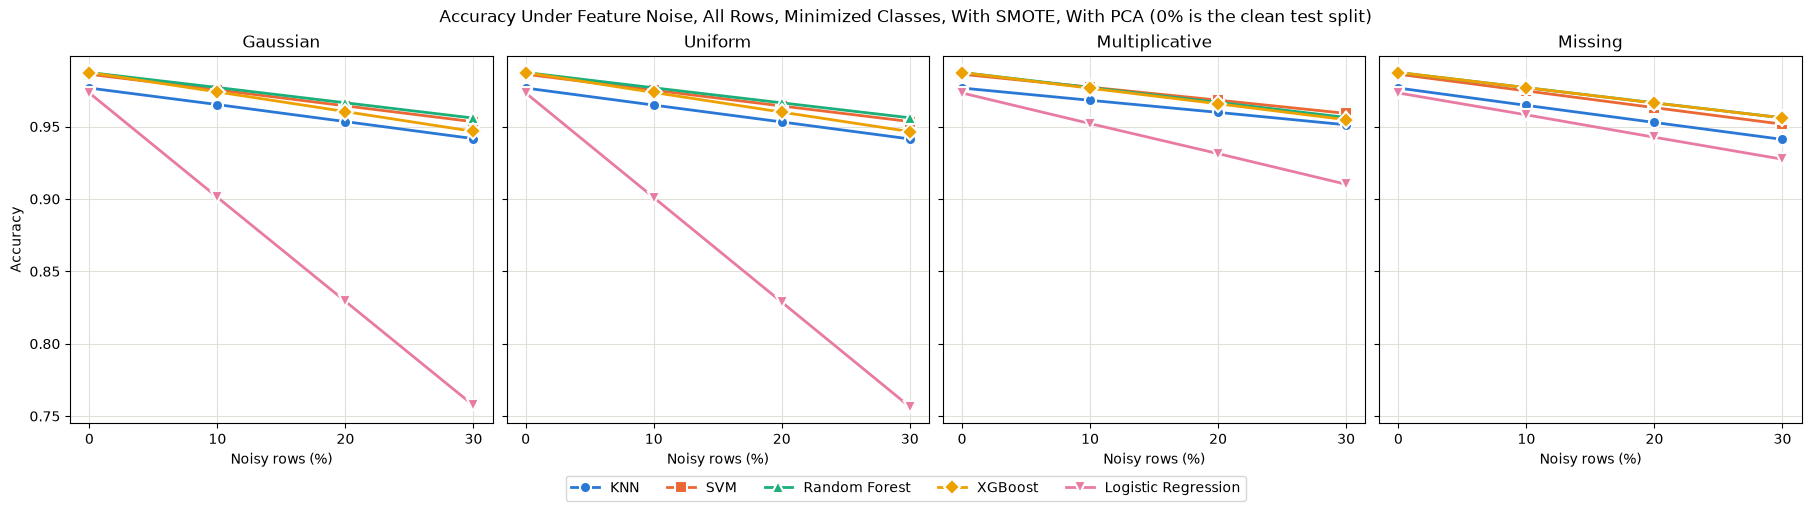

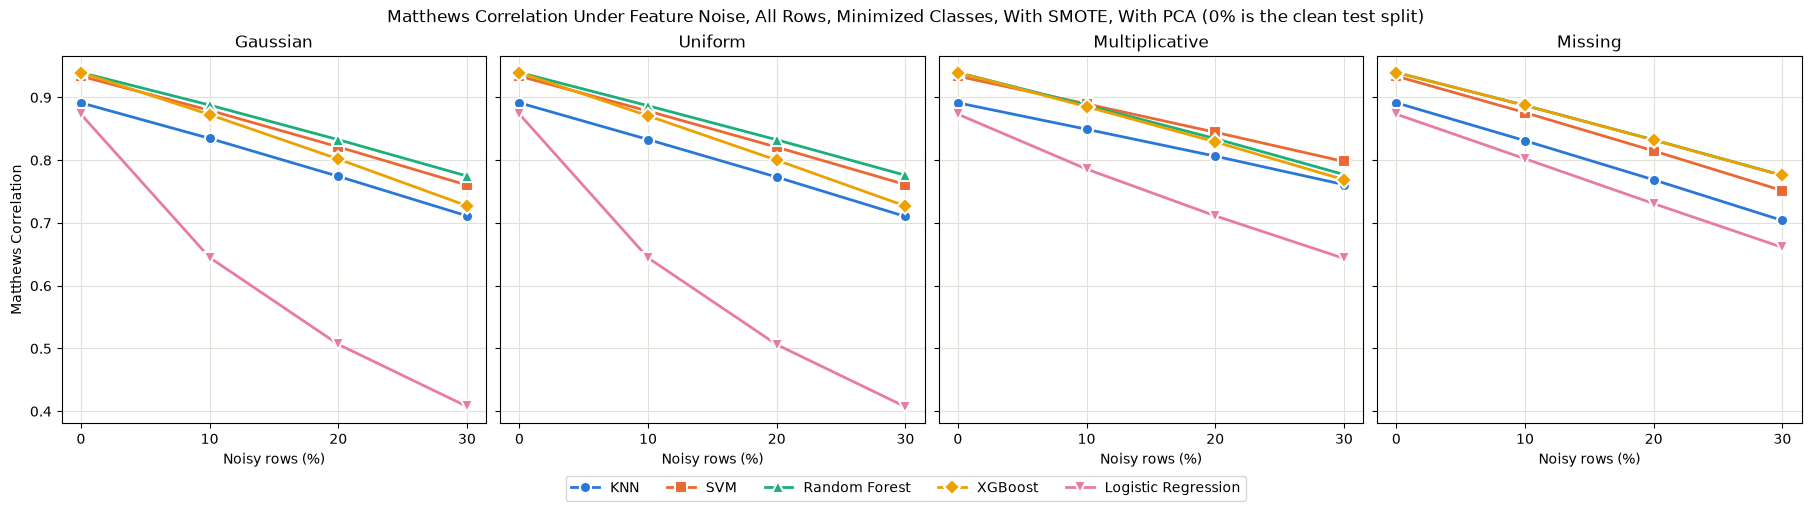

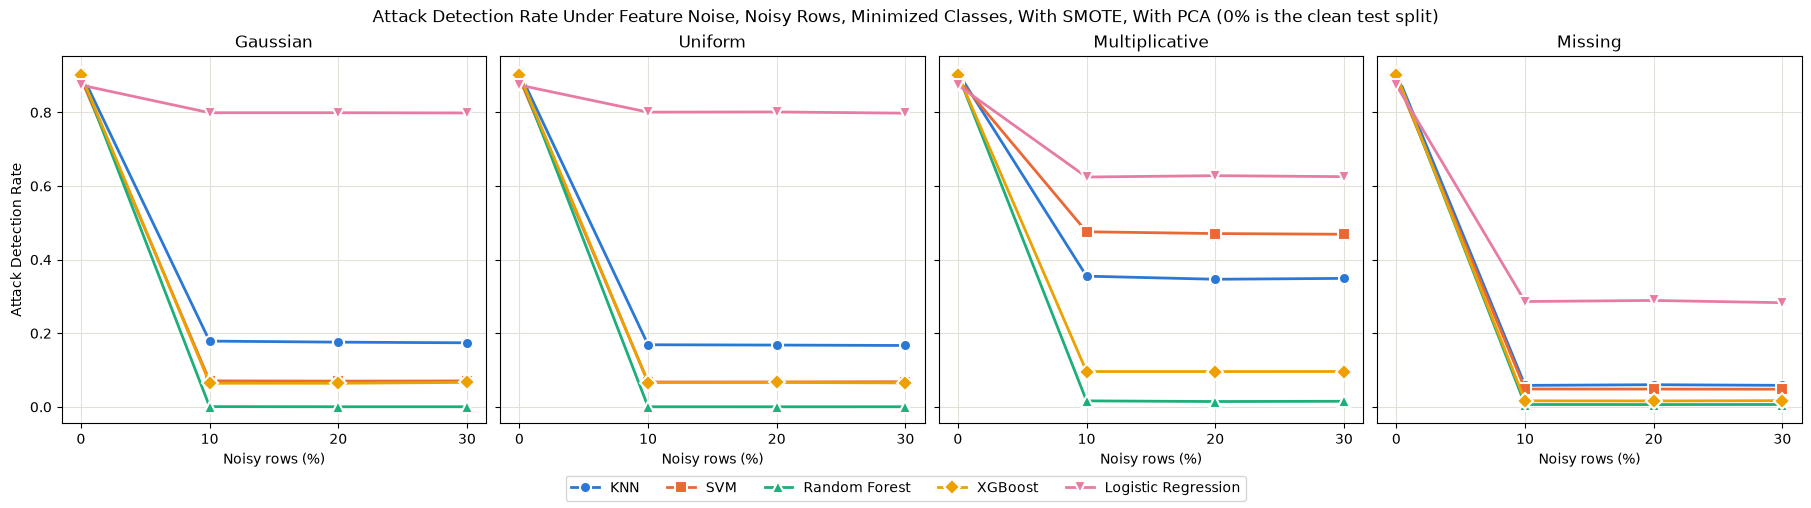

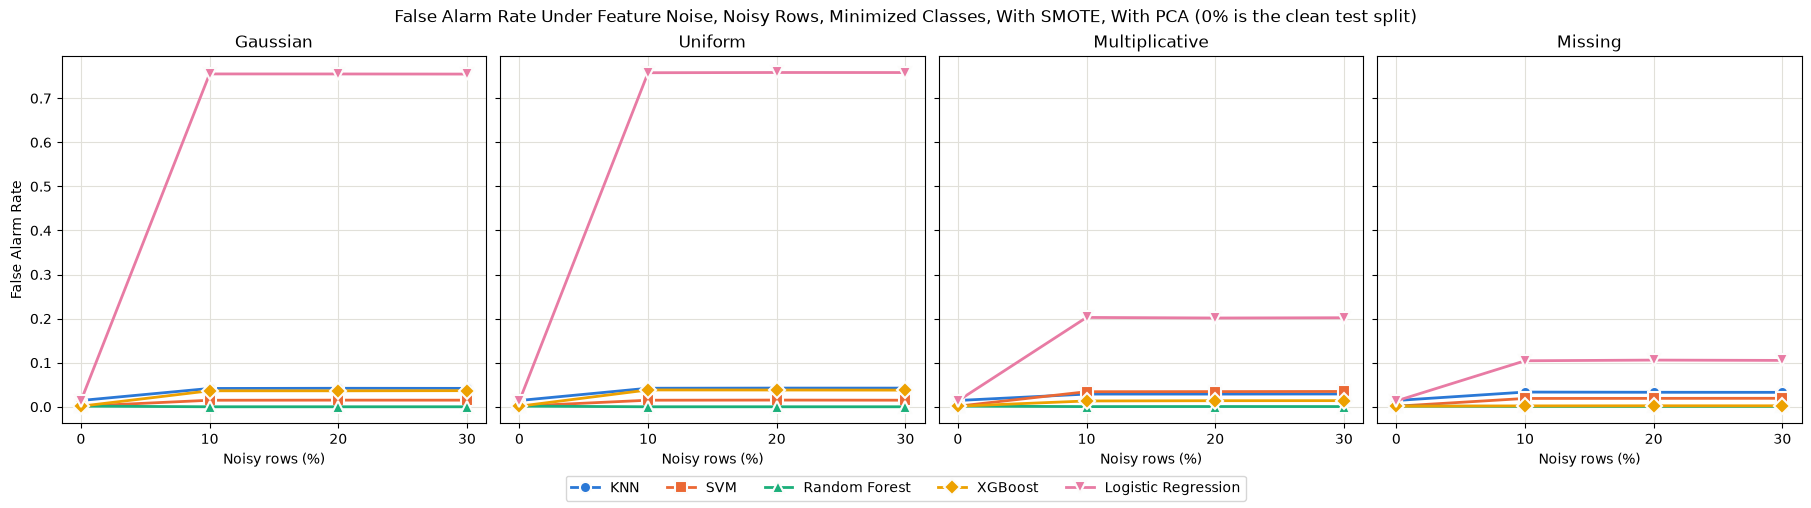

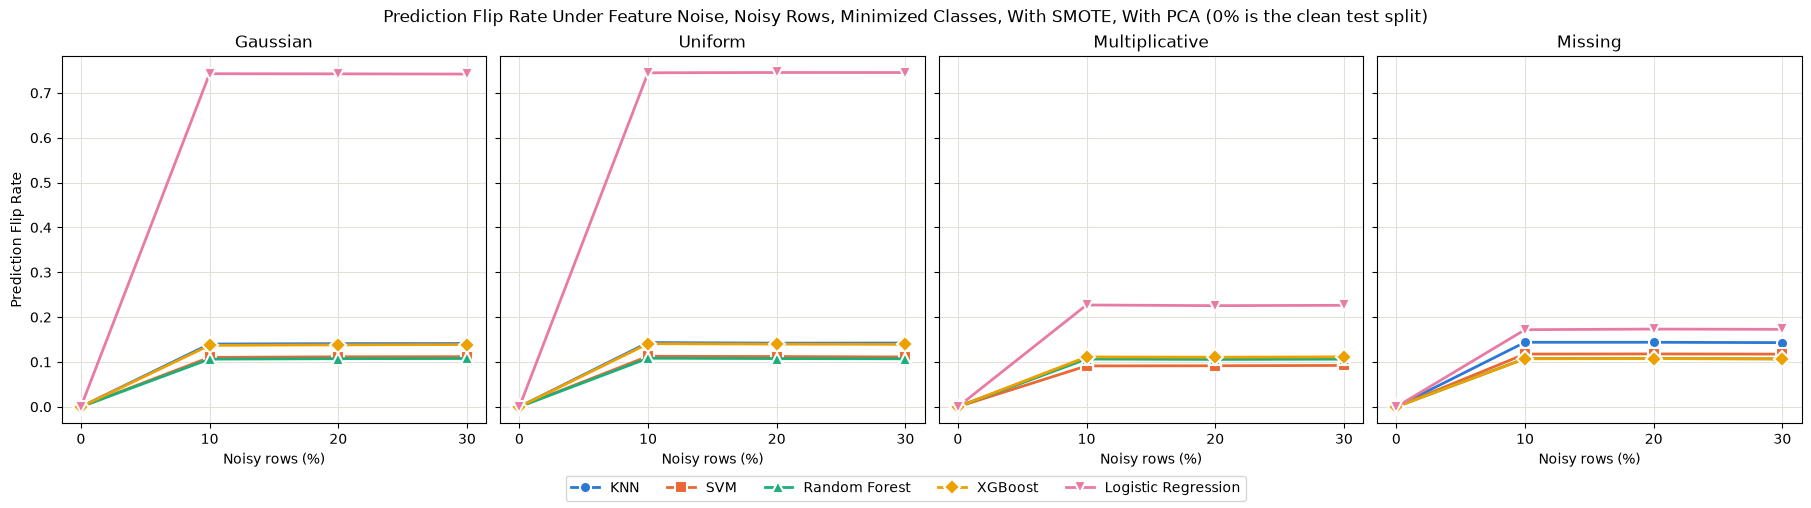

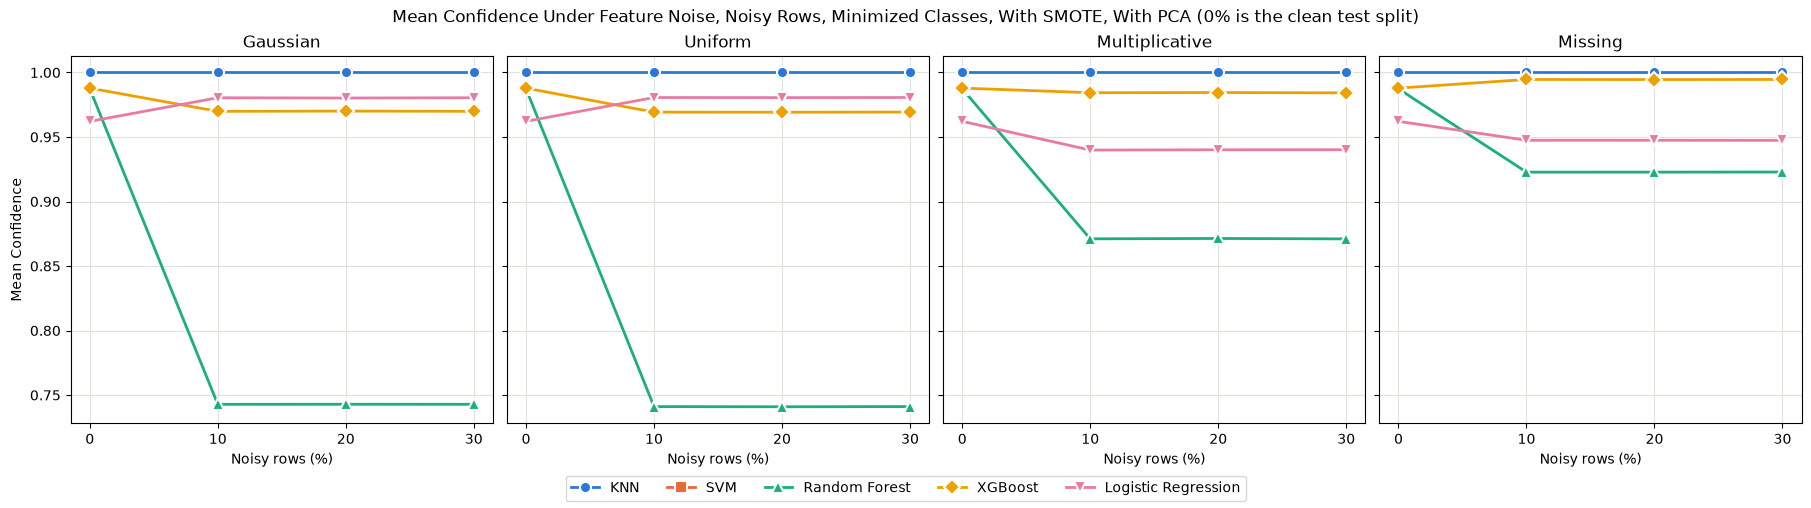

In [288]:
for metric, population in INTENSITY_PLOTS:
    plot_metric_against_intensity(
        metrics,
        metric,
        population,
        save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, f"{metric}-{population}-against-intensity.png"),
    )

### Retention

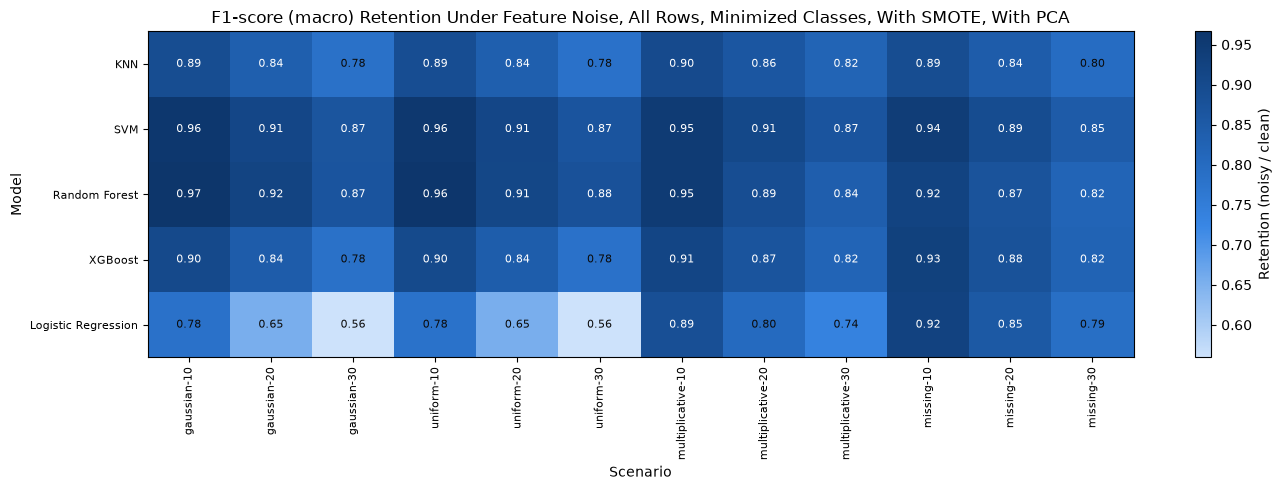

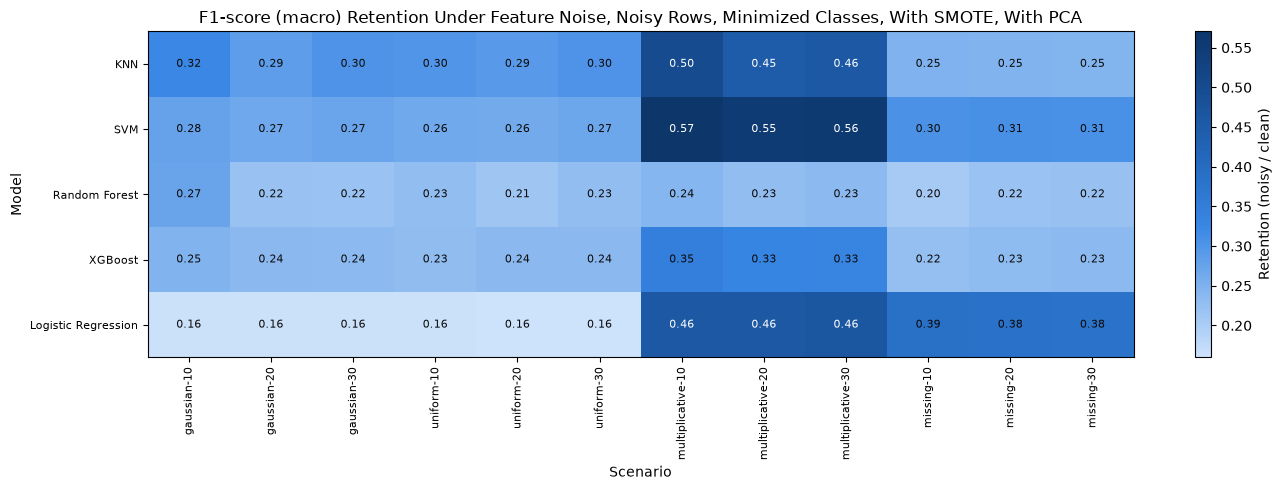

In [289]:
for population in ["all", "noisy"]:
    plot_scenario_heatmap(
        degradation[degradation[METRIC_COLUMN] == ROBUSTNESS_METRIC],
        RETENTION_COLUMN,
        population,
        f"{METRIC_LABELS[ROBUSTNESS_METRIC]} Retention Under Feature Noise, {POPULATIONS[population]}",
        "Retention (noisy / clean)",
        os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, f"{ROBUSTNESS_METRIC}-{population}-retention.png"),
    )

### Robustness Ranking

,rank,metric,population,experiment,model,scenarios,mean_clean_value,mean_value,mean_retention,worst_retention,worst_scenario,mean_drop,max_drop,gaussian_retention,uniform_retention,multiplicative_retention,missing_retention
75,1,f1_macro,all,minimized_with-smote_with-pca,svm,12,0.6788,0.6154,0.9065,0.8466,missing-30,0.0635,0.1042,0.9121,0.9123,0.9070,0.8946
76,2,f1_macro,all,minimized_with-smote_with-pca,rf,12,0.7285,0.6551,0.8991,0.8192,missing-30,0.0735,0.1317,0.9176,0.9169,0.8911,0.8710
77,3,f1_macro,all,minimized_with-smote_with-pca,xgb,12,0.7209,0.6179,0.8572,0.7813,uniform-30,0.1030,0.1576,0.8434,0.8414,0.8671,0.8767
78,4,f1_macro,all,minimized_with-smote_with-pca,knn,12,0.7374,0.6225,0.8441,0.7815,uniform-30,0.1149,0.1611,0.8366,0.8356,0.8606,0.8438
79,5,f1_macro,all,minimized_with-smote_with-pca,logreg,12,0.6506,0.4868,0.7482,0.5593,uniform-30,0.1638,0.2867,0.6650,0.6643,0.8076,0.8560


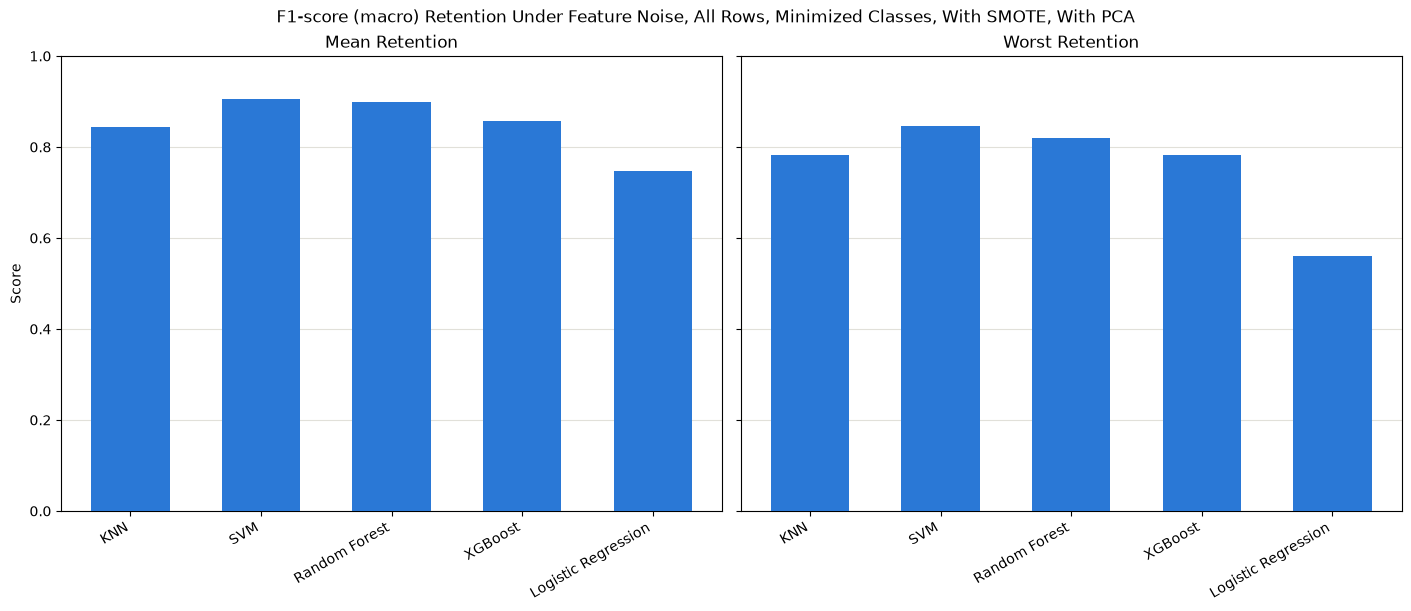

,rank,metric,population,experiment,model,scenarios,mean_clean_value,mean_value,mean_retention,worst_retention,worst_scenario,mean_drop,max_drop,gaussian_retention,uniform_retention,multiplicative_retention,missing_retention
85,1,f1_macro,noisy,minimized_with-smote_with-pca,svm,12,0.6767,0.2373,0.3508,0.2639,uniform-20,0.4394,0.5013,0.2713,0.2662,0.5597,0.3060
86,2,f1_macro,noisy,minimized_with-smote_with-pca,knn,12,0.7294,0.2394,0.3293,0.2451,missing-30,0.4900,0.5654,0.3037,0.2971,0.4698,0.2466
87,3,f1_macro,noisy,minimized_with-smote_with-pca,logreg,12,0.6503,0.1900,0.2921,0.1597,uniform-20,0.4603,0.5467,0.1622,0.1611,0.4618,0.3834
88,4,f1_macro,noisy,minimized_with-smote_with-pca,xgb,12,0.7192,0.1868,0.2601,0.2244,missing-10,0.5324,0.5823,0.2398,0.2347,0.3357,0.2301
89,5,f1_macro,noisy,minimized_with-smote_with-pca,rf,12,0.7219,0.1640,0.2276,0.2045,missing-10,0.5580,0.6351,0.2372,0.2228,0.2354,0.2150


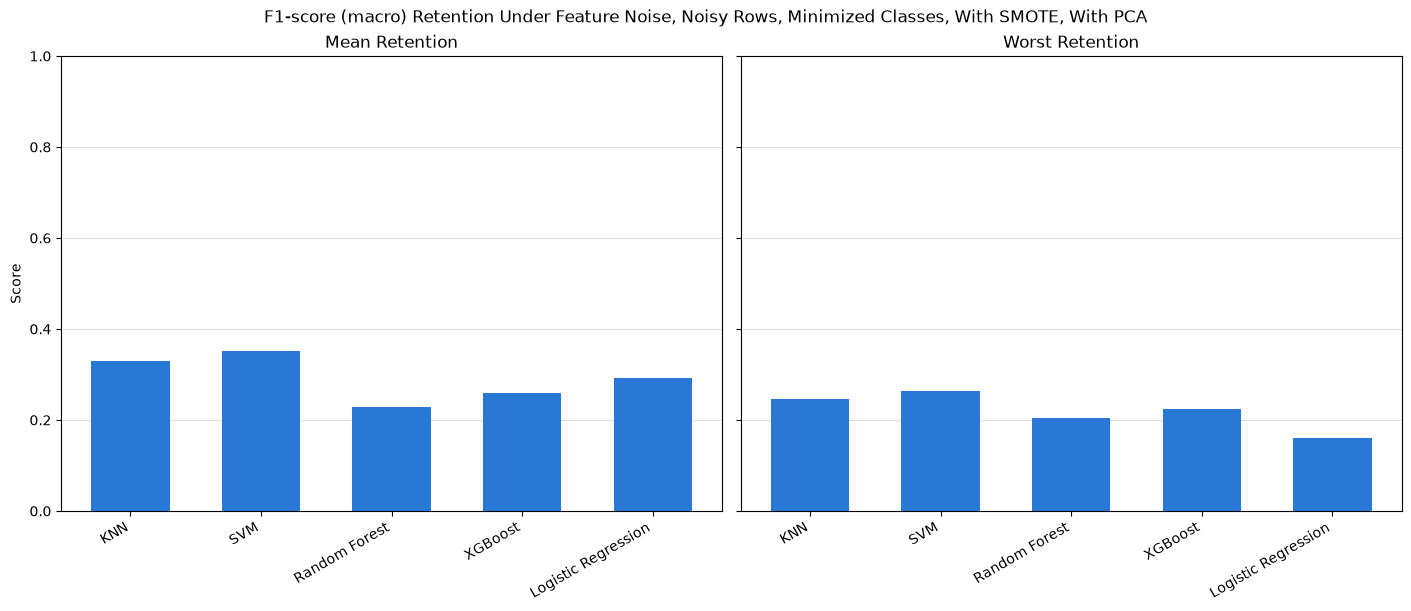

In [290]:
ranking = rank_robustness(degradation)
save_evaluation_table(ranking, ROBUSTNESS_RANKING_FILE_NAME)
for population in ["all", "noisy"]:
    is_shown = (ranking[METRIC_COLUMN] == ROBUSTNESS_METRIC) & (ranking[POPULATION_COLUMN] == population)
    display(ranking[is_shown].round(4))
    plot_model_comparison(
        ranking[is_shown],
        metrics={"mean_retention": "Mean Retention", "worst_retention": "Worst Retention"},
        figsize=(14, 6),
        title=f"{METRIC_LABELS[ROBUSTNESS_METRIC]} Retention Under Feature Noise, {POPULATIONS[population]}",
        save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, f"{ROBUSTNESS_METRIC}-{population}-ranking.png"),
    )

### Intact and Noisy Rows

In [291]:
is_intact = (metrics[POPULATION_COLUMN] == "intact") & (metrics[SCENARIO_COLUMN] != CLEAN_SCENARIO)
intact_flip_rate = metrics[is_intact].groupby([EXPERIMENT_COLUMN, MODEL_COLUMN], sort=False)["flip_rate"].max()
end_status(f"At most {intact_flip_rate.max():.4%} of the intact rows changed prediction from the clean test split")
display(intact_flip_rate.rename("max_intact_flip_rate").to_frame())
display(
    metrics[metrics[POPULATION_COLUMN] != "all"].pivot_table(
        index=[EXPERIMENT_COLUMN, MODEL_COLUMN],
        columns=[NOISE_TYPE_COLUMN, POPULATION_COLUMN],
        values=ROBUSTNESS_METRIC,
    ).round(4)
)

At most 0.0000% of the intact rows changed prediction from the clean test split 


max_intact_flip_rate
experiment                    model                       
minimized_with-smote_with-pca knn                      0.0
                              svm                      0.0
                              rf                       0.0
                              xgb                      0.0
                              logreg                   0.0

noise_type                             clean gaussian         missing          \
population                            intact   intact   noisy  intact   noisy   
experiment                    model                                             
minimized_with-smote_with-pca knn     0.7374   0.7386  0.2191  0.7352  0.1840   
                              logreg  0.6506   0.6506  0.1055  0.6506  0.2492   
                              rf      0.7285   0.7329  0.1671  0.7249  0.1633   
                              svm     0.6788   0.6798  0.1829  0.6790  0.2084   
                              xgb     0.7209   0.7223  0.1699  0.7193  0.1687   

noise_type                           multiplicative         uniform          
population                                   intact   noisy  intact   noisy  
experiment                    model                                          
minimized_with-smote_with-pca knn            0.7382  0.3391  0.7396  0.2155  
                              logreg         0.6506  0.3005  0.6507  0.1047  
                              rf             0.7301  0.1690  0.7329  0.1565  
                              svm            0.6794  0.3778  0.6797  0.1801  
                              xgb            0.7205  0.2391  0.7211  0.1694

In [292]:
mixture_check = check_mixture_identity(metrics)
save_evaluation_table(mixture_check, MIXTURE_CHECK_FILE_NAME)
largest_residual = mixture_check["residual"].abs().max()
end_status(f"The accuracy differs from the mixture of the intact and noisy rows by at most {largest_residual:.2e}")
display(mixture_check.round(6))

The accuracy differs from the mixture of the intact and noisy rows by at most 1.11e-16


,experiment,model,scenario,intensity,noisy_fraction,accuracy,intact_accuracy,noisy_accuracy,mixed_accuracy,residual
0,minimized_with-smote_with-pca,knn,gaussian-10,0.1,0.1,0.965208,0.976669,0.862055,0.965208,0.0
1,minimized_with-smote_with-pca,knn,gaussian-20,0.2,0.2,0.953445,0.976604,0.860809,0.953445,0.0
2,minimized_with-smote_with-pca,knn,gaussian-30,0.3,0.3,0.941677,0.976448,0.860543,0.941677,0.0
3,minimized_with-smote_with-pca,knn,missing-10,0.1,0.1,0.964666,0.976597,0.857288,0.964666,0.0
4,minimized_with-smote_with-pca,knn,missing-20,0.2,0.2,0.952867,0.976655,0.857711,0.952867,0.0
5,minimized_with-smote_with-pca,knn,missing-30,0.3,0.3,0.941151,0.976679,0.858253,0.941151,0.0
6,minimized_with-smote_with-pca,knn,multiplicative-10,0.1,0.1,0.968172,0.976579,0.892501,0.968172,-0.0
7,minimized_with-smote_with-pca,knn,multiplicative-20,0.2,0.2,0.959821,0.976610,0.892664,0.959821,0.0
8,minimized_with-smote_with-pca,knn,multiplicative-30,0.3,0.3,0.951233,0.976637,0.891956,0.951233,-0.0
9,minimized_with-smote_with-pca,knn,uniform-10,0.1,0.1,0.964857,0.976626,0.858934,0.964857,-0.0


### Per-Class Metrics

In [293]:
class_metrics = measure_every_class(outcomes, class_names)
save_evaluation_table(class_metrics, CLASS_METRICS_FILE_NAME)
display(class_metrics.round(4))

Scored 6 classes on 190 populations                                             psed ~00:00:00 left


,experiment,model,scenario,noise_type,intensity,population,class,support,predicted,precision,recall,f1,clean_precision,clean_recall,clean_f1,flip_rate,benign_rate,clean_benign_rate,mean_confidence,f1_drop
0,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,Benign,2032684,2028461,0.9878,0.9857,0.9868,0.9878,0.9857,0.9868,0.0000,0.9857,0.9857,1.0000,0.0000
1,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,Bot,28907,28908,0.9998,0.9999,0.9998,0.9998,0.9999,0.9998,0.0000,0.0001,0.0001,1.0000,0.0000
2,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,Brute Force,18975,18943,0.9975,0.9958,0.9966,0.9975,0.9958,0.9966,0.0000,0.0018,0.0018,1.0000,0.0000
3,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,DoS,194392,194406,0.9998,0.9999,0.9999,0.9998,0.9999,0.9999,0.0000,0.0001,0.0001,1.0000,0.0000
4,minimized_with-smote_with-pca,knn,clean,clean,0.0,all,Infiltration,28122,32323,0.1052,0.1209,0.1125,0.1052,0.1209,0.1125,0.0000,0.8790,0.8790,1.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1135,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,noisy,Bot,8674,4496,0.2008,0.1041,0.1371,0.9900,0.9881,0.9890,0.8847,0.8946,0.0119,0.9356,0.8519
1136,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,noisy,Brute Force,5618,18161,0.0789,0.2549,0.1204,0.9794,0.9888,0.9841,0.7405,0.7175,0.0107,0.9027,0.8636
1137,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,noisy,DoS,57995,57298,0.3287,0.3247,0.3267,0.8826,0.9686,0.9236,0.6616,0.6621,0.0311,0.9012,0.5969
1138,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,noisy,Infiltration,8554,52,0.2500,0.0015,0.0030,0.3548,0.0077,0.0151,0.1030,0.9082,0.9759,0.9544,0.0121


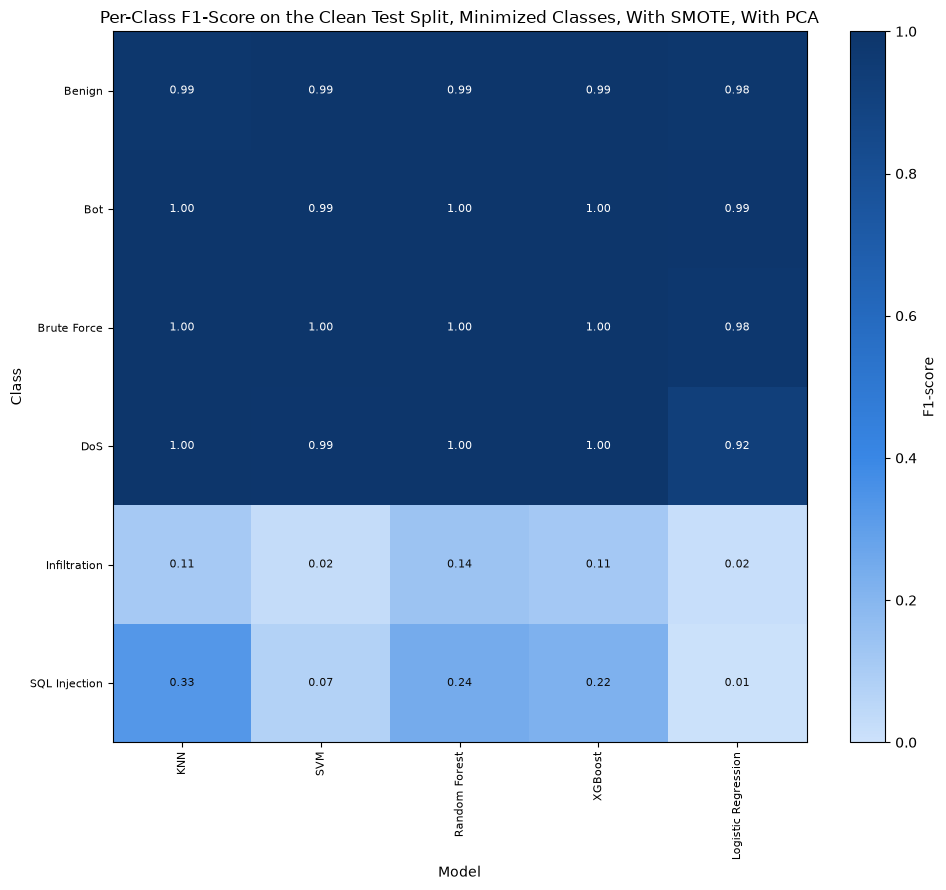

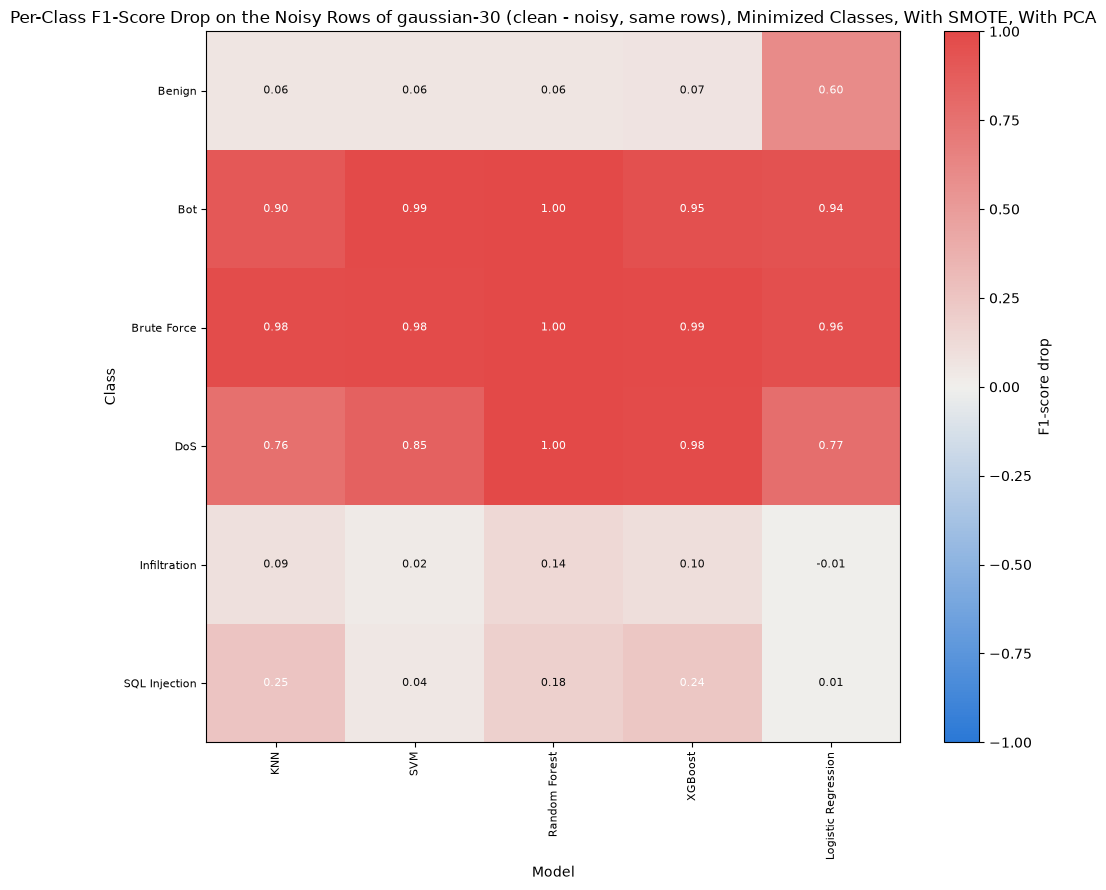

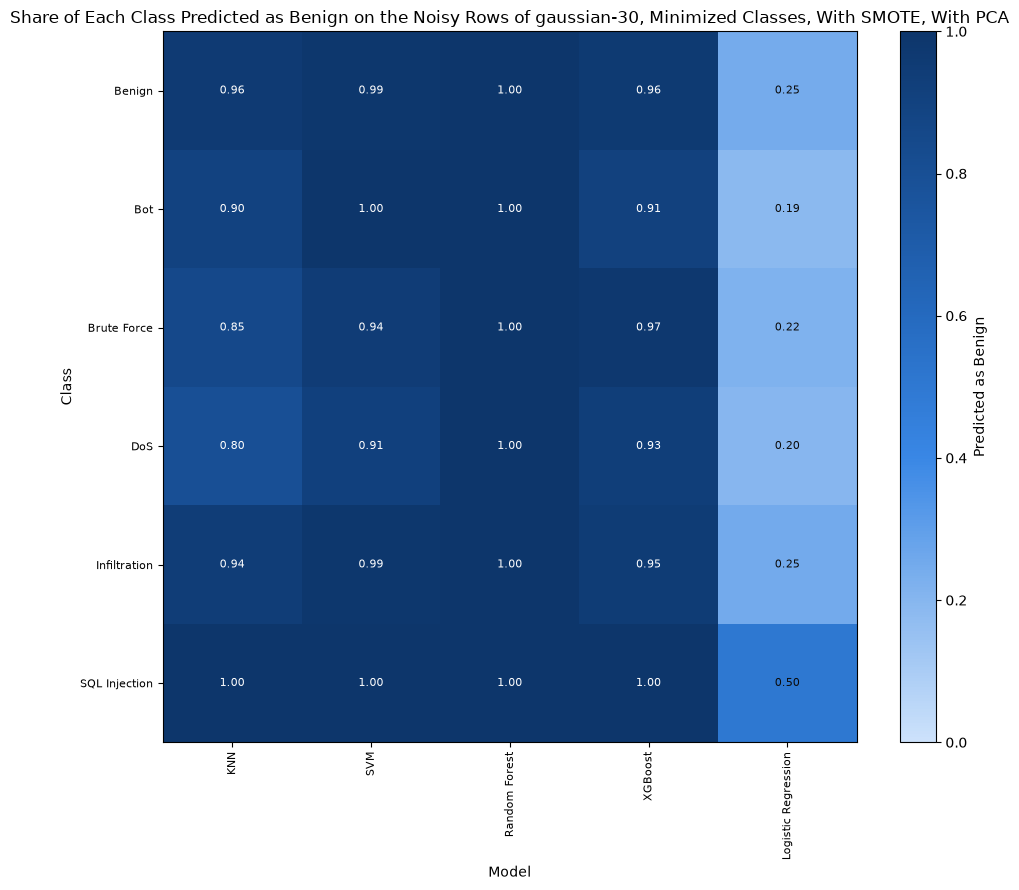

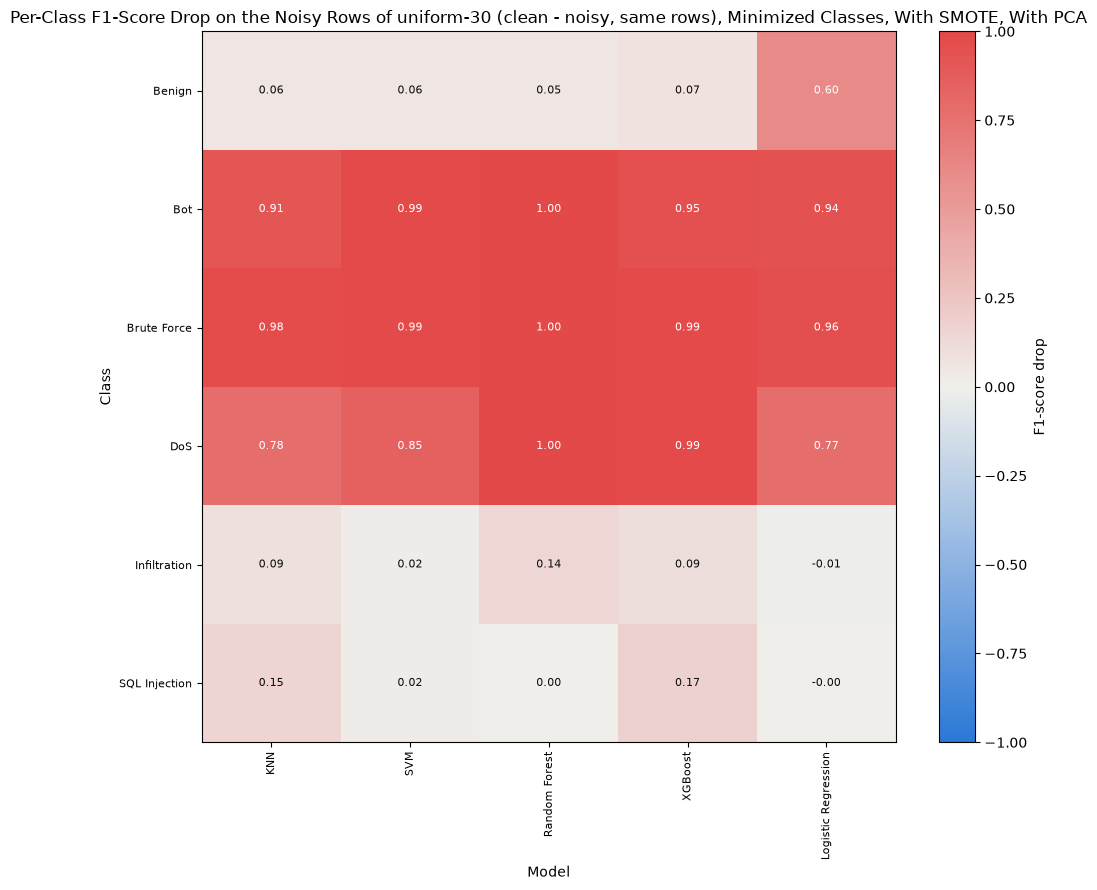

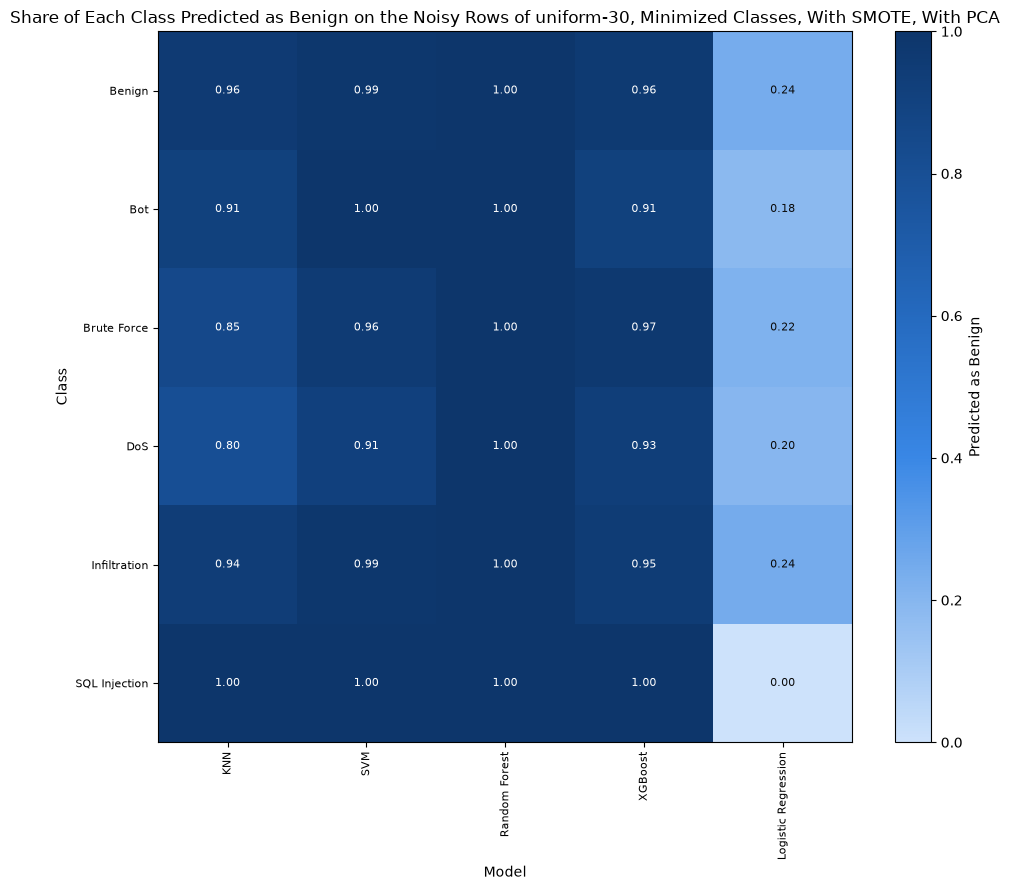

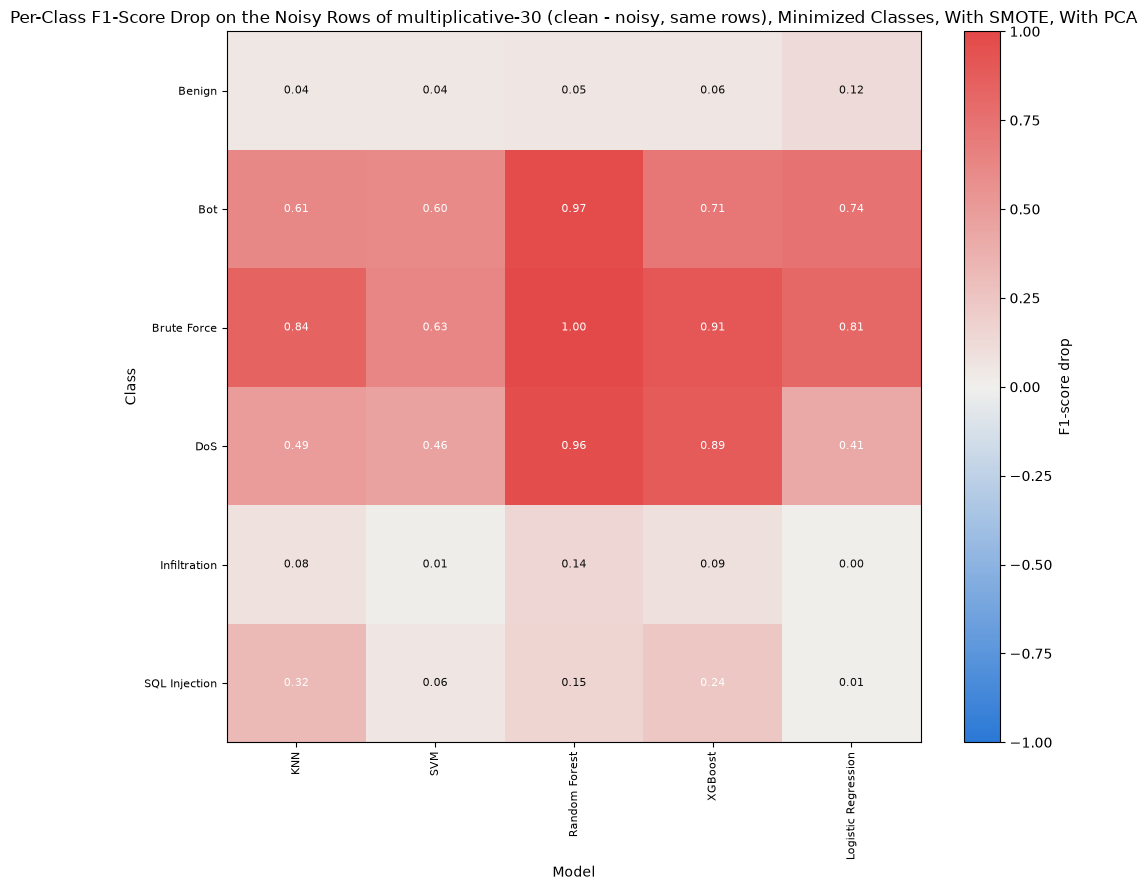

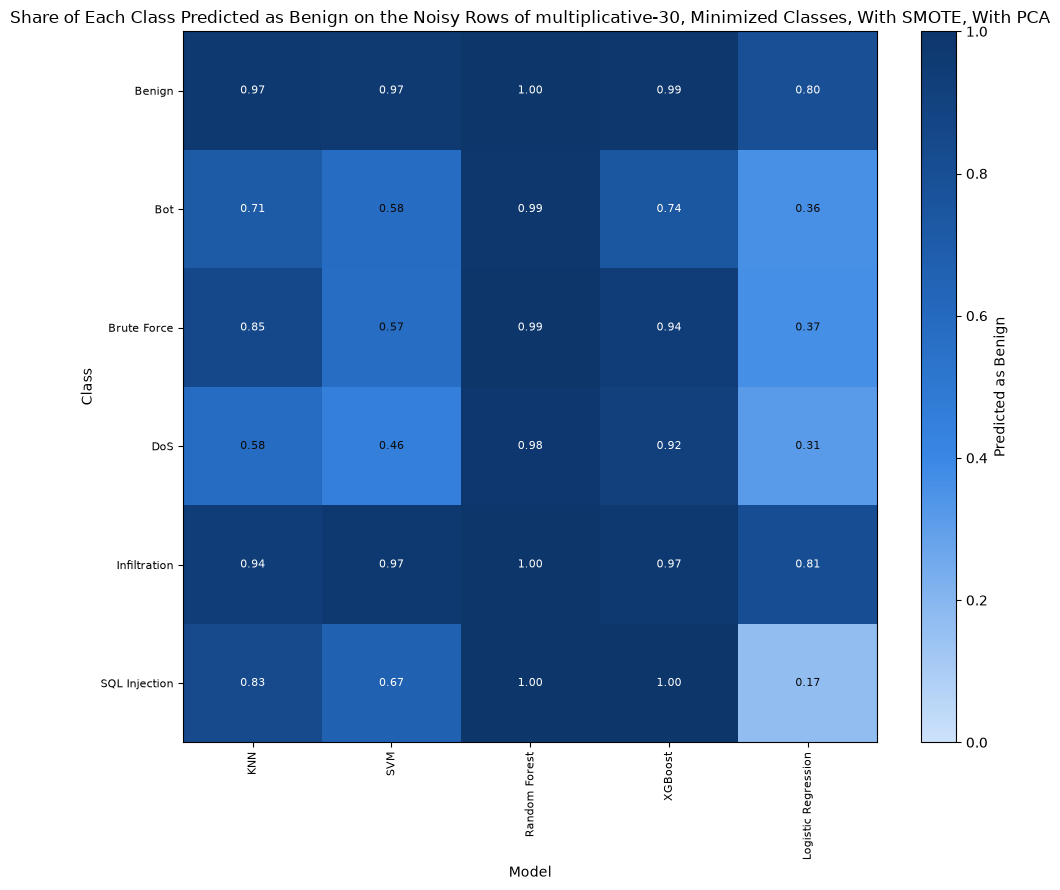

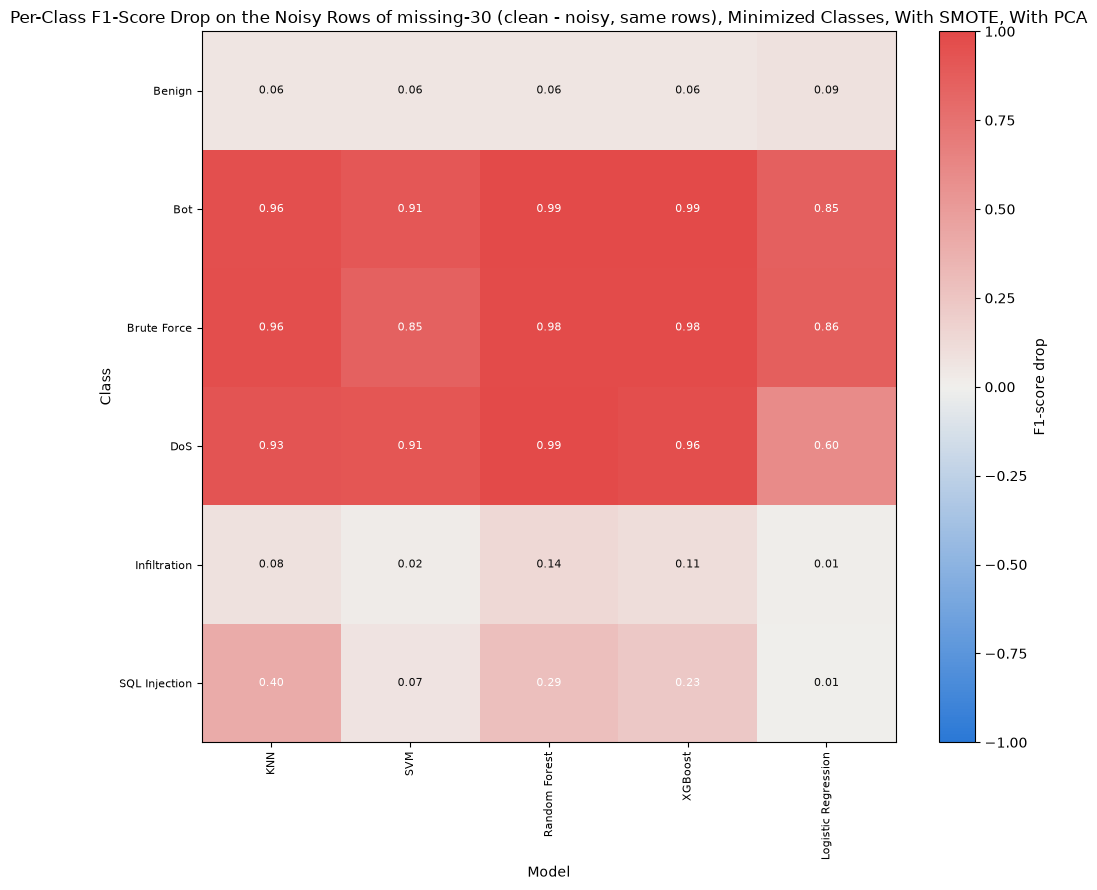

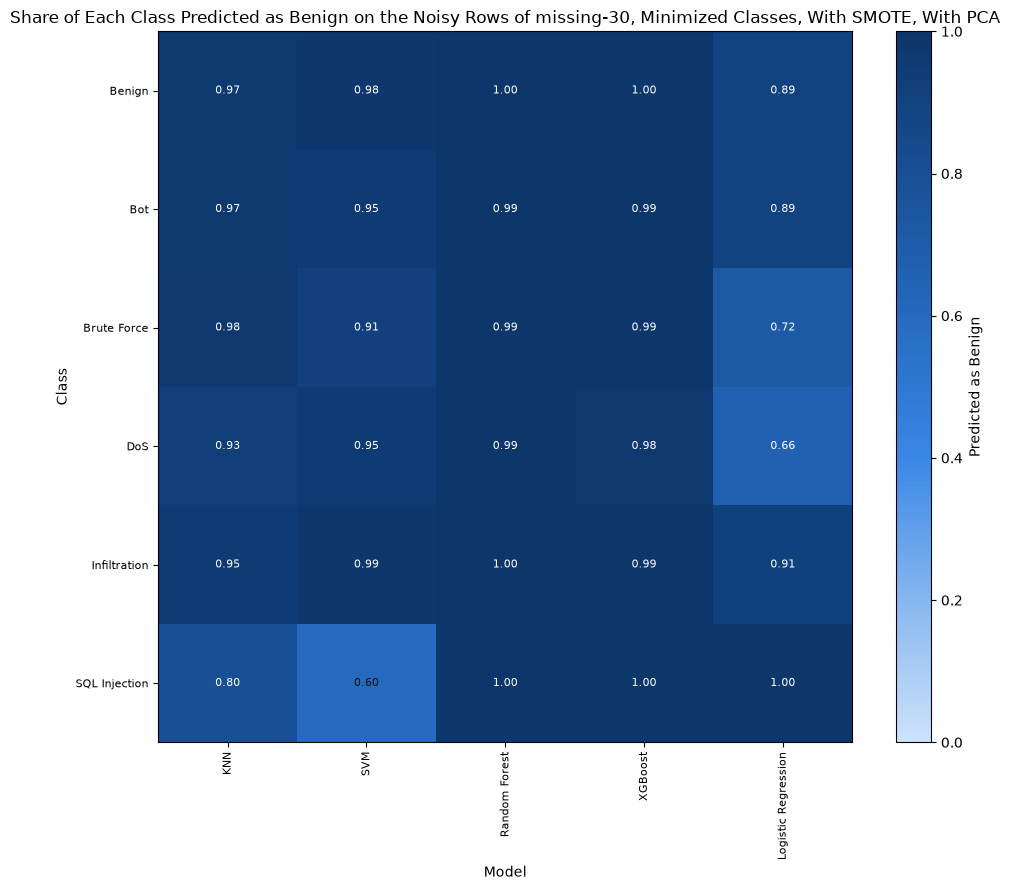

In [294]:
plot_class_heatmap(
    class_metrics,
    class_names,
    CLEAN_SCENARIO,
    "all",
    "f1",
    "Per-Class F1-Score on the Clean Test Split",
    "F1-score",
)
highest_intensity = max(NOISE_INTENSITIES)
for noise_type in NOISE_MAGNITUDES:
    scenario = get_noise_scenario_name(noise_type, highest_intensity)
    plot_class_heatmap(
        class_metrics,
        class_names,
        scenario,
        "noisy",
        "f1_drop",
        f"Per-Class F1-Score Drop on the Noisy Rows of {scenario} (clean - noisy, same rows)",
        "F1-score drop",
        DIVERGING_COLORMAP,
        (-1, 1),
    )
    plot_class_heatmap(
        class_metrics,
        class_names,
        scenario,
        "noisy",
        "benign_rate",
        f"Share of Each Class Predicted as Benign on the Noisy Rows of {scenario}",
        "Predicted as Benign",
    )

### Error Composition

,experiment,model,noise_type,error_rate,missed_attack_share,attack_confusion_share,false_alarm_share,detection_rate,false_alarm_rate
0,minimized_with-smote_with-pca,knn,clean,0.0234,0.4602,0.0011,0.5387,0.9084,0.0143
1,minimized_with-smote_with-pca,knn,gaussian,0.1389,0.6939,0.0405,0.2656,0.1762,0.0418
2,minimized_with-smote_with-pca,knn,uniform,0.1408,0.6952,0.0397,0.2651,0.1678,0.0423
3,minimized_with-smote_with-pca,knn,multiplicative,0.1076,0.7082,0.0548,0.2370,0.3503,0.0289
4,minimized_with-smote_with-pca,knn,missing,0.1422,0.7768,0.0184,0.2048,0.0591,0.0330
5,minimized_with-smote_with-pca,svm,clean,0.0138,0.9117,0.0042,0.0841,0.8926,0.0013
6,minimized_with-smote_with-pca,svm,gaussian,0.1226,0.8873,0.0049,0.1078,0.0704,0.0150
7,minimized_with-smote_with-pca,svm,uniform,0.1234,0.8883,0.0044,0.1073,0.0679,0.0150
8,minimized_with-smote_with-pca,svm,multiplicative,0.1034,0.5995,0.1063,0.2942,0.4718,0.0345
9,minimized_with-smote_with-pca,svm,missing,0.1292,0.8649,0.0049,0.1302,0.0483,0.0191


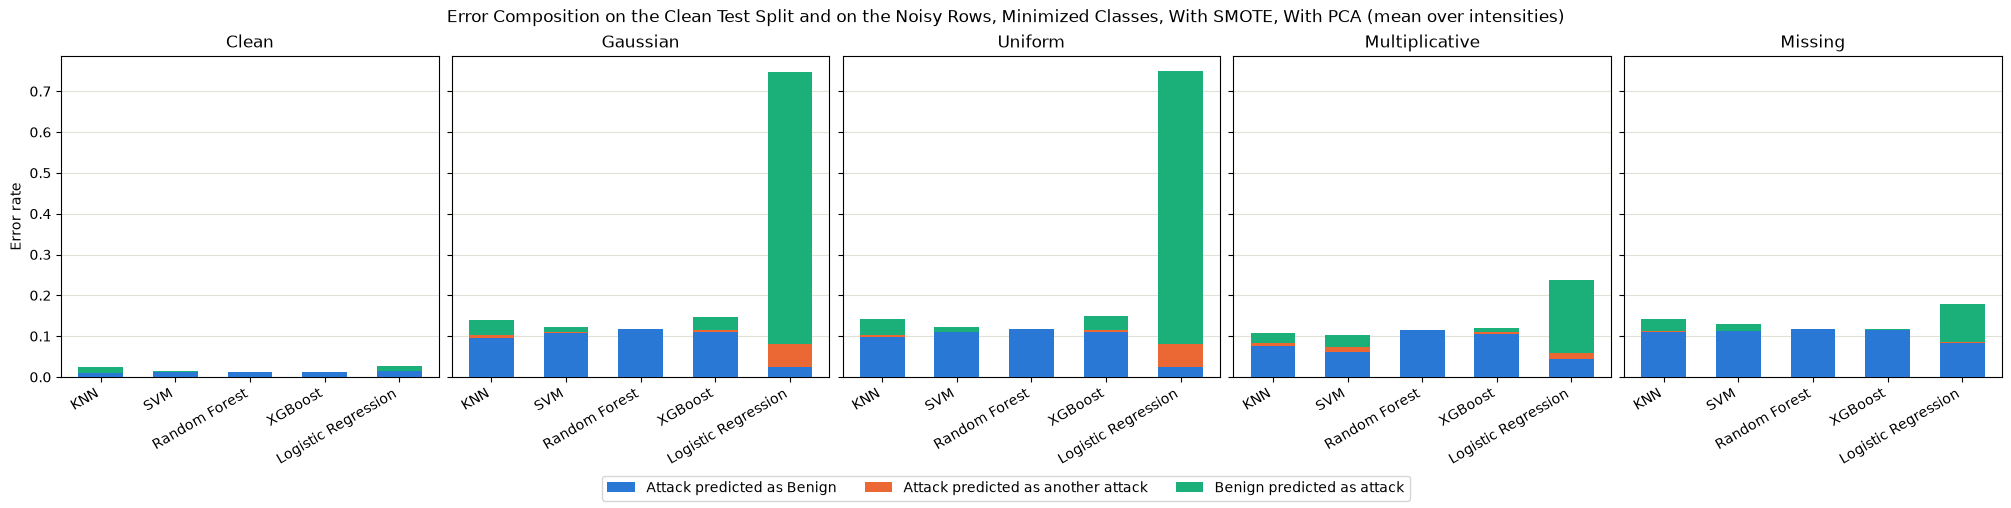

In [295]:
error_composition = measure_error_composition(metrics)
save_evaluation_table(error_composition, ERROR_COMPOSITION_FILE_NAME)
display(error_composition.round(4))
plot_error_composition(
    error_composition,
    save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, ERROR_COMPOSITION_PLOT_FILE_NAME),
)

### Prediction Stability

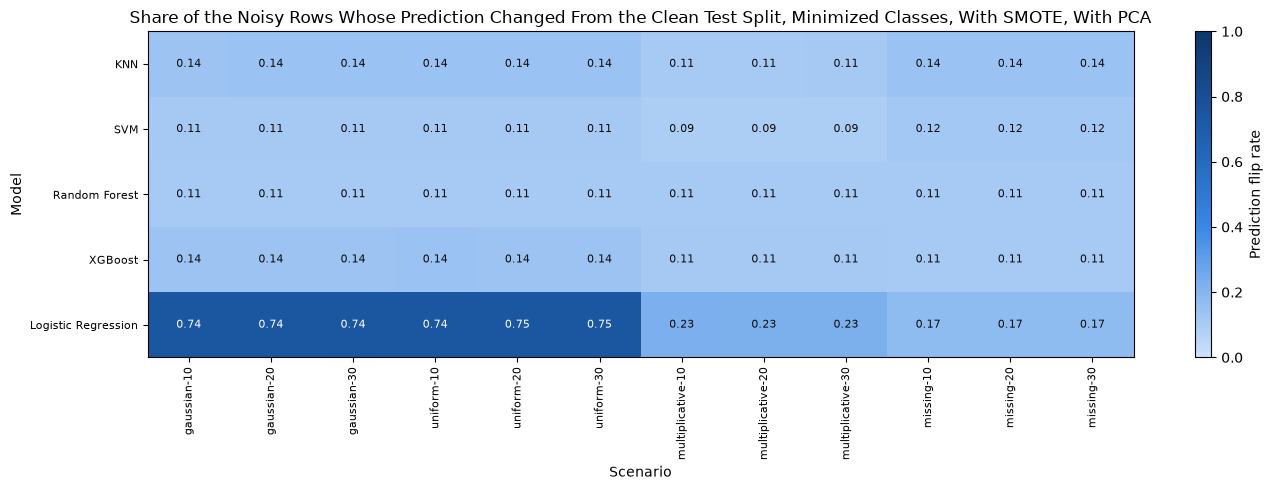

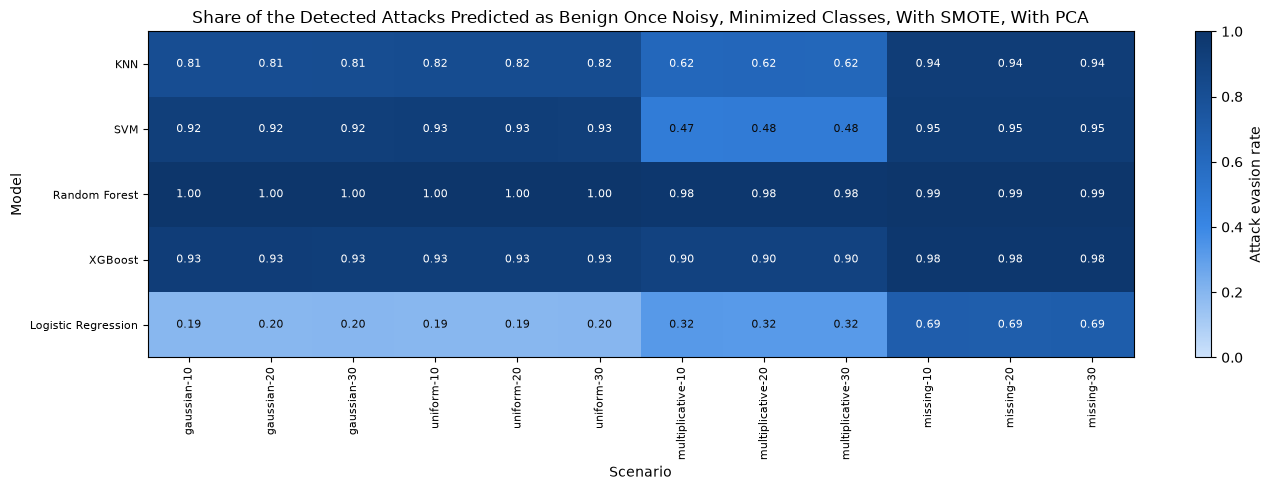

In [296]:
plot_scenario_heatmap(
    metrics,
    "flip_rate",
    "noisy",
    "Share of the Noisy Rows Whose Prediction Changed From the Clean Test Split",
    "Prediction flip rate",
    os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, "flip_rate-noisy-heatmap.png"),
    value_range=(0, 1),
)
plot_scenario_heatmap(
    metrics,
    "evasion_rate",
    "noisy",
    "Share of the Detected Attacks Predicted as Benign Once Noisy",
    "Attack evasion rate",
    os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, "evasion_rate-noisy-heatmap.png"),
    value_range=(0, 1),
)

,experiment,model,scenario,noise_type,intensity,bin,rows,mean_displacement,flip_rate,error_rate
0,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,0,23031,3.8556,0.1246,0.1228
1,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,1,23031,4.3151,0.1365,0.1348
2,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,2,23031,4.5629,0.1385,0.1376
3,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,3,23031,4.7629,0.1341,0.1322
4,minimized_with-smote_with-pca,knn,gaussian-10,gaussian,0.1,4,23031,4.9443,0.1412,0.1395
...,...,...,...,...,...,...,...,...,...,...
595,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,5,69092,3.1891,0.1879,0.1912
596,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,6,69093,3.5907,0.1740,0.1824
597,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,7,69093,4.0391,0.1551,0.1670
598,minimized_with-smote_with-pca,logreg,missing-30,missing,0.3,8,69093,4.7188,0.1290,0.1408


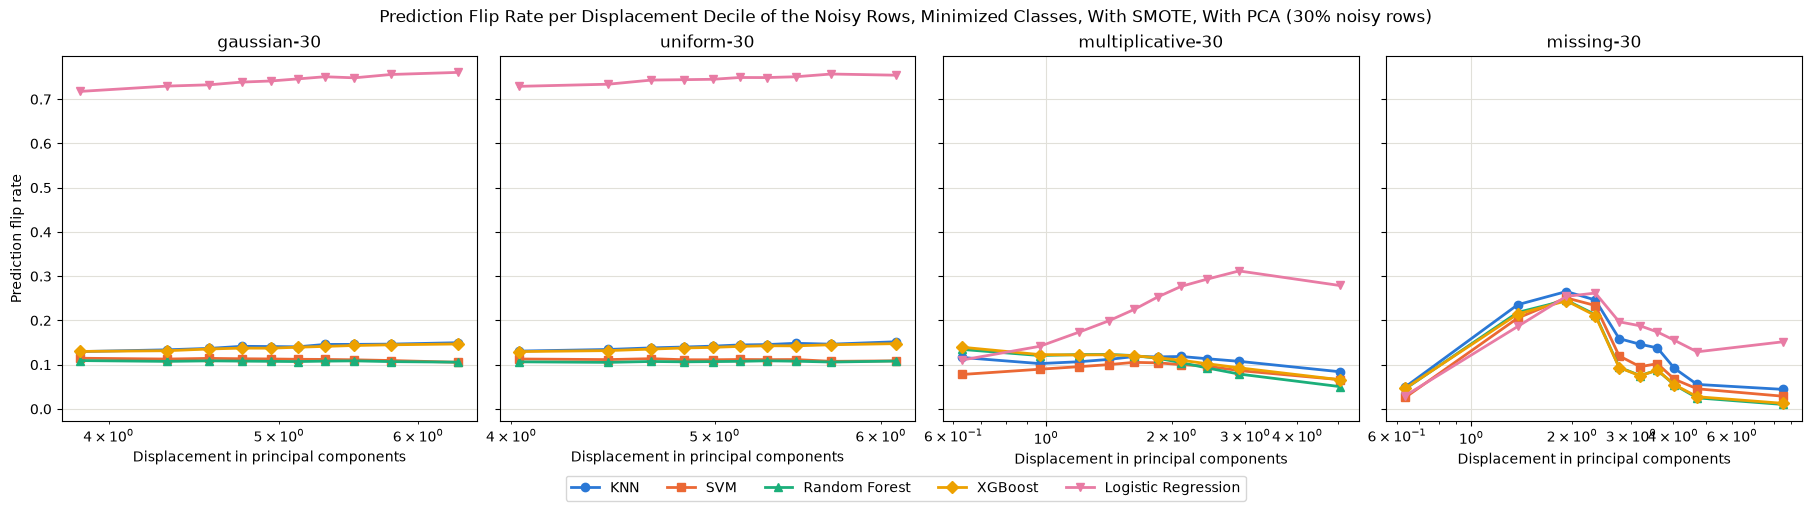

In [297]:
display(displacement_bins.round(4))
plot_flip_rate_against_displacement(
    displacement_bins,
    save_path=os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, FLIP_RATE_PLOT_FILE_NAME),
)

### Confidence

confidence_gap                           \
noise_type                                    clean gaussian         missing   
population                                      all      all   noisy     all   
experiment                    model                                            
minimized_with-smote_with-pca knn            0.0234   0.0466  0.1389  0.0471   
                              logreg        -0.0111   0.1366  0.7271  0.0165   
                              rf            -0.0001  -0.0280 -0.1402  0.0080   
                              xgb            0.0005   0.0240  0.1174  0.0228   

                                                                             \
noise_type                                   multiplicative         uniform   
population                             noisy            all   noisy     all   
experiment                    model                                           
minimized_with-smote_with-pca knn     0.1422         0.0403  0.1076  0.0468   
                              logreg  0.1265         0.0265  0.1772  0.1371   
                              rf      0.0402        -0.0026 -0.0128 -0.0284   
                              xgb     0.1121         0.0215  0.1053  0.0241   

                                             log_loss  ... mean_confidence  \
noise_type                                      clean  ...         uniform   
population                             noisy      all  ...           noisy   
experiment                    model                    ...                   
minimized_with-smote_with-pca knn     0.1408   0.3767  ...          1.0000   
                              logreg  0.7300   0.1113  ...          0.9806   
                              rf     -0.1414   0.0507  ...          0.7410   
                              xgb     0.1188   0.0483  ...          0.9693   

                                     mean_error_confidence                   \
noise_type                                           clean gaussian           
population                                             all      all   noisy   
experiment                    model                                           
minimized_with-smote_with-pca knn                   1.0000   1.0000  1.0000   
                              logreg                0.7987   0.9565  0.9841   
                              rf                    0.8648   0.7598  0.7074   
                              xgb                   0.8538   0.9012  0.9201   

                                                                             \
noise_type                           missing         multiplicative           
population                               all   noisy            all   noisy   
experiment                    model                                           
minimized_with-smote_with-pca knn     1.0000  1.0000         1.0000  1.0000   
                              logreg  0.8514  0.8869         0.8573  0.8876   
                              rf      0.8767  0.8824         0.7890  0.7511   
                              xgb     0.9432  0.9875         0.9180  0.9491   

                                                      
noise_type                           uniform          
population                               all   noisy  
experiment                    model                   
minimized_with-smote_with-pca knn     1.0000  1.0000  
                              logreg  0.9568  0.9843  
                              rf      0.7587  0.7064  
                              xgb     0.9001  0.9183  

[4 rows x 36 columns]

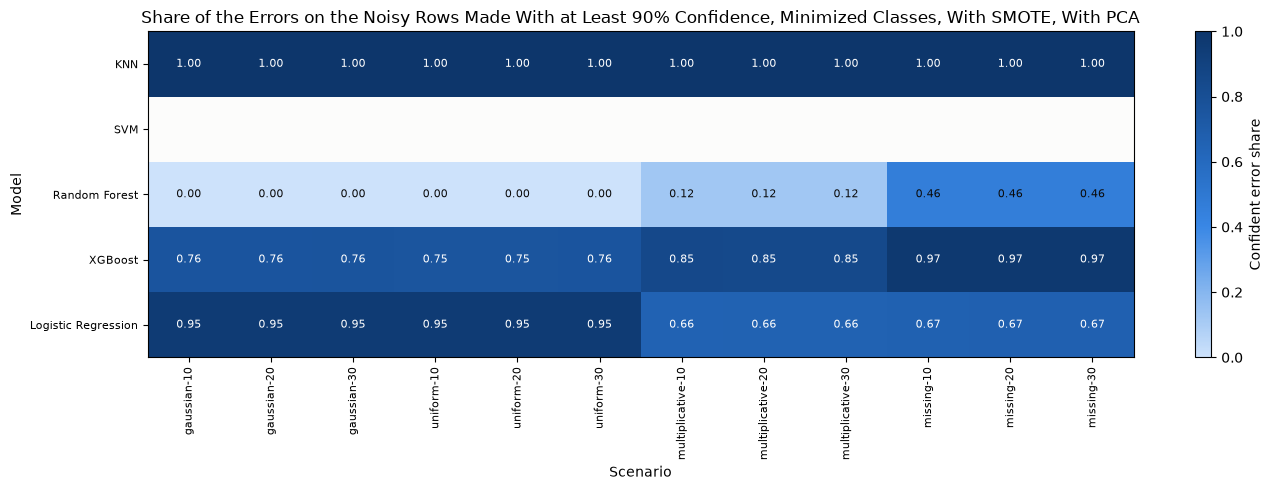

In [298]:
if metrics["mean_confidence"].notna().any():
    display(
        metrics[metrics[POPULATION_COLUMN] != "intact"].pivot_table(
            index=[EXPERIMENT_COLUMN, MODEL_COLUMN],
            columns=[NOISE_TYPE_COLUMN, POPULATION_COLUMN],
            values=["mean_confidence", "mean_error_confidence", "confidence_gap", "log_loss"],
        ).round(4)
    )
    plot_scenario_heatmap(
        metrics,
        "confident_error_share",
        "noisy",
        f"Share of the Errors on the Noisy Rows Made With at Least {CONFIDENT_ERROR_THRESHOLD:.0%} Confidence",
        "Confident error share",
        os.path.join(PATH_FOLDER_EXPERIMENT_EVALUATION, "confident_error_share-noisy-heatmap.png"),
        value_range=(0, 1),
    )
else:
    end_status("No model gave probabilities, so there is no confidence to compare")

### Confusion Matrices

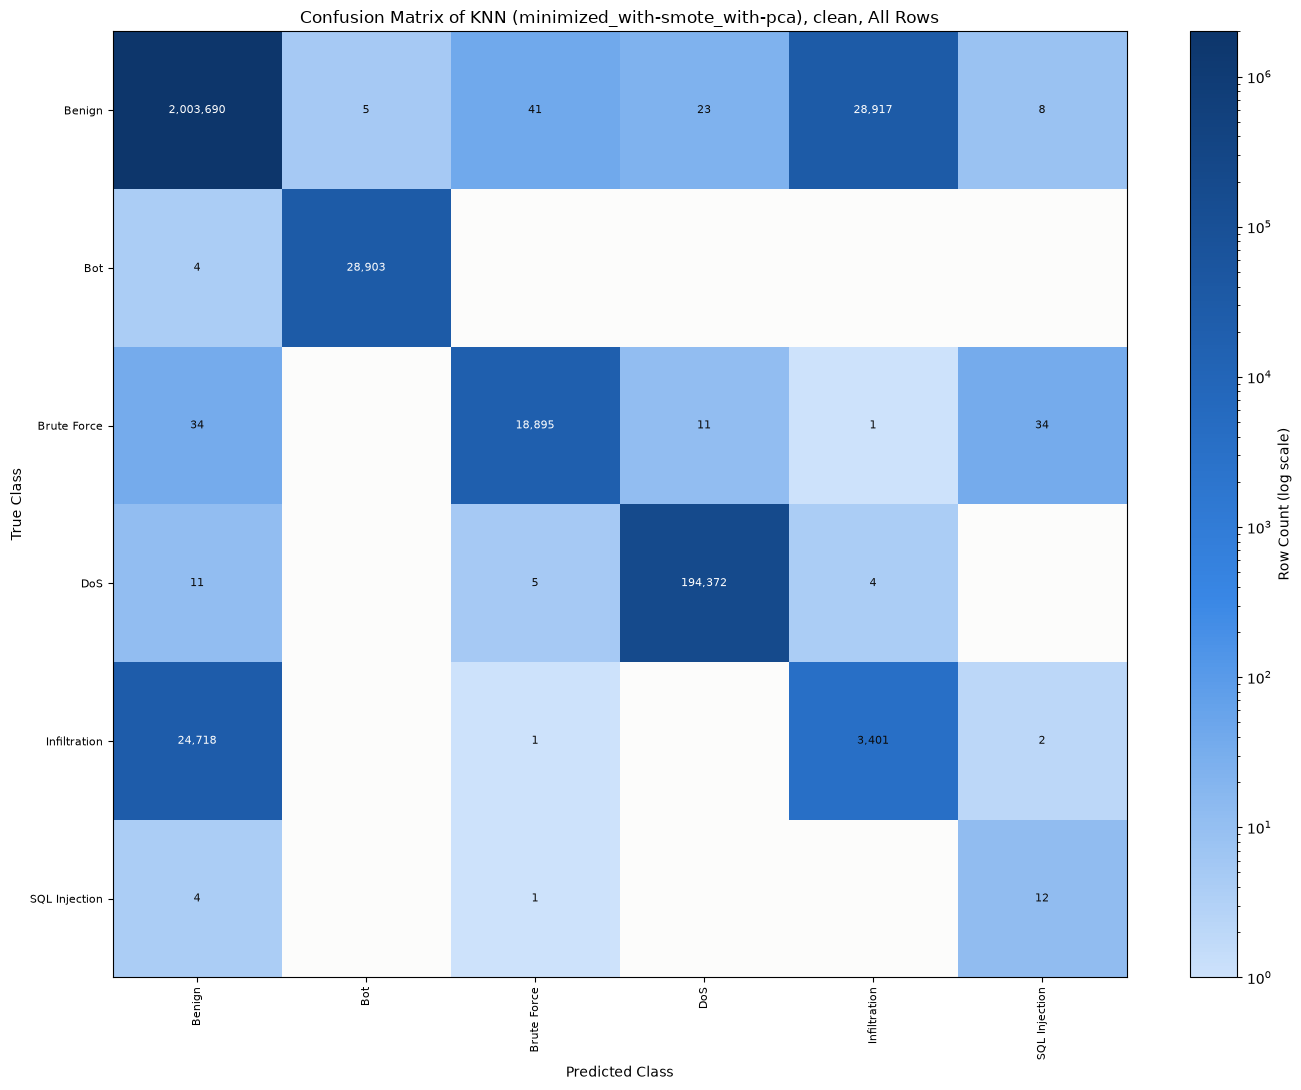

Plotting confusion matrices |██████------------------------| 13/65 (20%) | 00:00:55 elapsed, ~00:03:41 left

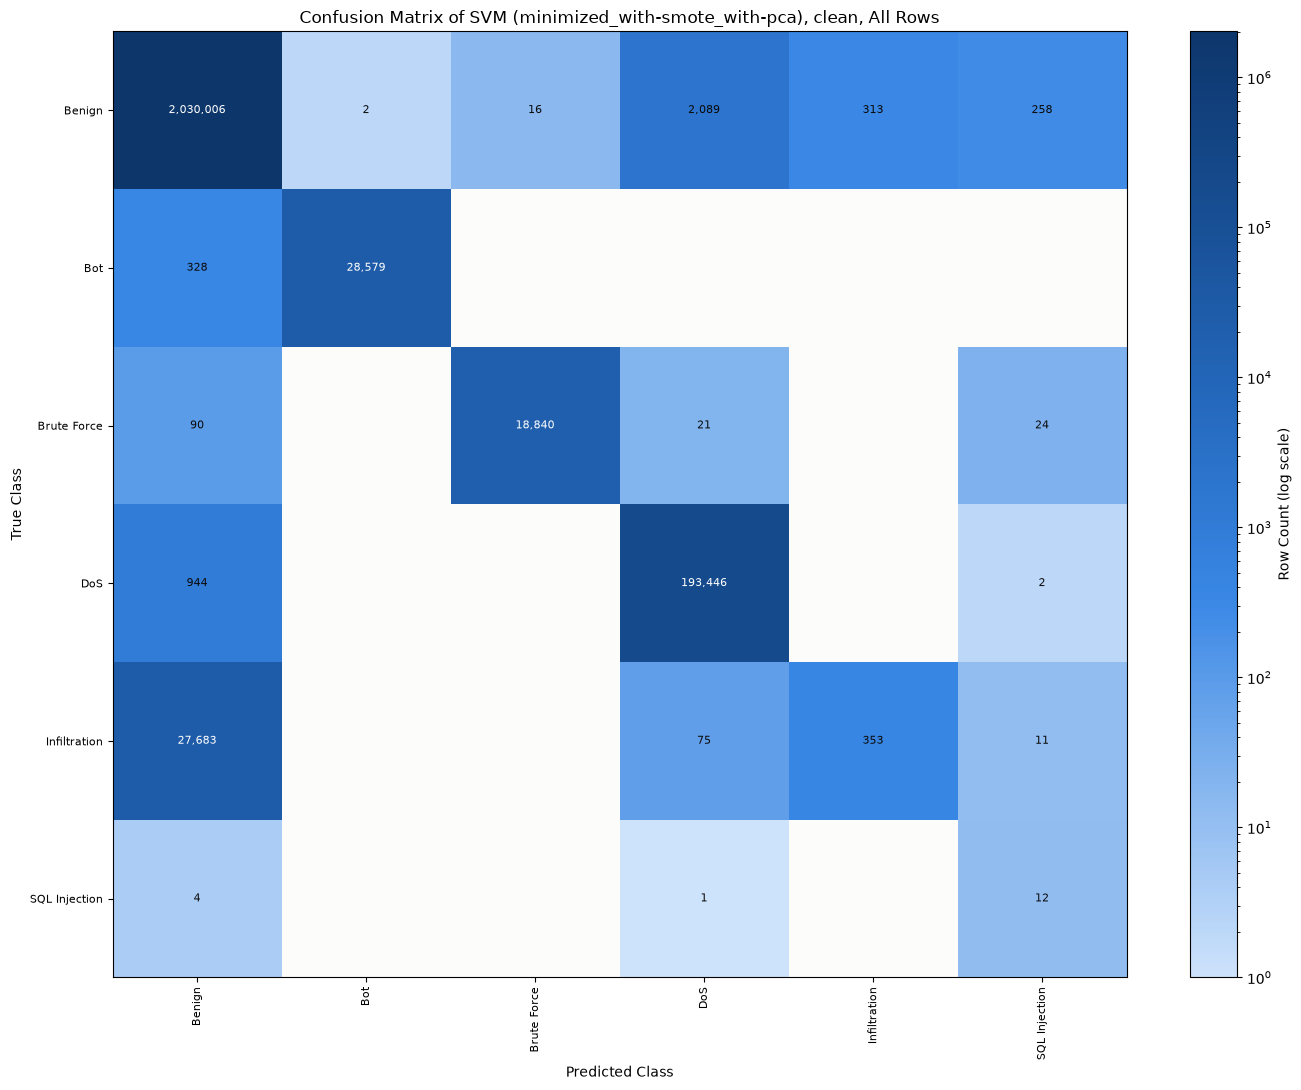

Plotting confusion matrices |████████████------------------| 26/65 (40%) | 00:01:33 elapsed, ~00:02:20 left

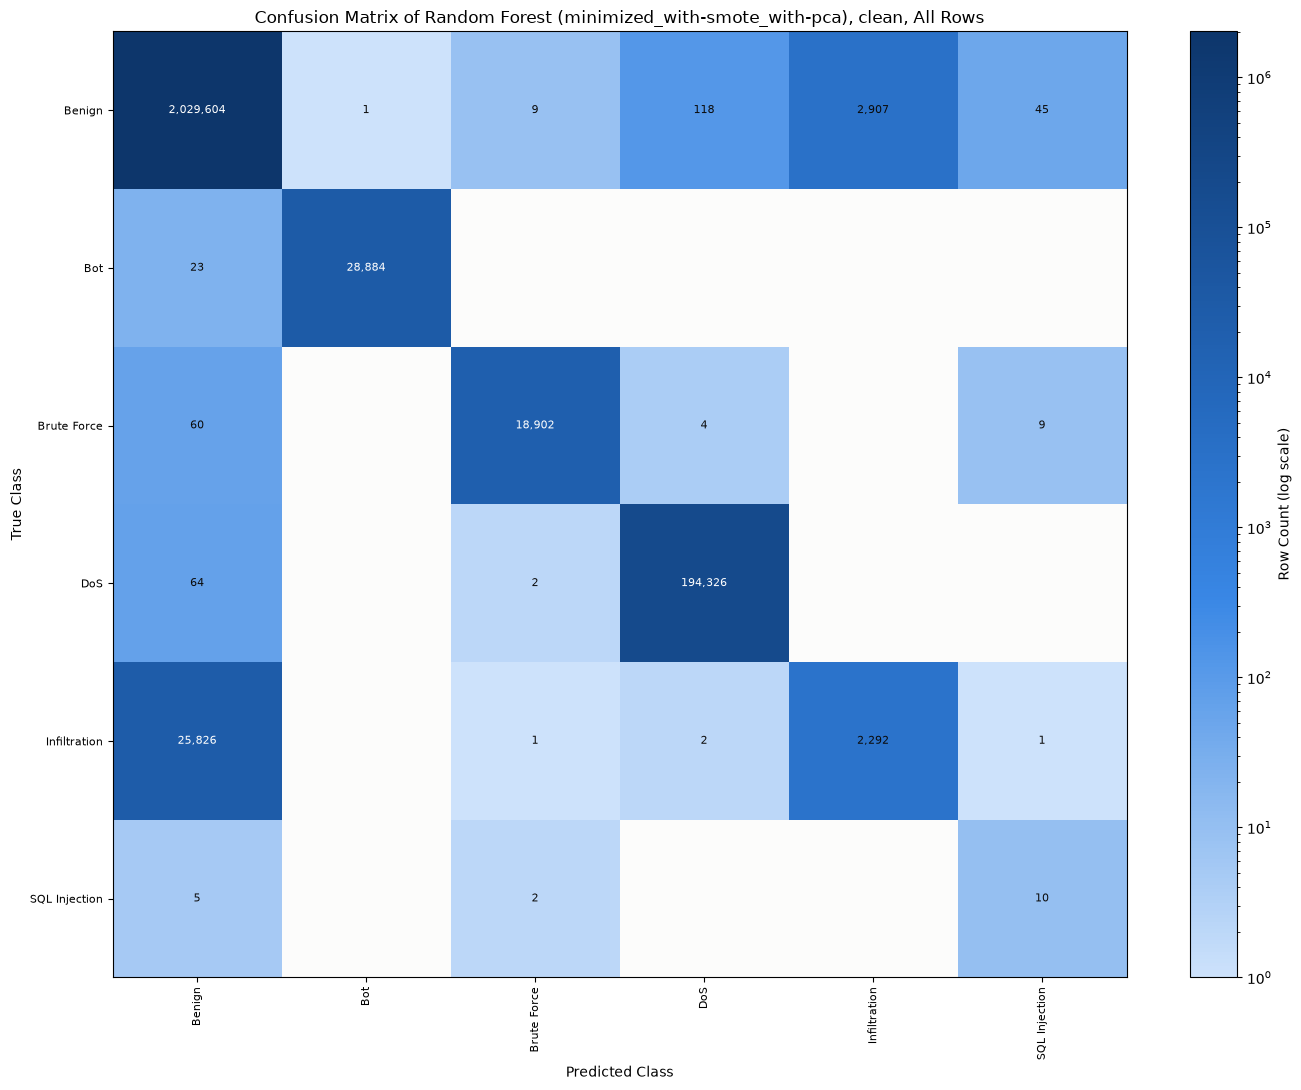

Plotting confusion matrices |██████████████████------------| 39/65 (60%) | 00:02:08 elapsed, ~00:01:25 left

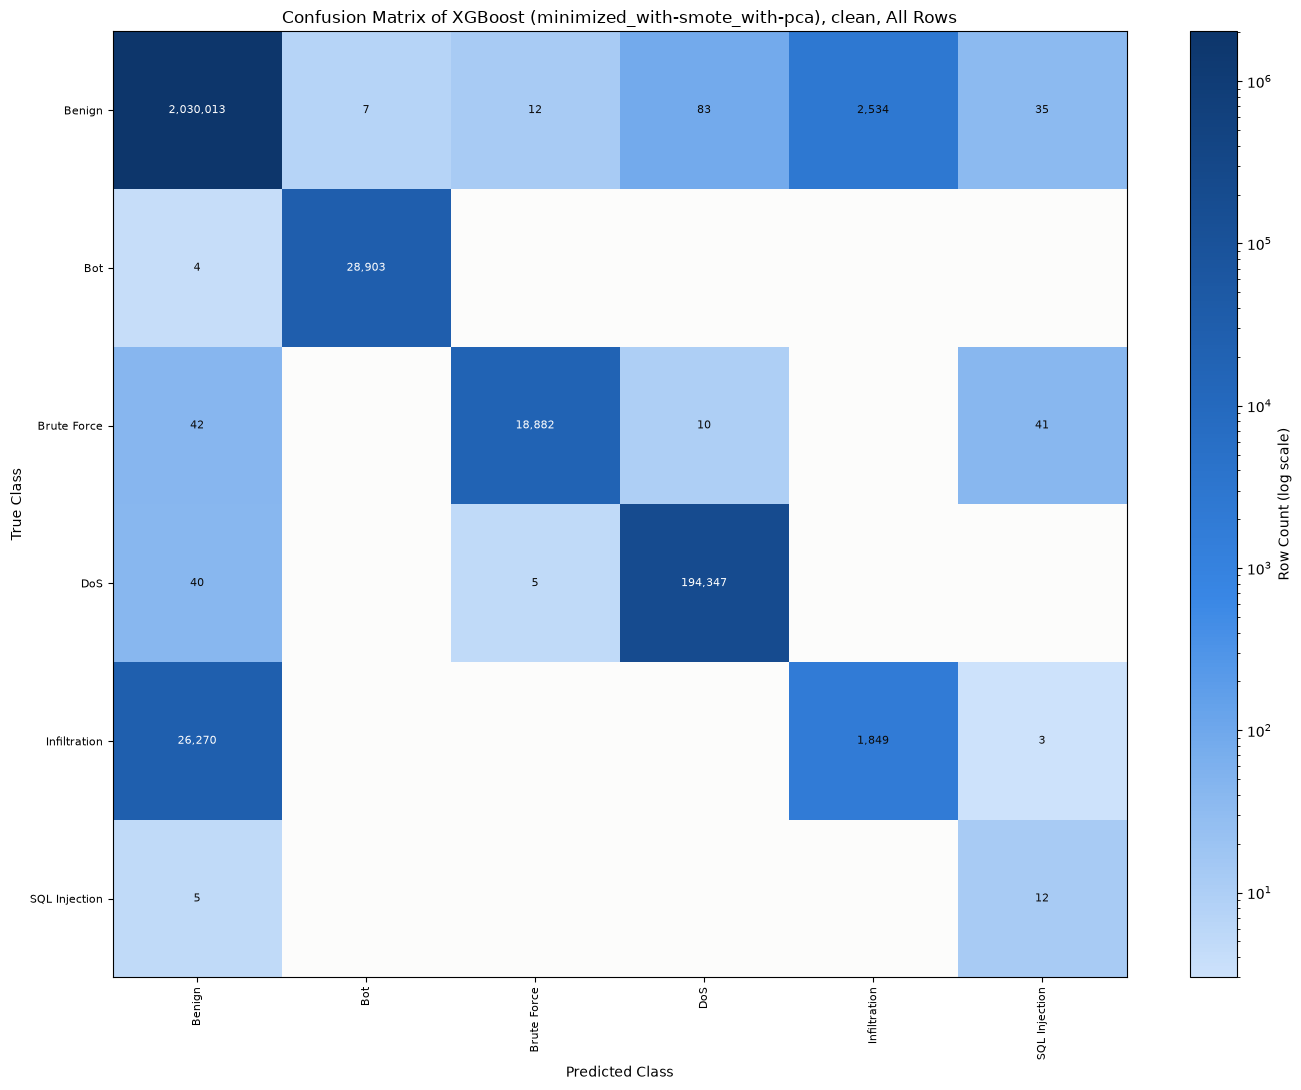

Plotting confusion matrices |████████████████████████------| 52/65 (80%) | 00:02:42 elapsed, ~00:00:40 left

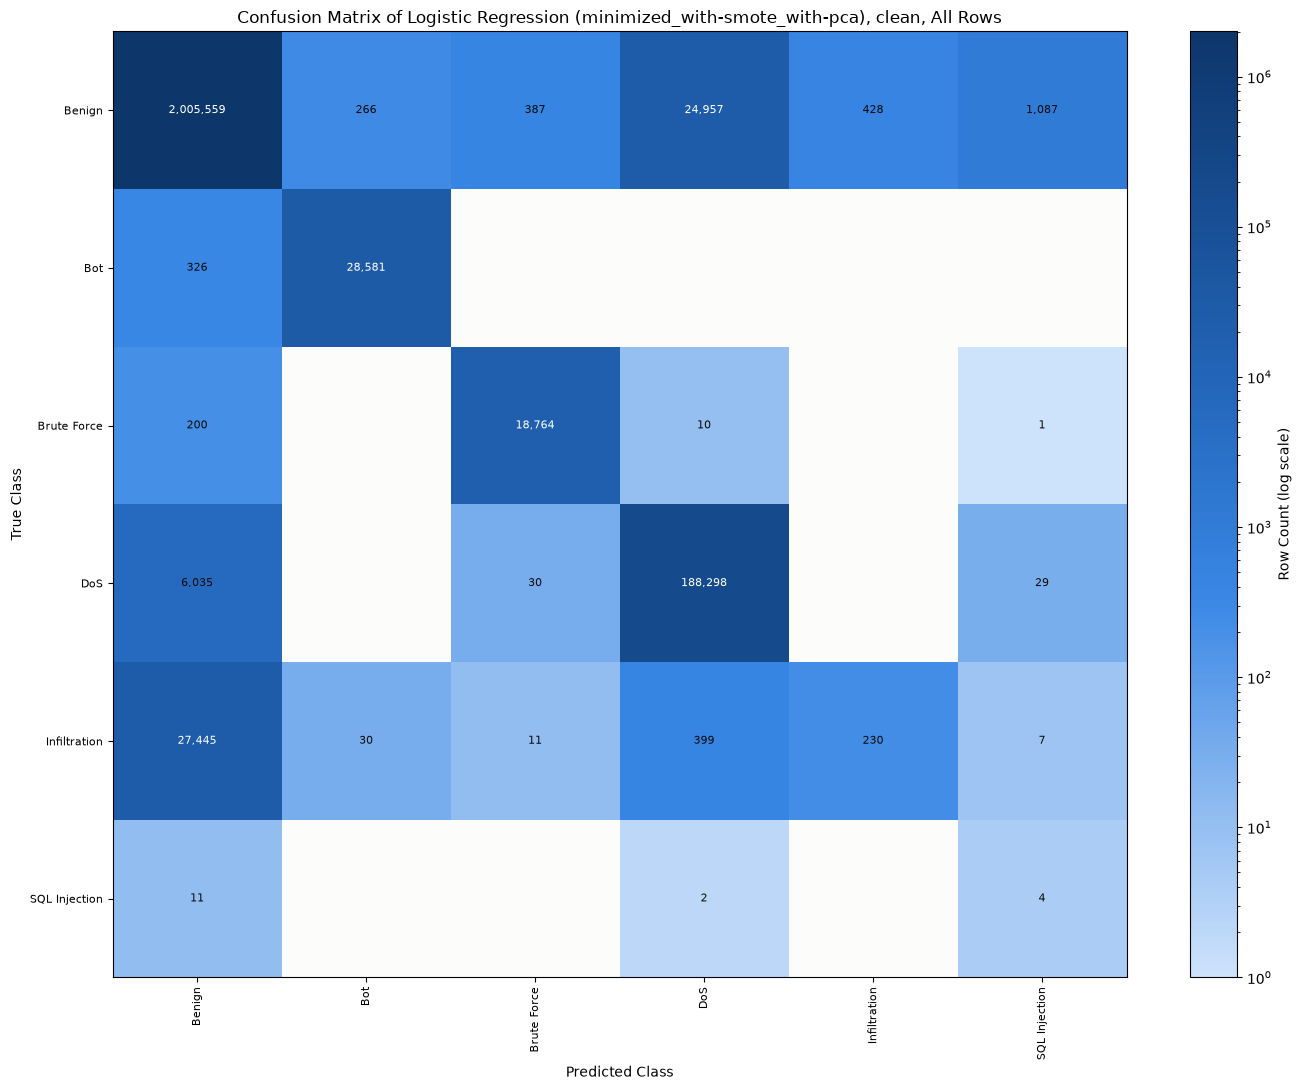

Saved the confusion matrices of 65 predictions to evaluation/minimized_with-smote_with-pca/matrices:03 left


In [299]:
if SAVE_MATRIX_PLOTS:
    plot_every_matrix(outcomes, class_names)

### Prediction Cost

In [300]:
prediction_summaries = load_prediction_summaries()
save_evaluation_table(prediction_summaries, PREDICTION_SUMMARIES_FILE_NAME)
display(prediction_summaries[prediction_summaries[SCENARIO_COLUMN] == CLEAN_SCENARIO].round(4))
display(
    prediction_summaries.pivot_table(
        index=[EXPERIMENT_COLUMN, MODEL_COLUMN],
        columns=SCENARIO_COLUMN,
        values="predict_seconds",
    ).reindex(columns=list_scenario_names()).round(2)
)

,experiment,model,scenario,rows,noisy_rows,transform_seconds,predict_seconds,has_confidence,dataset_fingerprint,prediction_batch_size,...,param_rf__n_estimators,param_rf__max_depth,param_rf__max_features,param_xgb__n_estimators,param_xgb__max_depth,param_xgb__learning_rate,param_xgb__colsample_bytree,param_logreg__C,param_logreg__penalty,rows_per_second
0,minimized_with-smote_with-pca,knn,clean,2303097,0,1.0693,609.9790,True,f03efb2ccfcd7f56821e91d962918510a5cc06f3edae39...,250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.775699e+03
13,minimized_with-smote_with-pca,svm,clean,2303097,0,1.6891,41.6880,False,f03efb2ccfcd7f56821e91d962918510a5cc06f3edae39...,250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.524600e+04
26,minimized_with-smote_with-pca,rf,clean,2303097,0,0.9777,11.9596,True,f03efb2ccfcd7f56821e91d962918510a5cc06f3edae39...,250000,...,300.0,24.0,log2,NaN,NaN,NaN,NaN,NaN,NaN,1.925724e+05
39,minimized_with-smote_with-pca,xgb,clean,2303097,0,0.8827,2.2818,True,f03efb2ccfcd7f56821e91d962918510a5cc06f3edae39...,250000,...,NaN,NaN,NaN,400.0,10.0,0.3,1.0,NaN,NaN,1.009354e+06
52,minimized_with-smote_with-pca,logreg,clean,2303097,0,1.1295,0.6696,True,f03efb2ccfcd7f56821e91d962918510a5cc06f3edae39...,250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,l2,3.439306e+06


scenario                               clean  gaussian-10  gaussian-20  \
experiment                    model                                      
minimized_with-smote_with-pca knn     609.98       610.74       610.53   
                              logreg    0.67         0.46         0.46   
                              rf       11.96        13.21        12.59   
                              svm      41.69        41.54        41.43   
                              xgb       2.28         2.27         2.23   

scenario                              gaussian-30  uniform-10  uniform-20  \
experiment                    model                                         
minimized_with-smote_with-pca knn          611.09      611.21      611.12   
                              logreg         0.46        0.46        0.48   
                              rf            13.39       12.97       12.41   
                              svm           41.11       41.32       40.97   
                              xgb            2.16        2.11        2.08   

scenario                              uniform-30  multiplicative-10  \
experiment                    model                                   
minimized_with-smote_with-pca knn         611.11             611.18   
                              logreg        0.50               0.46   
                              rf           12.39              13.17   
                              svm          41.25              40.94   
                              xgb           2.15               2.04   

scenario                              multiplicative-20  multiplicative-30  \
experiment                    model                                          
minimized_with-smote_with-pca knn                611.09             611.21   
                              logreg               0.49               0.48   
                              rf                  12.91              13.04   
                              svm                 41.24              40.92   
                              xgb                  2.05               2.14   

scenario                              missing-10  missing-20  missing-30  
experiment                    model                                       
minimized_with-smote_with-pca knn         610.94      611.37      611.15  
                              logreg        0.48        0.48        0.49  
                              rf           13.51       12.48       12.06  
                              svm          41.30       41.01       41.24  
                              xgb           2.07        2.11        2.05

### Key Findings

In [301]:
key_findings = find_key_findings(metrics, degradation, class_metrics, mixture_check)
save_evaluation_table(key_findings, KEY_FINDINGS_FILE_NAME)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(key_findings.round(4))

,finding,answer,value
0,Highest clean F1-score (macro),KNN,0.7374
1,"Most robust model, all rows (mean retention)",SVM,0.9065
2,"Least robust model, all rows (mean retention)",Logistic Regression,0.7482
3,"Hardest scenario, all rows (mean retention)",gaussian-30,0.7717
4,"Most damaging noise type, all rows (mean retention)",uniform,0.8341
5,"Most robust model, noisy rows (mean retention)",SVM,0.3508
6,"Least robust model, noisy rows (mean retention)",Random Forest,0.2276
7,"Hardest scenario, noisy rows (mean retention)",uniform-20,0.2328
8,"Most damaging noise type, noisy rows (mean retention)",uniform,0.2364
9,Most unstable model on the noisy rows (mean flip rate),Logistic Regression,0.4717
